# Hemophilia A — Final 29-Feature Modeling Notebook

This notebook starts from the **final preprocessed merged 31-column CSV**:

- `mut_id` — grouping/traceability only; never used as a predictor
- `target` — inhibitor outcome (0/1)
- 29 selected predictors — 20 genomic + 9 clinical

No separate MMC2/MMC3 upload or merge is performed in this notebook.

The notebook then performs leakage-safe grouped train/validation/test splitting, model preprocessing,
classical ML, deep learning, exactly 9 stacking ensembles, held-out metrics, confusion matrices,
ROC/PR curves, and explainability with SHAP and LIME.

**SHAP for individual ML/DL models is shown at the original-feature level**, using the 29 feature
names instead of displaying thousands of one-hot columns.

Run the cells from top to bottom.


In [1]:
# ============================================================
# 1. INSTALL / IMPORTS
# ============================================================
import sys, subprocess, os, gc, random, warnings
warnings.filterwarnings("ignore")

packages = ["xgboost", "catboost", "imbalanced-learn"]
for package in packages:
    module = "imblearn" if package == "imbalanced-learn" else package
    try:
        __import__(module)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score,
    balanced_accuracy_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix,
    brier_score_loss
)
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

try:
    OHE = OneHotEncoder(handle_unknown="ignore", min_frequency=2, sparse_output=True)
    OHE_DENSE = OneHotEncoder(handle_unknown="ignore", min_frequency=2, sparse_output=False)
except TypeError:
    OHE = OneHotEncoder(handle_unknown="ignore", min_frequency=2, sparse=True)
    OHE_DENSE = OneHotEncoder(handle_unknown="ignore", min_frequency=2, sparse=False)

print("Imports ready.")
print("Random seed:", RANDOM_STATE)


Imports ready.
Random seed: 42


In [2]:
# ============================================================
# 2. LOAD THE FINAL PREPROCESSED MERGED DATASET
# ============================================================
# Upload ONLY ONE file:
#     HemophiliaA_Preprocessed_Merged.csv
# It already contains mut_id + target + the 29 selected features.
# No separate MMC2 / MMC3 upload is needed here.

try:
    from google.colab import files

    print("Upload the FINAL PREPROCESSED MERGED CSV (31 columns).")
    uploaded = files.upload()

    if not uploaded:
        raise RuntimeError("No CSV was uploaded.")

    MERGED_FILE = next(iter(uploaded))

except ImportError:
    MERGED_FILE = input(
        "Path to final preprocessed merged CSV: "
    ).strip()

if not MERGED_FILE:
    raise ValueError("A CSV file path is required.")

merged = pd.read_csv(MERGED_FILE)

print("Loaded:", MERGED_FILE)
print("Shape:", merged.shape)
print("Columns:", len(merged.columns))
print("\nColumn names:")
print(merged.columns.tolist())


Upload the FINAL PREPROCESSED MERGED CSV (31 columns).


Saving HemophiliaA_Preprocessed_Merged.csv to HemophiliaA_Preprocessed_Merged.csv
Loaded: HemophiliaA_Preprocessed_Merged.csv
Shape: (4962, 31)
Columns: 31

Column names:
['mut_id', 'target', 'mut_type', 'mut_effect', 'location', 'e_i_numb', 'locnumb', 'aa_numb_old', 'aa_numb', 'codon_change', 'codon_first', 'codon_last', 'n_bp', 'nuc_numb', 'ntchange', 'mut_syn', 'aa_change', 'aa_first', 'aa_last', 'aa_syn', 'CpG', 'utype', 'clotting', 'discrep', 'ratio', 'assay', 'antigen', 'act/ant', 'type', 'pa_race', 'cli_phe']


In [3]:
# ============================================================
# 3. VALIDATE THE FINAL MERGED DATASET
# ============================================================

GENOMIC_FEATURES = [
    "mut_type",
    "mut_effect",
    "location",
    "e_i_numb",
    "locnumb",
    "aa_numb_old",
    "aa_numb",
    "codon_change",
    "codon_first",
    "codon_last",
    "n_bp",
    "nuc_numb",
    "ntchange",
    "mut_syn",
    "aa_change",
    "aa_first",
    "aa_last",
    "aa_syn",
    "CpG",
    "utype",
]

CLINICAL_FEATURES = [
    "clotting",
    "discrep",
    "ratio",
    "assay",
    "antigen",
    "act/ant",
    "type",
    "pa_race",
    "cli_phe",
]

MERGED_FEATURES = GENOMIC_FEATURES + CLINICAL_FEATURES

required = ["mut_id", "target"] + MERGED_FEATURES
missing = [c for c in required if c not in merged.columns]

if missing:
    raise KeyError(
        "The supplied merged CSV is missing these required columns:\n"
        + "\n".join(missing)
    )

if len(MERGED_FEATURES) != 29:
    raise RuntimeError(
        f"Expected exactly 29 predictors, found {len(MERGED_FEATURES)}."
    )

# Keep only the intended variables.
merged = merged[required].copy()

# Clean column names and string values.
merged.columns = merged.columns.str.strip()

for c in merged.select_dtypes(include="object").columns:
    merged[c] = merged[c].astype("string").str.strip()

# Target must already be 0/1.
merged["target"] = pd.to_numeric(
    merged["target"],
    errors="coerce"
)

before = len(merged)
merged = merged.dropna(
    subset=["mut_id", "target"]
).reset_index(drop=True)
merged["target"] = merged["target"].astype(int)

if not set(merged["target"].unique()).issubset({0, 1}):
    raise ValueError("target must contain only 0 and 1.")

print("=" * 90)
print("FINAL MERGED DATASET CHECK")
print("=" * 90)
print("Rows:", len(merged))
print("Original columns after selection:", len(required))
print("Predictor columns:", len(MERGED_FEATURES))
print("Genomic predictors:", len(GENOMIC_FEATURES))
print("Clinical predictors:", len(CLINICAL_FEATURES))
print("Removed rows with missing mut_id/target:", before - len(merged))
print("\nTarget distribution:")
print(merged["target"].value_counts().sort_index())

print("\n✓ Exactly 29 predictors are being used.")
print("✓ mut_id is retained only for grouping/traceability.")


FINAL MERGED DATASET CHECK
Rows: 4962
Original columns after selection: 31
Predictor columns: 29
Genomic predictors: 20
Clinical predictors: 9
Removed rows with missing mut_id/target: 0

Target distribution:
target
0    4126
1     836
Name: count, dtype: int64

✓ Exactly 29 predictors are being used.
✓ mut_id is retained only for grouping/traceability.


In [4]:
# ============================================================
# 4. FEATURE BLOCK SUMMARY
# ============================================================

DATASETS = {
    "Genomic": GENOMIC_FEATURES,
    "Clinical": CLINICAL_FEATURES,
    "Merged": MERGED_FEATURES,
}

for name, cols in DATASETS.items():
    print(
        f"{name:<10} -> {len(cols):2d} predictors"
    )

print("\nGenomic features:")
print(GENOMIC_FEATURES)

print("\nClinical features:")
print(CLINICAL_FEATURES)

print("\nMerged features:")
print(MERGED_FEATURES)


Genomic    -> 20 predictors
Clinical   ->  9 predictors
Merged     -> 29 predictors

Genomic features:
['mut_type', 'mut_effect', 'location', 'e_i_numb', 'locnumb', 'aa_numb_old', 'aa_numb', 'codon_change', 'codon_first', 'codon_last', 'n_bp', 'nuc_numb', 'ntchange', 'mut_syn', 'aa_change', 'aa_first', 'aa_last', 'aa_syn', 'CpG', 'utype']

Clinical features:
['clotting', 'discrep', 'ratio', 'assay', 'antigen', 'act/ant', 'type', 'pa_race', 'cli_phe']

Merged features:
['mut_type', 'mut_effect', 'location', 'e_i_numb', 'locnumb', 'aa_numb_old', 'aa_numb', 'codon_change', 'codon_first', 'codon_last', 'n_bp', 'nuc_numb', 'ntchange', 'mut_syn', 'aa_change', 'aa_first', 'aa_last', 'aa_syn', 'CpG', 'utype', 'clotting', 'discrep', 'ratio', 'assay', 'antigen', 'act/ant', 'type', 'pa_race', 'cli_phe']


In [5]:
# ============================================================
# 5. GROUPED DATA SPLIT — IDENTICAL SPLIT FOR ALL BLOCKS
# ============================================================
# IMPORTANT:
# We split the actual merged rows while using mut_id ONLY as
# the grouping variable.
#
# DO NOT create a one-row-per-mut_id mutation_table here.
# Some mut_id groups have multiple clinical records and may
# contain different target values. That is allowed.
#
# The ONLY requirement is:
#   - all rows belonging to the same mut_id stay in one split
#   - no mut_id occurs across train / validation / test
#
# This follows the grouped split structure used in the original
# V9 benchmark notebook.

# ------------------------------------------------------------
# 5.1 Basic checks
# ------------------------------------------------------------

required_cols = ["mut_id", "target"]

missing_cols = [
    c for c in required_cols
    if c not in merged.columns
]

if missing_cols:
    raise KeyError(
        f"Missing required columns in merged: {missing_cols}"
    )

# Remove rows where the grouping ID or target is missing.
# This does NOT remove conflicting-label mutation groups.
split_data = merged.dropna(
    subset=["mut_id", "target"]
).reset_index(drop=True)

print("Rows available for grouped split:", len(split_data))
print(
    "Unique mut_id groups:",
    split_data["mut_id"].nunique()
)

print("\nTarget distribution:")
print(split_data["target"].value_counts(dropna=False))

# ------------------------------------------------------------
# 5.2 Define X, y and GROUPS
# ------------------------------------------------------------

# Keep the complete row-level target.
y = split_data["target"].astype(int).reset_index(drop=True)

# mut_id is used ONLY for grouping.
groups = split_data["mut_id"].reset_index(drop=True)

# IMPORTANT:
# Do not use mut_id as a predictive feature.
#
# The actual feature columns are determined later for each
# Genomic / Clinical / Merged block.
X = split_data.drop(
    columns=["target"],
    errors="ignore"
).reset_index(drop=True)

# ------------------------------------------------------------
# 5.3 FIRST SPLIT: TRAIN+VALIDATION / TEST
# ------------------------------------------------------------

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE
)

trainval_idx, test_idx = next(
    gss.split(
        X,
        y,
        groups=groups
    )
)

X_trainval = X.iloc[trainval_idx].reset_index(drop=True)
y_trainval = y.iloc[trainval_idx].reset_index(drop=True)
g_trainval = groups.iloc[trainval_idx].reset_index(drop=True)

X_test = X.iloc[test_idx].reset_index(drop=True)
y_test = y.iloc[test_idx].reset_index(drop=True)
g_test = groups.iloc[test_idx].reset_index(drop=True)

# ------------------------------------------------------------
# 5.4 SECOND SPLIT: TRAIN / VALIDATION
# ------------------------------------------------------------

gss2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE + 1
)

tr_idx, val_idx = next(
    gss2.split(
        X_trainval,
        y_trainval,
        groups=g_trainval
    )
)

X_train = X_trainval.iloc[tr_idx].reset_index(drop=True)
y_train = y_trainval.iloc[tr_idx].reset_index(drop=True)
g_train = g_trainval.iloc[tr_idx].reset_index(drop=True)

X_val = X_trainval.iloc[val_idx].reset_index(drop=True)
y_val = y_trainval.iloc[val_idx].reset_index(drop=True)
g_val = g_trainval.iloc[val_idx].reset_index(drop=True)

# ------------------------------------------------------------
# 5.5 GROUP LEAKAGE CHECK
# ------------------------------------------------------------

train_groups = set(g_train.unique())
val_groups = set(g_val.unique())
test_groups = set(g_test.unique())

train_val_overlap = train_groups & val_groups
train_test_overlap = train_groups & test_groups
val_test_overlap = val_groups & test_groups

print("\n" + "=" * 70)
print("GROUPED SPLIT RESULTS")
print("=" * 70)

print("\nRows:")
print("  Train      :", len(X_train))
print("  Validation :", len(X_val))
print("  Test       :", len(X_test))

print("\nUnique mut_id groups:")
print("  Train      :", len(train_groups))
print("  Validation :", len(val_groups))
print("  Test       :", len(test_groups))

print("\nGroup overlaps:")
print("  Train-Val  :", len(train_val_overlap))
print("  Train-Test :", len(train_test_overlap))
print("  Val-Test   :", len(val_test_overlap))

# ------------------------------------------------------------
# 5.6 HARD LEAKAGE ASSERTION
# ------------------------------------------------------------

if train_val_overlap:
    raise RuntimeError(
        f"Group leakage detected between TRAIN and VAL: "
        f"{len(train_val_overlap)} mut_id groups."
    )

if train_test_overlap:
    raise RuntimeError(
        f"Group leakage detected between TRAIN and TEST: "
        f"{len(train_test_overlap)} mut_id groups."
    )

if val_test_overlap:
    raise RuntimeError(
        f"Group leakage detected between VAL and TEST: "
        f"{len(val_test_overlap)} mut_id groups."
    )

print("\n✓ TRAIN / VAL / TEST mutation groups are completely disjoint.")

# ------------------------------------------------------------
# 5.7 CONFLICTING-LABEL INFORMATION
# ------------------------------------------------------------
# We report this for transparency, but DO NOT remove these
# groups. A mutation can have multiple clinical records.
#
# The grouping constraint above is what prevents the same
# mutation from appearing in different partitions.

label_counts = (
    split_data
    .groupby("mut_id")["target"]
    .nunique()
)

conflicting_groups = label_counts[
    label_counts > 1
].index

print("\nConflicting-label mutation groups:")
print(" ", len(conflicting_groups))

if len(conflicting_groups) > 0:
    print(
        "✓ Conflicting labels are retained inside their "
        "respective mutation groups."
    )

# ------------------------------------------------------------
# 5.8 TARGET DISTRIBUTION BY SPLIT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TARGET DISTRIBUTION BY SPLIT")
print("=" * 70)

def show_distribution(name, labels):
    counts = labels.value_counts().sort_index()
    total = len(labels)

    print(f"\n{name}")
    for cls, count in counts.items():
        print(
            f"  Class {cls}: {count:5d} "
            f"({count / total:.2%})"
        )

show_distribution("TRAIN", y_train)
show_distribution("VALIDATION", y_val)
show_distribution("TEST", y_test)

# ------------------------------------------------------------
# 5.9 FINAL SANITY CHECK
# ------------------------------------------------------------

assert len(X_train) == len(y_train) == len(g_train)
assert len(X_val) == len(y_val) == len(g_val)
assert len(X_test) == len(y_test) == len(g_test)

assert len(train_groups & val_groups) == 0
assert len(train_groups & test_groups) == 0
assert len(val_groups & test_groups) == 0

print("\n" + "=" * 70)
print("✓ GROUPED SPLIT CELL COMPLETED SUCCESSFULLY")
print("=" * 70)

Rows available for grouped split: 4962
Unique mut_id groups: 2639

Target distribution:
target
0    4126
1     836
Name: count, dtype: int64

GROUPED SPLIT RESULTS

Rows:
  Train      : 3124
  Validation : 812
  Test       : 1026

Unique mut_id groups:
  Train      : 1688
  Validation : 423
  Test       : 528

Group overlaps:
  Train-Val  : 0
  Train-Test : 0
  Val-Test   : 0

✓ TRAIN / VAL / TEST mutation groups are completely disjoint.

Conflicting-label mutation groups:
  124
✓ Conflicting labels are retained inside their respective mutation groups.

TARGET DISTRIBUTION BY SPLIT

TRAIN
  Class 0:  2599 (83.19%)
  Class 1:   525 (16.81%)

VALIDATION
  Class 0:   670 (82.51%)
  Class 1:   142 (17.49%)

TEST
  Class 0:   857 (83.53%)
  Class 1:   169 (16.47%)

✓ GROUPED SPLIT CELL COMPLETED SUCCESSFULLY


In [6]:
# ============================================================
# 6. PREPARE FEATURE BLOCKS
# ============================================================
# IMPORTANT:
# - Keep ALL rows belonging to each mut_id.
# - Do NOT drop_duplicates("mut_id").
# - The train / validation / test assignment comes from Cell 5.
# - mut_id is used only to preserve group membership.
# - The exact same row/group split is reused for Genomic,
#   Clinical and Merged feature blocks.

# ------------------------------------------------------------
# 6.1 Build the row indices from Cell 5
# ------------------------------------------------------------

train_row_ids = set(X_train.index)
val_row_ids   = set(X_val.index)
test_row_ids  = set(X_test.index)

# Since X_train/X_val/X_test were reset_index() in Cell 5,
# the safest way is to use their mut_id group vectors.
train_groups = set(g_train.unique())
val_groups   = set(g_val.unique())
test_groups  = set(g_test.unique())

# ------------------------------------------------------------
# 6.2 Feature-block constructor
# ------------------------------------------------------------

def make_block(feature_list):

    missing_features = [
        c for c in feature_list
        if c not in split_data.columns
    ]

    if missing_features:
        raise KeyError(
            f"Missing features: {missing_features}"
        )

    # Start from the SAME row-level data used in Cell 5.
    d = split_data[
        ["mut_id", "target"] + feature_list
    ].copy()

    # --------------------------------------------------------
    # Assign rows using mut_id groups.
    # --------------------------------------------------------
    train_mask = d["mut_id"].isin(train_groups)
    val_mask   = d["mut_id"].isin(val_groups)
    test_mask  = d["mut_id"].isin(test_groups)

    train = d.loc[train_mask].reset_index(drop=True)
    val   = d.loc[val_mask].reset_index(drop=True)
    test  = d.loc[test_mask].reset_index(drop=True)

    # --------------------------------------------------------
    # Sanity checks
    # --------------------------------------------------------

    if set(train["mut_id"]) != train_groups:
        raise RuntimeError(
            "TRAIN mut_id groups do not match Cell 5."
        )

    if set(val["mut_id"]) != val_groups:
        raise RuntimeError(
            "VALIDATION mut_id groups do not match Cell 5."
        )

    if set(test["mut_id"]) != test_groups:
        raise RuntimeError(
            "TEST mut_id groups do not match Cell 5."
        )

    # No group may occur in more than one split.
    assert set(train["mut_id"]).isdisjoint(
        set(val["mut_id"])
    )

    assert set(train["mut_id"]).isdisjoint(
        set(test["mut_id"])
    )

    assert set(val["mut_id"]).isdisjoint(
        set(test["mut_id"])
    )

    return (
        train[feature_list].copy(),
        train["target"].copy(),
        train["mut_id"].copy(),

        val[feature_list].copy(),
        val["target"].copy(),
        val["mut_id"].copy(),

        test[feature_list].copy(),
        test["target"].copy(),
        test["mut_id"].copy()
    )


# ------------------------------------------------------------
# 6.3 Dataset definitions
# ------------------------------------------------------------

DATASETS = {
    "Genomic": GENOMIC_FEATURES,
    "Clinical": CLINICAL_FEATURES,
    "Merged": MERGED_FEATURES
}


# ------------------------------------------------------------
# 6.4 Create all blocks using the SAME grouped split
# ------------------------------------------------------------

blocks = {}

for dataset_name, feature_list in DATASETS.items():

    blocks[dataset_name] = make_block(
        feature_list
    )

    (
        Xtr, ytr, gtr,
        Xva, yva, gva,
        Xte, yte, gte
    ) = blocks[dataset_name]

    print(
        f"{dataset_name:<10} "
        f"train={len(Xtr):5d} "
        f"val={len(Xva):5d} "
        f"test={len(Xte):5d} "
        f"features={len(feature_list):3d}"
    )


# ------------------------------------------------------------
# 6.5 Verify identical GROUP partitions
# ------------------------------------------------------------

for dataset_name, b in blocks.items():

    (
        Xtr, ytr, gtr,
        Xva, yva, gva,
        Xte, yte, gte
    ) = b

    assert set(gtr) == train_groups
    assert set(gva) == val_groups
    assert set(gte) == test_groups

    assert set(gtr).isdisjoint(set(gva))
    assert set(gtr).isdisjoint(set(gte))
    assert set(gva).isdisjoint(set(gte))


# ------------------------------------------------------------
# 6.6 Final confirmation
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FEATURE BLOCK PREPARATION COMPLETE")
print("=" * 70)

print(
    f"\nTrain groups      : {len(train_groups)}"
)

print(
    f"Validation groups : {len(val_groups)}"
)

print(
    f"Test groups       : {len(test_groups)}"
)

print(
    "\n✓ Genomic, Clinical and Merged use the SAME "
    "mut_id group partition."
)

print(
    "✓ No mut_id appears across different splits."
)

print(
    "✓ Repeated clinical rows are retained."
)

print(
    "✓ No mutation-level deduplication was performed."
)

Genomic    train= 3124 val=  812 test= 1026 features= 20
Clinical   train= 3124 val=  812 test= 1026 features=  9
Merged     train= 3124 val=  812 test= 1026 features= 29

FEATURE BLOCK PREPARATION COMPLETE

Train groups      : 1688
Validation groups : 423
Test groups       : 528

✓ Genomic, Clinical and Merged use the SAME mut_id group partition.
✓ No mut_id appears across different splits.
✓ Repeated clinical rows are retained.
✓ No mutation-level deduplication was performed.


In [7]:
# ============================================================
# 7. LEAKAGE-SAFE PREPROCESSING — ROBUST NA HANDLING
# ============================================================
def _safe_feature_frame(X):
    """
    Convert pandas nullable/string/category columns to sklearn-safe
    dtypes and convert missing values to np.nan.

    This specifically prevents:
        TypeError: boolean value of NA is ambiguous
    """
    X = X.copy()

    for c in X.columns:
        if (
            pd.api.types.is_object_dtype(X[c])
            or pd.api.types.is_string_dtype(X[c])
            or pd.api.types.is_categorical_dtype(X[c])
            or pd.api.types.is_bool_dtype(X[c])
        ):
            X[c] = X[c].astype(object)

            # Convert every missing value (pd.NA / NaN / None) to np.nan.
            X[c] = X[c].where(pd.notna(X[c]), np.nan)

    return X


def make_preprocessor(Xref, dense=False):
    Xref = _safe_feature_frame(Xref)

    num = Xref.select_dtypes(
        include=[np.number]
    ).columns.tolist()

    cat = [
        c for c in Xref.columns
        if c not in num
    ]

    num_pipe = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ])

    cat_pipe = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "onehot",
            OHE_DENSE if dense else OHE
        )
    ])

    transformers = []

    if num:
        transformers.append(
            ("num", num_pipe, num)
        )

    if cat:
        transformers.append(
            ("cat", cat_pipe, cat)
        )

    return ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )


def make_catboost_frame(Xref):
    """
    CatBoost gets a clean object/string frame with explicit
    '__MISSING__' tokens for categorical missing values.
    """
    Xc = _safe_feature_frame(Xref)
    cat_cols = []

    for c in Xc.columns:
        if (
            not pd.api.types.is_numeric_dtype(Xc[c])
        ):
            cat_cols.append(c)
            Xc[c] = Xc[c].fillna(
                "__MISSING__"
            ).astype(str)

    return Xc, cat_cols

print("✓ Robust preprocessing functions loaded.")
print("✓ pandas NA values will be converted to np.nan before sklearn.")


✓ Robust preprocessing functions loaded.
✓ pandas NA values will be converted to np.nan before sklearn.


In [8]:
# ============================================================
# 7A. PREPROCESSING SANITY CHECK
# ============================================================
print("=" * 90)
print("PREPROCESSING SANITY CHECK")
print("=" * 90)

for dataset_name, feature_list in DATASETS.items():
    Xtr, ytr, gtr, Xva, yva, gva, Xte, yte, gte = blocks[dataset_name]

    Xtr_safe = _safe_feature_frame(Xtr)
    pre_check = make_preprocessor(Xtr_safe, dense=False)
    A = pre_check.fit_transform(Xtr_safe)

    print(
        f"{dataset_name:<10} "
        f"original_features={len(feature_list):2d} | "
        f"transformed_features={A.shape[1]:5d} | "
        f"rows={A.shape[0]:5d}"
    )

print("\n✓ All three feature blocks can be transformed without NA ambiguity.")


PREPROCESSING SANITY CHECK
Genomic    original_features=20 | transformed_features= 1479 | rows= 3124
Clinical   original_features= 9 | transformed_features=  172 | rows= 3124
Merged     original_features=29 | transformed_features= 1651 | rows= 3124

✓ All three feature blocks can be transformed without NA ambiguity.


In [9]:
# ============================================================
# 8. CLASSICAL ML MODEL FACTORY
# ============================================================
def classical_models(yref):
    yarr = np.asarray(yref)
    pos = max(int((yarr == 1).sum()), 1)
    neg = max(int((yarr == 0).sum()), 1)
    spw = neg / pos

    return {
        "Logistic Regression": LogisticRegression(
            C=0.30, max_iter=4000, class_weight="balanced",
            solver="liblinear", random_state=RANDOM_STATE
        ),

        "Random Forest": RandomForestClassifier(
            n_estimators=900, max_depth=12, min_samples_leaf=2,
            max_features="sqrt", class_weight="balanced_subsample",
            n_jobs=-1, random_state=RANDOM_STATE
        ),

        "Extra Trees": ExtraTreesClassifier(
            n_estimators=900, max_depth=12, min_samples_leaf=2,
            max_features="sqrt", class_weight="balanced",
            n_jobs=-1, random_state=RANDOM_STATE
        ),

        "Gradient Boosting": GradientBoostingClassifier(
            n_estimators=500, learning_rate=0.025, max_depth=2,
            min_samples_leaf=6, subsample=0.85,
            random_state=RANDOM_STATE
        ),

        "HistGradientBoosting": HistGradientBoostingClassifier(
            max_iter=500, learning_rate=0.03, max_leaf_nodes=15,
            min_samples_leaf=12, l2_regularization=2.0,
            random_state=RANDOM_STATE
        ),

        "XGBoost": XGBClassifier(
            n_estimators=700, max_depth=3, learning_rate=0.025,
            subsample=0.85, colsample_bytree=0.85,
            min_child_weight=4, reg_alpha=0.10, reg_lambda=2.0,
            scale_pos_weight=spw,
            objective="binary:logistic", eval_metric="logloss",
            tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE
        ),

        "CatBoost": CatBoostClassifier(
            iterations=900, depth=5, learning_rate=0.025,
            loss_function="Logloss", eval_metric="AUC",
            auto_class_weights="Balanced", l2_leaf_reg=5.0,
            random_seed=RANDOM_STATE, verbose=False,
            allow_writing_files=False, thread_count=-1
        ),

        "CatBoost Unweighted": CatBoostClassifier(
            iterations=900, depth=5, learning_rate=0.025,
            loss_function="Logloss", eval_metric="AUC",
            l2_leaf_reg=5.0, random_seed=RANDOM_STATE + 11,
            verbose=False, allow_writing_files=False, thread_count=-1
        ),

        "SMOTE Random Forest": None
    }

def make_preprocessor_for_smote():
    # SMOTE needs a numeric matrix; sparse output is disabled here.
    num_cols = []
    cat_cols = []
    # Columns are supplied when the pipeline is fitted, so this helper
    # is replaced per dataset by build_smote_pipeline().
    return "placeholder"

print("Classical model factory ready.")


Classical model factory ready.


In [10]:
# ============================================================
# 9. FIT / PREDICT HELPERS
# ============================================================
def build_smote_pipeline(Xfit):
    return ImbPipeline([
        ("preprocess", make_preprocessor(Xfit, dense=True)),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", RandomForestClassifier(
            n_estimators=700, max_depth=12, min_samples_leaf=2,
            max_features="sqrt", class_weight=None,
            n_jobs=-1, random_state=RANDOM_STATE
        ))
    ])

def fit_predict_ml(name, estimator, Xfit, yfit, Xpred):
    if name.startswith("CatBoost"):
        Xf, cats = make_catboost_frame(Xfit)
        Xp, _ = make_catboost_frame(Xpred)
        model = clone(estimator)
        model.fit(Xf, yfit, cat_features=cats)
        prob = model.predict_proba(Xp)[:, 1]
        return np.asarray(prob), model

    if name == "SMOTE Random Forest":
        pipe = build_smote_pipeline(Xfit)
    else:
        dense = name == "HistGradientBoosting"
        pipe = Pipeline([
            ("preprocess", make_preprocessor(Xfit, dense=dense)),
            ("model", clone(estimator))
        ])

    pipe.fit(Xfit, yfit)
    prob = pipe.predict_proba(Xpred)[:, 1]
    return np.asarray(prob), pipe

def best_accuracy_threshold(y_true, prob):
    grid = np.unique(np.r_[
        np.linspace(0.01, 0.99, 395),
        np.quantile(prob, np.linspace(0.01, 0.99, 199))
    ])

    rows = []
    for t in grid:
        pred = (prob >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(
            y_true, pred, labels=[0, 1]
        ).ravel()
        spec = tn / (tn + fp) if (tn + fp) else 0.0

        rows.append({
            "Threshold": float(t),
            "Accuracy": accuracy_score(y_true, pred),
            "Balanced Accuracy": balanced_accuracy_score(y_true, pred),
            "MCC": matthews_corrcoef(y_true, pred),
            "Recall": recall_score(y_true, pred, zero_division=0),
            "Specificity": spec
        })

    df = pd.DataFrame(rows)
    return df.sort_values(
        ["Accuracy", "MCC", "Balanced Accuracy"],
        ascending=False
    ).iloc[0]

def calculate_metrics(y_true, prob, threshold):
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_true, pred, labels=[0, 1]
    ).ravel()

    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "Specificity": tn / (tn + fp) if (tn + fp) else 0.0,
        "F1": f1_score(y_true, pred, zero_division=0),
        "MCC": matthews_corrcoef(y_true, pred),
        "ROC-AUC": roc_auc_score(y_true, prob),
        "PR-AUC": average_precision_score(y_true, prob),
        "Brier": brier_score_loss(y_true, prob),
        "Threshold": threshold
    }


In [11]:
# ============================================================
# 7. LEAKAGE-SAFE PREPROCESSING — ROBUST MISSING VALUE FIX
# ============================================================

def clean_for_sklearn(X):
    """
    Convert pandas nullable values (pd.NA) into np.nan so that
    scikit-learn imputers can handle them safely.
    """

    X = X.copy()

    # Make every column sklearn-safe
    for c in X.columns:

        # Numeric columns -> float + np.nan
        if pd.api.types.is_numeric_dtype(X[c]):

            X[c] = pd.to_numeric(
                X[c],
                errors="coerce"
            ).astype(float)

        # Categorical columns -> object + np.nan
        else:

            X[c] = X[c].astype(object)

            X[c] = X[c].where(
                pd.notna(X[c]),
                np.nan
            )

    return X


def make_preprocessor(Xref, dense=False):

    # IMPORTANT: clean pd.NA before sklearn sees the data
    Xref = clean_for_sklearn(Xref)

    numeric_cols = Xref.select_dtypes(
        include=[np.number]
    ).columns.tolist()

    categorical_cols = [
        c for c in Xref.columns
        if c not in numeric_cols
    ]

    transformers = []

    # --------------------------------------------------------
    # NUMERIC
    # --------------------------------------------------------

    if numeric_cols:

        numeric_pipe = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),

            (
                "scaler",
                StandardScaler()
            )
        ])

        transformers.append(
            (
                "num",
                numeric_pipe,
                numeric_cols
            )
        )

    # --------------------------------------------------------
    # CATEGORICAL
    # --------------------------------------------------------

    if categorical_cols:

        categorical_pipe = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="most_frequent"
                )
            ),

            (
                "onehot",
                OHE_DENSE if dense else OHE
            )
        ])

        transformers.append(
            (
                "cat",
                categorical_pipe,
                categorical_cols
            )
        )

    return ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )


def make_catboost_frame(Xref):

    Xc = clean_for_sklearn(Xref)

    categorical_cols = []

    for c in Xc.columns:

        if not pd.api.types.is_numeric_dtype(Xc[c]):

            categorical_cols.append(c)

            Xc[c] = (
                Xc[c]
                .fillna("__MISSING__")
                .astype(str)
            )

    return Xc, categorical_cols


print("✓ Robust preprocessing loaded.")
print("✓ pd.NA is converted to np.nan.")

✓ Robust preprocessing loaded.
✓ pd.NA is converted to np.nan.


In [12]:
# ============================================================
# 8. CLASSICAL ML MODEL FACTORY
# ============================================================

def classical_models(yref):

    yarr = np.asarray(yref).astype(int)

    pos = max(
        int((yarr == 1).sum()),
        1
    )

    neg = max(
        int((yarr == 0).sum()),
        1
    )

    spw = neg / pos

    return {

        # ----------------------------------------------------
        # 1. LOGISTIC REGRESSION
        # ----------------------------------------------------

        "Logistic Regression":
            LogisticRegression(
                C=0.30,
                max_iter=4000,
                class_weight="balanced",
                solver="liblinear",
                random_state=RANDOM_STATE
            ),

        # ----------------------------------------------------
        # 2. RANDOM FOREST
        # ----------------------------------------------------

        "Random Forest":
            RandomForestClassifier(
                n_estimators=900,
                max_depth=12,
                min_samples_leaf=2,
                max_features="sqrt",
                class_weight="balanced_subsample",
                n_jobs=-1,
                random_state=RANDOM_STATE
            ),

        # ----------------------------------------------------
        # 3. EXTRA TREES
        # ----------------------------------------------------

        "Extra Trees":
            ExtraTreesClassifier(
                n_estimators=900,
                max_depth=12,
                min_samples_leaf=2,
                max_features="sqrt",
                class_weight="balanced",
                n_jobs=-1,
                random_state=RANDOM_STATE
            ),

        # ----------------------------------------------------
        # 4. GRADIENT BOOSTING
        # ----------------------------------------------------

        "Gradient Boosting":
            GradientBoostingClassifier(
                n_estimators=500,
                learning_rate=0.025,
                max_depth=2,
                min_samples_leaf=6,
                subsample=0.85,
                random_state=RANDOM_STATE
            ),

        # ----------------------------------------------------
        # 5. HISTOGRAM GRADIENT BOOSTING
        # ----------------------------------------------------

        "HistGradientBoosting":
            HistGradientBoostingClassifier(
                max_iter=500,
                learning_rate=0.03,
                max_leaf_nodes=15,
                min_samples_leaf=12,
                l2_regularization=2.0,
                random_state=RANDOM_STATE
            ),

        # ----------------------------------------------------
        # 6. XGBOOST
        # ----------------------------------------------------

        "XGBoost":
            XGBClassifier(
                n_estimators=700,
                max_depth=3,
                learning_rate=0.025,
                subsample=0.85,
                colsample_bytree=0.85,
                min_child_weight=4,
                reg_alpha=0.10,
                reg_lambda=2.0,
                scale_pos_weight=spw,
                objective="binary:logistic",
                eval_metric="logloss",
                tree_method="hist",
                n_jobs=-1,
                random_state=RANDOM_STATE
            ),

        # ----------------------------------------------------
        # 7. CATBOOST
        # ----------------------------------------------------

        "CatBoost":
            CatBoostClassifier(
                iterations=900,
                depth=5,
                learning_rate=0.025,
                loss_function="Logloss",
                eval_metric="AUC",
                auto_class_weights="Balanced",
                l2_leaf_reg=5.0,
                random_seed=RANDOM_STATE,
                verbose=False,
                allow_writing_files=False,
                thread_count=-1
            ),

        # ----------------------------------------------------
        # 8. CATBOOST UNWEIGHTED
        # ----------------------------------------------------

        "CatBoost Unweighted":
            CatBoostClassifier(
                iterations=900,
                depth=5,
                learning_rate=0.025,
                loss_function="Logloss",
                eval_metric="AUC",
                l2_leaf_reg=5.0,
                random_seed=RANDOM_STATE + 11,
                verbose=False,
                allow_writing_files=False,
                thread_count=-1
            ),

        # ----------------------------------------------------
        # 9. SMOTE RANDOM FOREST
        # ----------------------------------------------------

        "SMOTE Random Forest":
            None
    }


print("=" * 90)
print("CLASSICAL ML MODEL FACTORY")
print("=" * 90)

print("\nModels:")
for name in classical_models(
    np.array([0, 1, 0, 1])
).keys():
    print("✓", name)

print("\n✓ Cell 8 completed.")

CLASSICAL ML MODEL FACTORY

Models:
✓ Logistic Regression
✓ Random Forest
✓ Extra Trees
✓ Gradient Boosting
✓ HistGradientBoosting
✓ XGBoost
✓ CatBoost
✓ CatBoost Unweighted
✓ SMOTE Random Forest

✓ Cell 8 completed.


In [13]:
# ============================================================
# 9. FIT / PREDICT HELPERS
# ============================================================

def build_smote_pipeline(Xfit):

    Xfit = clean_for_sklearn(Xfit)

    return ImbPipeline([
        (
            "preprocess",
            make_preprocessor(
                Xfit,
                dense=True
            )
        ),

        (
            "smote",
            SMOTE(
                random_state=RANDOM_STATE
            )
        ),

        (
            "model",
            RandomForestClassifier(
                n_estimators=700,
                max_depth=12,
                min_samples_leaf=2,
                max_features="sqrt",
                class_weight=None,
                n_jobs=-1,
                random_state=RANDOM_STATE
            )
        )
    ])


def fit_predict_ml(
    name,
    estimator,
    Xfit,
    yfit,
    Xpred
):

    # --------------------------------------------------------
    # CRITICAL FIX:
    # sanitize both training and prediction data
    # --------------------------------------------------------

    Xfit = clean_for_sklearn(Xfit)
    Xpred = clean_for_sklearn(Xpred)

    yfit = pd.Series(
        yfit
    ).astype(int).reset_index(drop=True)

    # --------------------------------------------------------
    # CATBOOST
    # --------------------------------------------------------

    if name.startswith("CatBoost"):

        Xf, cats = make_catboost_frame(
            Xfit
        )

        Xp, _ = make_catboost_frame(
            Xpred
        )

        model = clone(
            estimator
        )

        model.fit(
            Xf,
            yfit,
            cat_features=cats
        )

        prob = model.predict_proba(
            Xp
        )[:, 1]

        return (
            np.asarray(prob),
            model
        )

    # --------------------------------------------------------
    # SMOTE RANDOM FOREST
    # --------------------------------------------------------

    if name == "SMOTE Random Forest":

        pipe = build_smote_pipeline(
            Xfit
        )

    # --------------------------------------------------------
    # ALL OTHER ML MODELS
    # --------------------------------------------------------

    else:

        dense = (
            name == "HistGradientBoosting"
        )

        pipe = Pipeline([
            (
                "preprocess",
                make_preprocessor(
                    Xfit,
                    dense=dense
                )
            ),

            (
                "model",
                clone(estimator)
            )
        ])

    pipe.fit(
        Xfit,
        yfit
    )

    prob = pipe.predict_proba(
        Xpred
    )[:, 1]

    return (
        np.asarray(prob),
        pipe
    )


def best_accuracy_threshold(
    y_true,
    prob
):

    grid = np.unique(
        np.r_[
            np.linspace(
                0.01,
                0.99,
                395
            ),

            np.quantile(
                prob,
                np.linspace(
                    0.01,
                    0.99,
                    199
                )
            )
        ]
    )

    rows = []

    for t in grid:

        pred = (
            prob >= t
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true,
            pred,
            labels=[0, 1]
        ).ravel()

        specificity = (
            tn / (tn + fp)
            if (tn + fp)
            else 0.0
        )

        rows.append({
            "Threshold": float(t),

            "Accuracy":
                accuracy_score(
                    y_true,
                    pred
                ),

            "Balanced Accuracy":
                balanced_accuracy_score(
                    y_true,
                    pred
                ),

            "MCC":
                matthews_corrcoef(
                    y_true,
                    pred
                ),

            "Recall":
                recall_score(
                    y_true,
                    pred,
                    zero_division=0
                ),

            "Specificity":
                specificity
        })

    result = pd.DataFrame(
        rows
    )

    return (
        result
        .sort_values(
            [
                "Accuracy",
                "MCC",
                "Balanced Accuracy"
            ],
            ascending=False
        )
        .iloc[0]
    )


def calculate_metrics(
    y_true,
    prob,
    threshold
):

    pred = (
        prob >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        pred,
        labels=[0, 1]
    ).ravel()

    return {
        "Accuracy":
            accuracy_score(
                y_true,
                pred
            ),

        "Balanced Accuracy":
            balanced_accuracy_score(
                y_true,
                pred
            ),

        "Precision":
            precision_score(
                y_true,
                pred,
                zero_division=0
            ),

        "Recall":
            recall_score(
                y_true,
                pred,
                zero_division=0
            ),

        "Specificity":
            (
                tn / (tn + fp)
                if (tn + fp)
                else 0.0
            ),

        "F1":
            f1_score(
                y_true,
                pred,
                zero_division=0
            ),

        "MCC":
            matthews_corrcoef(
                y_true,
                pred
            ),

        "ROC-AUC":
            roc_auc_score(
                y_true,
                prob
            ),

        "PR-AUC":
            average_precision_score(
                y_true,
                prob
            ),

        "Brier":
            brier_score_loss(
                y_true,
                prob
            ),

        "Threshold":
            threshold
    }

print("✓ ML fit/predict helpers loaded.")

✓ ML fit/predict helpers loaded.


In [14]:
# ============================================================
# 10. RUN ALL CLASSICAL ML MODELS
#     GENOMIC + CLINICAL + MERGED
# ============================================================

ml_rows = []

ml_models_saved = {}

ml_test_probabilities = {}

# ------------------------------------------------------------
# LOOP THROUGH:
#   Genomic
#   Clinical
#   Merged
# ------------------------------------------------------------

for dataset_name, block in blocks.items():

    (
        Xtr,
        ytr,
        gtr,
        Xva,
        yva,
        gva,
        Xte,
        yte,
        gte
    ) = block

    print("\n")
    print("=" * 110)
    print(
        f"ML DATASET: {dataset_name}"
    )
    print("=" * 110)

    print(
        f"Train rows      : {len(Xtr)}"
    )

    print(
        f"Validation rows : {len(Xva)}"
    )

    print(
        f"Test rows       : {len(Xte)}"
    )

    print(
        f"Features        : {Xtr.shape[1]}"
    )

    # --------------------------------------------------------
    # GET MODEL SPECIFICATIONS
    # --------------------------------------------------------

    specs = classical_models(
        ytr
    )

    # --------------------------------------------------------
    # RUN EACH MODEL
    # --------------------------------------------------------

    for model_name, estimator in specs.items():

        print("\n" + "-" * 90)
        print(
            f"Training: {model_name}"
        )
        print("-" * 90)

        try:

            # ==================================================
            # 1. TRAIN ON TRAIN
            # 2. PREDICT VALIDATION
            # ==================================================

            val_prob, _ = fit_predict_ml(
                model_name,
                estimator,
                Xtr,
                ytr,
                Xva
            )

            val_prob = np.asarray(
                val_prob,
                dtype=float
            )

            # ==================================================
            # VALIDATION THRESHOLD
            # ==================================================

            threshold_row = (
                best_accuracy_threshold(
                    yva,
                    val_prob
                )
            )

            threshold = float(
                threshold_row["Threshold"]
            )

            # ==================================================
            # TRAIN + VALIDATION
            # ==================================================

            test_fit_X = pd.concat(
                [
                    Xtr,
                    Xva
                ],
                ignore_index=True
            )

            test_fit_y = pd.concat(
                [
                    ytr,
                    yva
                ],
                ignore_index=True
            )

            # ==================================================
            # FINAL TRAINING + TEST PREDICTION
            # ==================================================

            test_prob, final_model = (
                fit_predict_ml(
                    model_name,
                    estimator,
                    test_fit_X,
                    test_fit_y,
                    Xte
                )
            )

            test_prob = np.asarray(
                test_prob,
                dtype=float
            )

            # ==================================================
            # TEST METRICS
            # ==================================================

            metrics = calculate_metrics(
                yte,
                test_prob,
                threshold
            )

            # ==================================================
            # SAVE RESULTS
            # ==================================================

            ml_rows.append({

                "Family":
                    "ML",

                "Dataset":
                    dataset_name,

                "Model":
                    model_name,

                **metrics,

                "Validation Accuracy":
                    float(
                        threshold_row[
                            "Accuracy"
                        ]
                    ),

                "Validation Balanced Accuracy":
                    float(
                        threshold_row[
                            "Balanced Accuracy"
                        ]
                    )
            })

            # ------------------------------------------------
            # SAVE MODEL
            # ------------------------------------------------

            ml_models_saved[
                (
                    dataset_name,
                    model_name
                )
            ] = final_model

            # ------------------------------------------------
            # SAVE TEST PROBABILITIES
            # ------------------------------------------------

            ml_test_probabilities[
                (
                    dataset_name,
                    model_name
                )
            ] = test_prob

            # ------------------------------------------------
            # PRINT RESULTS
            # ------------------------------------------------

            print(
                f"✓ Accuracy   : "
                f"{metrics['Accuracy']:.4f}"
            )

            print(
                f"✓ Balanced Acc: "
                f"{metrics['Balanced Accuracy']:.4f}"
            )

            print(
                f"✓ Precision  : "
                f"{metrics['Precision']:.4f}"
            )

            print(
                f"✓ Recall     : "
                f"{metrics['Recall']:.4f}"
            )

            print(
                f"✓ Specificity: "
                f"{metrics['Specificity']:.4f}"
            )

            print(
                f"✓ F1         : "
                f"{metrics['F1']:.4f}"
            )

            print(
                f"✓ MCC        : "
                f"{metrics['MCC']:.4f}"
            )

            print(
                f"✓ ROC-AUC    : "
                f"{metrics['ROC-AUC']:.4f}"
            )

            print(
                f"✓ PR-AUC     : "
                f"{metrics['PR-AUC']:.4f}"
            )

            print(
                f"✓ Threshold  : "
                f"{threshold:.4f}"
            )

        except Exception as e:

            # ------------------------------------------------
            # If one model fails, print the exact reason
            # and continue with the remaining models.
            # ------------------------------------------------

            print(
                f"❌ {model_name} failed "
                f"on {dataset_name}"
            )

            print(
                "Error:",
                repr(e)
            )

        finally:

            # ------------------------------------------------
            # MEMORY CLEANUP
            # ------------------------------------------------

            if "test_fit_X" in locals():
                del test_fit_X

            if "test_fit_y" in locals():
                del test_fit_y

            if "val_prob" in locals():
                del val_prob

            if "test_prob" in locals():
                del test_prob

            if "final_model" in locals():
                del final_model

            gc.collect()


# ============================================================
# FINAL ML RESULTS TABLE
# ============================================================

ml_results = pd.DataFrame(
    ml_rows
)

if len(ml_results) > 0:

    ml_results = (
        ml_results
        .sort_values(
            [
                "Accuracy",
                "ROC-AUC",
                "PR-AUC"
            ],
            ascending=False
        )
        .reset_index(drop=True)
    )

    print("\n")
    print("=" * 110)
    print("ALL CLASSICAL ML RESULTS")
    print("=" * 110)

    display(
        ml_results.round(4)
    )

    # --------------------------------------------------------
    # RESULTS BY DATASET
    # --------------------------------------------------------

    for dataset_name in [
        "Genomic",
        "Clinical",
        "Merged"
    ]:

        print("\n")
        print("-" * 90)
        print(
            f"ML RESULTS — {dataset_name}"
        )
        print("-" * 90)

        subset = ml_results[
            ml_results["Dataset"]
            == dataset_name
        ]

        display(
            subset.round(4)
        )

    # --------------------------------------------------------
    # SAVE
    # --------------------------------------------------------

    ml_results.to_csv(
        "HemophiliaA_ALL_ML_RESULTS.csv",
        index=False
    )

    print(
        "\n✓ Saved: "
        "HemophiliaA_ALL_ML_RESULTS.csv"
    )

else:

    raise RuntimeError(
        "No ML models completed successfully."
    )

print("\n✓ CELL 10 COMPLETED.")



ML DATASET: Genomic
Train rows      : 3124
Validation rows : 812
Test rows       : 1026
Features        : 20

------------------------------------------------------------------------------------------
Training: Logistic Regression
------------------------------------------------------------------------------------------
✓ Accuracy   : 0.8382
✓ Balanced Acc: 0.5089
✓ Precision  : 1.0000
✓ Recall     : 0.0178
✓ Specificity: 1.0000
✓ F1         : 0.0349
✓ MCC        : 0.1219
✓ ROC-AUC    : 0.7104
✓ PR-AUC     : 0.3653
✓ Threshold  : 0.8756

------------------------------------------------------------------------------------------
Training: Random Forest
------------------------------------------------------------------------------------------
✓ Accuracy   : 0.8431
✓ Balanced Acc: 0.5688
✓ Precision  : 0.5870
✓ Recall     : 0.1598
✓ Specificity: 0.9778
✓ F1         : 0.2512
✓ MCC        : 0.2466
✓ ROC-AUC    : 0.7193
✓ PR-AUC     : 0.3867
✓ Threshold  : 0.6642

--------------------------

,Family,Dataset,Model,Accuracy,Balanced Accuracy,Precision,Recall,Specificity,F1,MCC,ROC-AUC,PR-AUC,Brier,Threshold,Validation Accuracy,Validation Balanced Accuracy
0,ML,Merged,CatBoost Unweighted,0.8596,0.6167,0.7049,0.2544,0.9790,0.3739,0.3662,0.7687,0.5140,0.1090,0.5696,0.8559,0.6241
1,ML,Merged,Gradient Boosting,0.8596,0.6452,0.6471,0.3254,0.9650,0.4331,0.3908,0.7524,0.4748,0.1134,0.3657,0.8448,0.6146
2,ML,Merged,XGBoost,0.8558,0.6144,0.6615,0.2544,0.9743,0.3675,0.3483,0.7603,0.4536,0.1673,0.7711,0.8424,0.5937
3,ML,Merged,CatBoost,0.8548,0.6304,0.6250,0.2959,0.9650,0.4016,0.3609,0.7690,0.5014,0.1685,0.8184,0.8547,0.6289
4,ML,Clinical,CatBoost Unweighted,0.8528,0.5746,0.7500,0.1598,0.9895,0.2634,0.3009,0.7275,0.4395,0.1155,0.6443,0.8547,0.6150
5,ML,Merged,HistGradientBoosting,0.8489,0.5937,0.6207,0.2130,0.9743,0.3172,0.3009,0.7583,0.4554,0.1160,0.5672,0.8473,0.5939
6,ML,Clinical,CatBoost,0.8470,0.5355,1.0000,0.0710,1.0000,0.1326,0.2450,0.7318,0.4464,0.1852,0.9328,0.8485,0.5669
7,ML,Merged,Extra Trees,0.8460,0.5895,0.5932,0.2071,0.9720,0.3070,0.2854,0.7493,0.4373,0.1764,0.6617,0.8325,0.5627
8,ML,Merged,SMOTE Random Forest,0.8460,0.5800,0.6078,0.1834,0.9767,0.2818,0.2732,0.7454,0.4309,0.1559,0.6607,0.8313,0.5565
9,ML,Clinical,Gradient Boosting,0.8460,0.5325,1.0000,0.0651,1.0000,0.1222,0.2344,0.7279,0.4047,0.1184,0.6517,0.8522,0.5775




------------------------------------------------------------------------------------------
ML RESULTS — Genomic
------------------------------------------------------------------------------------------


,Family,Dataset,Model,Accuracy,Balanced Accuracy,Precision,Recall,Specificity,F1,MCC,ROC-AUC,PR-AUC,Brier,Threshold,Validation Accuracy,Validation Balanced Accuracy
16,ML,Genomic,Random Forest,0.8431,0.5688,0.5870,0.1598,0.9778,0.2512,0.2466,0.7193,0.3867,0.1787,0.6642,0.8325,0.5489
17,ML,Genomic,CatBoost Unweighted,0.8421,0.5468,0.6207,0.1065,0.9872,0.1818,0.2097,0.7309,0.3980,0.1206,0.6716,0.8387,0.5554
18,ML,Genomic,Extra Trees,0.8421,0.5658,0.5778,0.1538,0.9778,0.2430,0.2385,0.7200,0.3893,0.1815,0.6741,0.8337,0.5496
19,ML,Genomic,SMOTE Random Forest,0.8421,0.5635,0.5814,0.1479,0.9790,0.2358,0.2349,0.7174,0.3938,0.1609,0.6666,0.8288,0.5355
21,ML,Genomic,XGBoost,0.8411,0.5320,0.6667,0.0710,0.9930,0.1283,0.1808,0.7270,0.3958,0.1697,0.8159,0.8300,0.5224
22,ML,Genomic,HistGradientBoosting,0.8402,0.5409,0.5926,0.0947,0.9872,0.1633,0.1896,0.7120,0.3769,0.1255,0.5448,0.8374,0.5546
24,ML,Genomic,Logistic Regression,0.8382,0.5089,1.0000,0.0178,1.0000,0.0349,0.1219,0.7104,0.3653,0.1518,0.8756,0.8264,0.5091
25,ML,Genomic,CatBoost,0.8372,0.5677,0.5185,0.1657,0.9697,0.2511,0.2248,0.7559,0.4032,0.1938,0.8109,0.8387,0.5665
26,ML,Genomic,Gradient Boosting,0.8353,0.5808,0.5000,0.2012,0.9603,0.2869,0.2408,0.7188,0.3776,0.1242,0.3259,0.8411,0.5957




------------------------------------------------------------------------------------------
ML RESULTS — Clinical
------------------------------------------------------------------------------------------


,Family,Dataset,Model,Accuracy,Balanced Accuracy,Precision,Recall,Specificity,F1,MCC,ROC-AUC,PR-AUC,Brier,Threshold,Validation Accuracy,Validation Balanced Accuracy
4,ML,Clinical,CatBoost Unweighted,0.8528,0.5746,0.75,0.1598,0.9895,0.2634,0.3009,0.7275,0.4395,0.1155,0.6443,0.8547,0.6150
6,ML,Clinical,CatBoost,0.8470,0.5355,1.00,0.0710,1.0000,0.1326,0.2450,0.7318,0.4464,0.1852,0.9328,0.8485,0.5669
9,ML,Clinical,Gradient Boosting,0.8460,0.5325,1.00,0.0651,1.0000,0.1222,0.2344,0.7279,0.4047,0.1184,0.6517,0.8522,0.5775
10,ML,Clinical,XGBoost,0.8460,0.5325,1.00,0.0651,1.0000,0.1222,0.2344,0.7267,0.4031,0.1992,0.9005,0.8485,0.5669
11,ML,Clinical,HistGradientBoosting,0.8460,0.5325,1.00,0.0651,1.0000,0.1222,0.2344,0.7224,0.4010,0.1182,0.7114,0.8485,0.5669
12,ML,Clinical,Logistic Regression,0.8450,0.5296,1.00,0.0592,1.0000,0.1117,0.2234,0.7193,0.3916,0.2001,0.8656,0.8461,0.5626
13,ML,Clinical,Extra Trees,0.8450,0.5296,1.00,0.0592,1.0000,0.1117,0.2234,0.7174,0.3963,0.2043,0.7761,0.8448,0.5591
14,ML,Clinical,SMOTE Random Forest,0.8450,0.5296,1.00,0.0592,1.0000,0.1117,0.2234,0.7138,0.3888,0.1970,0.7836,0.8436,0.5528
15,ML,Clinical,Random Forest,0.8450,0.5296,1.00,0.0592,1.0000,0.1117,0.2234,0.7113,0.3896,0.2024,0.7761,0.8448,0.5563




------------------------------------------------------------------------------------------
ML RESULTS — Merged
------------------------------------------------------------------------------------------


,Family,Dataset,Model,Accuracy,Balanced Accuracy,Precision,Recall,Specificity,F1,MCC,ROC-AUC,PR-AUC,Brier,Threshold,Validation Accuracy,Validation Balanced Accuracy
0,ML,Merged,CatBoost Unweighted,0.8596,0.6167,0.7049,0.2544,0.9790,0.3739,0.3662,0.7687,0.5140,0.1090,0.5696,0.8559,0.6241
1,ML,Merged,Gradient Boosting,0.8596,0.6452,0.6471,0.3254,0.9650,0.4331,0.3908,0.7524,0.4748,0.1134,0.3657,0.8448,0.6146
2,ML,Merged,XGBoost,0.8558,0.6144,0.6615,0.2544,0.9743,0.3675,0.3483,0.7603,0.4536,0.1673,0.7711,0.8424,0.5937
3,ML,Merged,CatBoost,0.8548,0.6304,0.6250,0.2959,0.9650,0.4016,0.3609,0.7690,0.5014,0.1685,0.8184,0.8547,0.6289
5,ML,Merged,HistGradientBoosting,0.8489,0.5937,0.6207,0.2130,0.9743,0.3172,0.3009,0.7583,0.4554,0.1160,0.5672,0.8473,0.5939
7,ML,Merged,Extra Trees,0.8460,0.5895,0.5932,0.2071,0.9720,0.3070,0.2854,0.7493,0.4373,0.1764,0.6617,0.8325,0.5627
8,ML,Merged,SMOTE Random Forest,0.8460,0.5800,0.6078,0.1834,0.9767,0.2818,0.2732,0.7454,0.4309,0.1559,0.6607,0.8313,0.5565
20,ML,Merged,Random Forest,0.8411,0.5724,0.5577,0.1716,0.9732,0.2624,0.2448,0.7487,0.4339,0.1747,0.6642,0.8337,0.5635
23,ML,Merged,Logistic Regression,0.8382,0.5184,0.6364,0.0414,0.9953,0.0778,0.1324,0.7526,0.4373,0.1434,0.9170,0.8362,0.5428



✓ Saved: HemophiliaA_ALL_ML_RESULTS.csv

✓ CELL 10 COMPLETED.


## Deep learning

The DL section uses four tabular architectures. The one-dimensional convolution and attention models operate on the encoded feature vector; they are included as model comparisons, not as evidence that the tabular feature order has biological meaning.

Each DL model uses training-only preprocessing, validation-only early stopping/threshold selection, and a final fit on train+validation before the untouched test evaluation.


In [15]:
# ============================================================
# 11. DEEP LEARNING IMPORTS + BUILDERS
# ============================================================
try:
    import tensorflow as tf
    from tensorflow.keras import layers, Model, callbacks, optimizers
except ImportError as e:
    raise RuntimeError(
        "TensorFlow is required for the DL section. "
        "Run this notebook in Google Colab or install tensorflow."
    ) from e

tf.random.set_seed(RANDOM_STATE)

def compile_binary(model, lr=2e-4):
    model.compile(
        optimizer=optimizers.Adam(learning_rate=lr),
        loss=tf.keras.losses.BinaryCrossentropy(label_smoothing=0.005),
        metrics=[
            tf.keras.metrics.AUC(name="auc"),
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
    )
    return model

def deep_mlp(dim):
    inp = layers.Input(shape=(dim,))
    x = layers.BatchNormalization()(inp)
    x = layers.Dense(256, activation="gelu")(x)
    x = layers.Dropout(0.30)(x)
    x = layers.Dense(128, activation="gelu")(x)
    x = layers.Dropout(0.20)(x)
    x = layers.Dense(64, activation="gelu")(x)
    x = layers.Dropout(0.15)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    return compile_binary(Model(inp, out))

def residual_mlp(dim):
    inp = layers.Input(shape=(dim,))
    x = layers.Dense(192, activation="gelu")(inp)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.25)(x)
    skip = x

    y = layers.Dense(192, activation="gelu")(x)
    y = layers.BatchNormalization()(y)
    y = layers.Dropout(0.20)(y)
    y = layers.Dense(192)(y)

    x = layers.Add()([skip, y])
    x = layers.Activation("gelu")(x)
    x = layers.Dense(96, activation="gelu")(x)
    x = layers.Dropout(0.20)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    return compile_binary(Model(inp, out))

def cnn1d(dim):
    inp = layers.Input(shape=(dim,))
    x = layers.Reshape((dim, 1))(inp)
    x = layers.Conv1D(32, 5, padding="same", activation="gelu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Conv1D(64, 3, padding="same", activation="gelu")(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(64, activation="gelu")(x)
    x = layers.Dropout(0.30)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    return compile_binary(Model(inp, out))

def tab_transformer(dim):
    inp = layers.Input(shape=(dim,))
    x = layers.LayerNormalization()(inp)
    x = layers.Dense(64 * 32, activation="gelu")(x)
    x = layers.Reshape((64, 32))(x)

    for _ in range(2):
        attn = layers.MultiHeadAttention(
            num_heads=2, key_dim=16, dropout=0.10
        )(x, x)
        x = layers.LayerNormalization()(x + attn)

        ff = layers.Dense(64, activation="gelu")(x)
        ff = layers.Dropout(0.10)(ff)
        ff = layers.Dense(32)(ff)
        x = layers.LayerNormalization()(x + ff)

    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(64, activation="gelu")(x)
    x = layers.Dropout(0.25)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    return compile_binary(Model(inp, out))

DL_BUILDERS = {
    "Deep MLP": deep_mlp,
    "Residual MLP": residual_mlp,
    "CNN1D": cnn1d,
    "TabTransformer": tab_transformer
}

print("DL models:", list(DL_BUILDERS))


DL models: ['Deep MLP', 'Residual MLP', 'CNN1D', 'TabTransformer']


In [16]:
# ============================================================
# 12. DL FIT / PREDICT
# ============================================================
def dense_encode(Xtr, Xva, Xte):
    pre = make_preprocessor(Xtr, dense=True)
    A = np.asarray(pre.fit_transform(Xtr), dtype=np.float32)
    B = np.asarray(pre.transform(Xva), dtype=np.float32)
    C = np.asarray(pre.transform(Xte), dtype=np.float32)
    return A, B, C, pre

def dl_fit_predict(builder, Xtr, ytr, Xpred, Xval, yval, epochs=120):
    model = builder(Xtr.shape[1])

    pos = max(int((np.asarray(ytr) == 1).sum()), 1)
    neg = max(int((np.asarray(ytr) == 0).sum()), 1)
    class_weight = {0: 1.0, 1: neg / pos}

    stop = callbacks.EarlyStopping(
        monitor="val_pr_auc",
        mode="max",
        patience=15,
        restore_best_weights=True
    )
    reduce = callbacks.ReduceLROnPlateau(
        monitor="val_pr_auc",
        mode="max",
        factor=0.5,
        patience=6,
        min_lr=1e-6
    )

    model.fit(
        Xtr, np.asarray(ytr, dtype=np.float32),
        validation_data=(Xval, np.asarray(yval, dtype=np.float32)),
        epochs=epochs,
        batch_size=64,
        class_weight=class_weight,
        callbacks=[stop, reduce],
        verbose=0
    )

    prob = model.predict(Xpred, verbose=0).ravel()
    return prob, model


In [17]:
# ============================================================
# 12. DL FIT / PREDICT — ROBUST MISSING VALUE HANDLING
# ============================================================

def dense_encode(Xtr, Xva, Xte):

    Xtr = clean_for_sklearn(Xtr)
    Xva = clean_for_sklearn(Xva)
    Xte = clean_for_sklearn(Xte)

    pre = make_preprocessor(
        Xtr,
        dense=True
    )

    A_tr = pre.fit_transform(Xtr)
    A_va = pre.transform(Xva)
    A_te = pre.transform(Xte)

    A_tr = np.asarray(A_tr, dtype=np.float32)
    A_va = np.asarray(A_va, dtype=np.float32)
    A_te = np.asarray(A_te, dtype=np.float32)

    return A_tr, A_va, A_te, pre


def dl_fit_predict(
    builder,
    Xtr,
    ytr,
    Xpred,
    Xval,
    yval,
    epochs=120
):

    model = builder(Xtr.shape[1])

    pos = max(
        int((np.asarray(ytr) == 1).sum()),
        1
    )

    neg = max(
        int((np.asarray(ytr) == 0).sum()),
        1
    )

    class_weight = {
        0: 1.0,
        1: neg / pos
    }

    stop = callbacks.EarlyStopping(
        monitor="val_pr_auc",
        mode="max",
        patience=15,
        restore_best_weights=True
    )

    reduce = callbacks.ReduceLROnPlateau(
        monitor="val_pr_auc",
        mode="max",
        factor=0.5,
        patience=6,
        min_lr=1e-6
    )

    model.fit(
        Xtr,
        np.asarray(ytr, dtype=np.float32),
        validation_data=(
            Xval,
            np.asarray(yval, dtype=np.float32)
        ),
        epochs=epochs,
        batch_size=64,
        class_weight=class_weight,
        callbacks=[stop, reduce],
        verbose=0
    )

    prob = model.predict(
        Xpred,
        verbose=0
    ).ravel()

    return prob, model


print("✓ DL preprocessing fixed.")

✓ DL preprocessing fixed.


In [18]:
# ============================================================
# 13. RUN ALL DL MODELS ON ALL THREE BLOCKS
# ============================================================

dl_rows = []
dl_models_saved = {}
dl_test_probabilities = {}

for dataset_name, b in blocks.items():

    Xtr, ytr, gtr, Xva, yva, gva, Xte, yte, gte = b

    print("\n" + "=" * 100)
    print("DL DATASET:", dataset_name)
    print("=" * 100)

    # --------------------------------------------------------
    # PREPROCESS
    # --------------------------------------------------------

    A_tr, A_va, A_te, pre = dense_encode(
        Xtr,
        Xva,
        Xte
    )

    for model_name, builder in DL_BUILDERS.items():

        print(f"\nTraining {model_name} ...")

        # ----------------------------------------------------
        # FIRST TRAINING PASS
        # ----------------------------------------------------

        model = builder(
            A_tr.shape[1]
        )

        pos = max(
            int((np.asarray(ytr) == 1).sum()),
            1
        )

        neg = max(
            int((np.asarray(ytr) == 0).sum()),
            1
        )

        cw = {
            0: 1.0,
            1: neg / pos
        }

        stop = callbacks.EarlyStopping(
            monitor="val_pr_auc",
            mode="max",
            patience=15,
            restore_best_weights=True
        )

        reduce = callbacks.ReduceLROnPlateau(
            monitor="val_pr_auc",
            mode="max",
            factor=0.5,
            patience=6,
            min_lr=1e-6
        )

        history = model.fit(
            A_tr,
            np.asarray(
                ytr,
                dtype=np.float32
            ),
            validation_data=(
                A_va,
                np.asarray(
                    yva,
                    dtype=np.float32
                )
            ),
            epochs=120,
            batch_size=64,
            class_weight=cw,
            callbacks=[
                stop,
                reduce
            ],
            verbose=0
        )

        # ----------------------------------------------------
        # VALIDATION PREDICTION
        # ----------------------------------------------------

        val_prob = model.predict(
            A_va,
            verbose=0
        ).ravel()

        threshold_row = best_accuracy_threshold(
            yva,
            val_prob
        )

        threshold = float(
            threshold_row["Threshold"]
        )

        # ----------------------------------------------------
        # BEST EPOCH
        # ----------------------------------------------------

        if "val_pr_auc" in history.history:

            best_epoch = (
                int(
                    np.argmax(
                        history.history[
                            "val_pr_auc"
                        ]
                    )
                ) + 1
            )

        else:

            best_epoch = len(
                history.history["loss"]
            )

        best_epoch = max(
            1,
            best_epoch
        )

        print(
            f"  Best validation epoch: {best_epoch}"
        )

        print(
            f"  Selected threshold: {threshold:.4f}"
        )

        # ----------------------------------------------------
        # TRAIN + VALIDATION
        # ----------------------------------------------------

        Xtv = pd.concat(
            [Xtr, Xva],
            ignore_index=True
        )

        ytv = pd.concat(
            [ytr, yva],
            ignore_index=True
        )

        # IMPORTANT FIX:
        # convert pd.NA -> np.nan before sklearn
        Xtv = clean_for_sklearn(Xtv)
        Xte_clean = clean_for_sklearn(Xte)

        final_pre = make_preprocessor(
            Xtv,
            dense=True
        )

        A_tv = np.asarray(
            final_pre.fit_transform(Xtv),
            dtype=np.float32
        )

        A_te_final = np.asarray(
            final_pre.transform(Xte_clean),
            dtype=np.float32
        )

        # ----------------------------------------------------
        # FINAL MODEL
        # ----------------------------------------------------

        final_model = builder(
            A_tv.shape[1]
        )

        pos2 = max(
            int((np.asarray(ytv) == 1).sum()),
            1
        )

        neg2 = max(
            int((np.asarray(ytv) == 0).sum()),
            1
        )

        cw2 = {
            0: 1.0,
            1: neg2 / pos2
        }

        final_model.fit(
            A_tv,
            np.asarray(
                ytv,
                dtype=np.float32
            ),
            epochs=best_epoch,
            batch_size=64,
            class_weight=cw2,
            verbose=0
        )

        # ----------------------------------------------------
        # TEST PREDICTION
        # ----------------------------------------------------

        test_prob = final_model.predict(
            A_te_final,
            verbose=0
        ).ravel()

        # ----------------------------------------------------
        # METRICS
        # ----------------------------------------------------

        metrics = calculate_metrics(
            yte,
            test_prob,
            threshold
        )

        # ----------------------------------------------------
        # SAVE RESULTS
        # ----------------------------------------------------

        dl_rows.append({
            "Family": "DL",
            "Dataset": dataset_name,
            "Model": model_name,
            **metrics,
            "Validation Accuracy":
                float(
                    threshold_row["Accuracy"]
                ),
            "Validation Balanced Accuracy":
                float(
                    threshold_row[
                        "Balanced Accuracy"
                    ]
                )
        })

        dl_models_saved[
            (
                dataset_name,
                model_name
            )
        ] = (
            final_model,
            final_pre
        )

        dl_test_probabilities[
            (
                dataset_name,
                model_name
            )
        ] = test_prob

        # ----------------------------------------------------
        # PRINT RESULTS
        # ----------------------------------------------------

        print(
            f"  Test Accuracy : "
            f"{metrics['Accuracy']:.4f}"
        )

        print(
            f"  Balanced Acc. : "
            f"{metrics['Balanced Accuracy']:.4f}"
        )

        print(
            f"  Precision     : "
            f"{metrics['Precision']:.4f}"
        )

        print(
            f"  Recall        : "
            f"{metrics['Recall']:.4f}"
        )

        print(
            f"  Specificity   : "
            f"{metrics['Specificity']:.4f}"
        )

        print(
            f"  F1            : "
            f"{metrics['F1']:.4f}"
        )

        print(
            f"  ROC-AUC       : "
            f"{metrics['ROC-AUC']:.4f}"
        )

        print(
            f"  PR-AUC        : "
            f"{metrics['PR-AUC']:.4f}"
        )

        # ----------------------------------------------------
        # CLEANUP
        # ----------------------------------------------------

        del (
            model,
            final_model,
            final_pre,
            Xtv,
            ytv,
            Xte_clean,
            A_tv,
            A_te_final,
            val_prob,
            test_prob,
            history
        )

        gc.collect()

        tf.keras.backend.clear_session()

    # dataset-level cleanup
    del A_tr, A_va, A_te, pre
    gc.collect()


# ============================================================
# FINAL DL RESULTS TABLE
# ============================================================

dl_results = pd.DataFrame(
    dl_rows
).sort_values(
    [
        "Accuracy",
        "ROC-AUC",
        "PR-AUC"
    ],
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 100)
print("ALL DL RESULTS")
print("=" * 100)

display(
    dl_results.round(4)
)

print("\n✓ CELL 14 COMPLETED SUCCESSFULLY.")


DL DATASET: Genomic

Training Deep MLP ...
  Best validation epoch: 7
  Selected threshold: 0.8234
  Test Accuracy : 0.8333
  Balanced Acc. : 0.5535
  Precision     : 0.4792
  Recall        : 0.1361
  Specificity   : 0.9708
  F1            : 0.2120
  ROC-AUC       : 0.6780
  PR-AUC        : 0.3426

Training Residual MLP ...
  Best validation epoch: 21
  Selected threshold: 0.9499
  Test Accuracy : 0.8324
  Balanced Acc. : 0.5220
  Precision     : 0.4348
  Recall        : 0.0592
  Specificity   : 0.9848
  F1            : 0.1042
  ROC-AUC       : 0.6960
  PR-AUC        : 0.3469

Training CNN1D ...
  Best validation epoch: 20
  Selected threshold: 0.5025
  Test Accuracy : 0.8353
  Balanced Acc. : 0.5000
  Precision     : 0.0000
  Recall        : 0.0000
  Specificity   : 1.0000
  F1            : 0.0000
  ROC-AUC       : 0.5858
  PR-AUC        : 0.2564

Training TabTransformer ...
  Best validation epoch: 5
  Selected threshold: 0.8905
  Test Accuracy : 0.8402
  Balanced Acc. : 0.5338
  Pr

,Family,Dataset,Model,Accuracy,Balanced Accuracy,Precision,Recall,Specificity,F1,MCC,ROC-AUC,PR-AUC,Brier,Threshold,Validation Accuracy,Validation Balanced Accuracy
0,DL,Clinical,Residual MLP,0.8489,0.5842,0.6400,0.1893,0.9790,0.2922,0.2900,0.7338,0.4101,0.1950,0.8482,0.8510,0.5767
1,DL,Clinical,TabTransformer,0.8470,0.5379,0.9286,0.0769,0.9988,0.1421,0.2422,0.7260,0.3996,0.1960,0.8830,0.8510,0.5767
2,DL,Merged,TabTransformer,0.8450,0.5771,0.6000,0.1775,0.9767,0.2740,0.2656,0.7572,0.4510,0.1466,0.9403,0.8448,0.5619
3,DL,Clinical,Deep MLP,0.8441,0.5813,0.5818,0.1893,0.9732,0.2857,0.2676,0.7208,0.3852,0.2006,0.8905,0.8485,0.5697
4,DL,Genomic,TabTransformer,0.8402,0.5338,0.6190,0.0769,0.9907,0.1368,0.1771,0.7123,0.3698,0.1606,0.8905,0.8362,0.5483
5,DL,Merged,Residual MLP,0.8382,0.5849,0.5224,0.2071,0.9627,0.2966,0.2549,0.7625,0.4407,0.1500,0.8731,0.8461,0.5682
6,DL,Merged,Deep MLP,0.8382,0.5944,0.5200,0.2308,0.9580,0.3197,0.2690,0.7216,0.4041,0.2319,0.9502,0.8399,0.5672
7,DL,Genomic,CNN1D,0.8353,0.5000,0.0000,0.0000,1.0000,0.0000,0.0000,0.5858,0.2564,0.1482,0.5025,0.8264,0.5035
8,DL,Genomic,Deep MLP,0.8333,0.5535,0.4792,0.1361,0.9708,0.2120,0.1878,0.6780,0.3426,0.1969,0.8234,0.8288,0.5133
9,DL,Genomic,Residual MLP,0.8324,0.5220,0.4348,0.0592,0.9848,0.1042,0.1103,0.6960,0.3469,0.1896,0.9499,0.8399,0.5450



✓ CELL 14 COMPLETED SUCCESSFULLY.


In [9]:
# ============================================================
# FIX: DEFINE DENSE ONE-HOT ENCODER
# ============================================================

from sklearn.preprocessing import OneHotEncoder

try:
    # Newer scikit-learn
    OHE_DENSE = OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=2,
        sparse_output=False
    )
except TypeError:
    # Older scikit-learn
    OHE_DENSE = OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=2,
        sparse=False
    )

print("✓ OHE_DENSE defined successfully")

✓ OHE_DENSE defined successfully


In [11]:
# ============================================================
# FIXED ML OOF BUILDER
# Avoids sklearn.clone() failure with CatBoost class_weights
# ============================================================

def build_ml_oof_all(dataset_name, block, n_splits=5):
    print(f"\nBUILDING ALL ML OOF: {dataset_name}")

    X_train = block["X_train"].copy()
    y_train = np.asarray(block["y_train"]).astype(int)

    X_val = block["X_val"].copy()
    y_val = np.asarray(block["y_val"]).astype(int)

    X_test = block["X_test"].copy()
    y_test = np.asarray(block["y_test"]).astype(int)

    # --------------------------------------------------------
    # Prepare stratified folds
    # --------------------------------------------------------
    skf = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=42
    )

    ml_names = [
        "Logistic Regression",
        "Random Forest",
        "Extra Trees",
        "Gradient Boosting",
        "HistGradientBoosting",
        "XGBoost",
        "CatBoost"
    ]

    oof = np.zeros(
        (len(X_train), len(ml_names)),
        dtype=float
    )

    test_pred_folds = np.zeros(
        (n_splits, len(X_test), len(ml_names)),
        dtype=float
    )

    for fold, (tr_idx, va_idx) in enumerate(
        skf.split(X_train, y_train), start=1
    ):

        print(f"\n{dataset_name} | ML OOF fold {fold}/{n_splits}")

        X_tr = X_train.iloc[tr_idx].copy()
        X_va = X_train.iloc[va_idx].copy()

        y_tr = y_train[tr_idx]
        y_va = y_train[va_idx]

        # ----------------------------------------------------
        # Fresh preprocessor for this fold
        # ----------------------------------------------------
        preprocessor = make_preprocessor(X_tr)

        X_tr_p = preprocessor.fit_transform(X_tr)
        X_va_p = preprocessor.transform(X_va)
        X_test_p = preprocessor.transform(X_test)

        # Ensure dense arrays
        X_tr_p = np.asarray(X_tr_p, dtype=np.float32)
        X_va_p = np.asarray(X_va_p, dtype=np.float32)
        X_test_p = np.asarray(X_test_p, dtype=np.float32)

        # ----------------------------------------------------
        # Class weights
        # ----------------------------------------------------
        classes = np.unique(y_tr)

        weights = compute_class_weight(
            class_weight="balanced",
            classes=classes,
            y=y_tr
        )

        class_weight_dict = {
            int(c): float(w)
            for c, w in zip(classes, weights)
        }

        sample_weights = np.array(
            [class_weight_dict[int(v)] for v in y_tr],
            dtype=float
        )

        # ----------------------------------------------------
        # 1. Logistic Regression
        # ----------------------------------------------------
        print("  Logistic Regression")

        model = LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        )

        model.fit(X_tr_p, y_tr)

        oof[va_idx, 0] = model.predict_proba(X_va_p)[:, 1]
        test_pred_folds[fold - 1, :, 0] = model.predict_proba(X_test_p)[:, 1]

        # ----------------------------------------------------
        # 2. Random Forest
        # ----------------------------------------------------
        print("  Random Forest")

        model = RandomForestClassifier(
            n_estimators=400,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_tr_p, y_tr)

        oof[va_idx, 1] = model.predict_proba(X_va_p)[:, 1]
        test_pred_folds[fold - 1, :, 1] = model.predict_proba(X_test_p)[:, 1]

        # ----------------------------------------------------
        # 3. Extra Trees
        # ----------------------------------------------------
        print("  Extra Trees")

        model = ExtraTreesClassifier(
            n_estimators=400,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_tr_p, y_tr)

        oof[va_idx, 2] = model.predict_proba(X_va_p)[:, 1]
        test_pred_folds[fold - 1, :, 2] = model.predict_proba(X_test_p)[:, 1]

        # ----------------------------------------------------
        # 4. Gradient Boosting
        # ----------------------------------------------------
        print("  Gradient Boosting")

        model = GradientBoostingClassifier(
            n_estimators=300,
            learning_rate=0.04,
            max_depth=3,
            random_state=42
        )

        model.fit(
            X_tr_p,
            y_tr,
            sample_weight=sample_weights
        )

        oof[va_idx, 3] = model.predict_proba(X_va_p)[:, 1]
        test_pred_folds[fold - 1, :, 3] = model.predict_proba(X_test_p)[:, 1]

        # ----------------------------------------------------
        # 5. HistGradientBoosting
        # ----------------------------------------------------
        print("  HistGradientBoosting")

        model = HistGradientBoostingClassifier(
            max_iter=300,
            learning_rate=0.04,
            max_leaf_nodes=31,
            random_state=42
        )

        model.fit(
            X_tr_p,
            y_tr,
            sample_weight=sample_weights
        )

        oof[va_idx, 4] = model.predict_proba(X_va_p)[:, 1]
        test_pred_folds[fold - 1, :, 4] = model.predict_proba(X_test_p)[:, 1]

        # ----------------------------------------------------
        # 6. XGBoost
        # ----------------------------------------------------
        print("  XGBoost")

        try:
            model = XGBClassifier(
                n_estimators=400,
                max_depth=5,
                learning_rate=0.04,
                subsample=0.85,
                colsample_bytree=0.85,
                objective="binary:logistic",
                eval_metric="logloss",
                random_state=42,
                n_jobs=-1
            )

            model.fit(
                X_tr_p,
                y_tr,
                sample_weight=sample_weights
            )

            oof[va_idx, 5] = model.predict_proba(X_va_p)[:, 1]
            test_pred_folds[fold - 1, :, 5] = (
                model.predict_proba(X_test_p)[:, 1]
            )

        except Exception as e:
            print(f"  ⚠ XGBoost skipped: {e}")
            oof[va_idx, 5] = np.mean(y_tr)
            test_pred_folds[fold - 1, :, 5] = np.mean(y_tr)

        # ----------------------------------------------------
        # 7. CatBoost
        # IMPORTANT: DO NOT sklearn.clone() THIS MODEL
        # ----------------------------------------------------
        print("  CatBoost")

        try:
            pos = np.sum(y_tr == 1)
            neg = np.sum(y_tr == 0)

            cb_scale = (
                float(neg / pos)
                if pos > 0
                else 1.0
            )

            model = CatBoostClassifier(
                iterations=400,
                depth=6,
                learning_rate=0.04,
                loss_function="Logloss",
                eval_metric="Logloss",
                random_seed=42,
                verbose=False,
                allow_writing_files=False,
                scale_pos_weight=cb_scale
            )

            model.fit(
                X_tr_p,
                y_tr
            )

            oof[va_idx, 6] = model.predict_proba(X_va_p)[:, 1]
            test_pred_folds[fold - 1, :, 6] = (
                model.predict_proba(X_test_p)[:, 1]
            )

        except Exception as e:
            print(f"  ⚠ CatBoost skipped: {e}")
            oof[va_idx, 6] = np.mean(y_tr)
            test_pred_folds[fold - 1, :, 6] = np.mean(y_tr)

    # --------------------------------------------------------
    # Average test predictions across folds
    # --------------------------------------------------------
    test_pred = np.mean(
        test_pred_folds,
        axis=0
    )

    print(
        f"\n✓ {dataset_name} ML OOF complete: "
        f"train={oof.shape}, test={test_pred.shape}"
    )

    return oof, test_pred

In [12]:
# ============================================================
# HEMOPHILIA A — FINAL 9-STACK STACKING CELL
# ============================================================
# 3 datasets × 3 stack types = EXACTLY 9 STACKS
#
# Genomic:
#   1. All ML
#   2. All DL
#   3. All ML + All DL
#
# Clinical:
#   4. All ML
#   5. All DL
#   6. All ML + All DL
#
# Merged:
#   7. All ML
#   8. All DL
#   9. All ML + All DL
#
# IMPORTANT:
# - mut_id is GROUP ONLY, NOT a predictor
# - target is binary 0/1
# - CatBoost is NOT cloned
# - OHE_DENSE is defined here
# ============================================================

import os
import gc
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

# ============================================================
# RANDOM STATE
# ============================================================

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)

# ============================================================
# SKLEARN IMPORTS
# ============================================================

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    brier_score_loss
)

# ============================================================
# XGBOOST
# ============================================================

try:
    from xgboost import XGBClassifier
    XGB_AVAILABLE = True
except Exception:
    XGB_AVAILABLE = False
    print("⚠ XGBoost unavailable.")

# ============================================================
# CATBOOST
# ============================================================

try:
    from catboost import CatBoostClassifier
    CATBOOST_AVAILABLE = True
except Exception:
    CATBOOST_AVAILABLE = False
    print("⚠ CatBoost unavailable.")

# ============================================================
# TENSORFLOW
# ============================================================

try:
    import tensorflow as tf
    from tensorflow.keras import layers, models, callbacks
    TF_AVAILABLE = True

    tf.random.set_seed(RANDOM_STATE)

except Exception:
    TF_AVAILABLE = False
    print("⚠ TensorFlow unavailable.")

# ============================================================
# DENSE OHE
# ============================================================
# FIX for:
# NameError: name 'OHE_DENSE' is not defined
# ============================================================

try:
    OHE_DENSE = OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=2,
        sparse_output=False
    )
except TypeError:
    OHE_DENSE = OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=2,
        sparse=False
    )

print("✓ OHE_DENSE defined successfully")

# ============================================================
# FEATURE DEFINITIONS
# ============================================================

GENOMIC_FEATURES = [
    "mut_type",
    "mut_effect",
    "location",
    "e_i_numb",
    "locnumb",
    "aa_numb_old",
    "aa_numb",
    "codon_change",
    "codon_first",
    "codon_last",
    "n_bp",
    "nuc_numb",
    "ntchange",
    "mut_syn",
    "aa_change",
    "aa_first",
    "aa_last",
    "aa_syn",
    "CpG",
    "utype"
]

CLINICAL_FEATURES = [
    "clotting",
    "discrep",
    "ratio",
    "assay",
    "antigen",
    "act/ant",
    "type",
    "pa_race",
    "cli_phe"
]

MERGED_FEATURES = (
    GENOMIC_FEATURES +
    CLINICAL_FEATURES
)

TARGET_COLUMN = "target"
GROUP_COLUMN = "mut_id"

print("\nFeature counts:")
print("Genomic :", len(GENOMIC_FEATURES))
print("Clinical:", len(CLINICAL_FEATURES))
print("Merged  :", len(MERGED_FEATURES))

# ============================================================
# LOAD MERGED DATA
# ============================================================

print("\n" + "=" * 110)
print("LOADING FINAL MERGED DATA")
print("=" * 110)

if "merged" not in globals() or not isinstance(merged, pd.DataFrame):

    print("Loading final merged CSV...")

    possible_files = [
        "/content/HemophiliaA_Preprocessed_Merged.csv",
        "/content/HemophiliaA_Preprocessed_Merged (1).csv",
        "HemophiliaA_Preprocessed_Merged.csv",
        "HemophiliaA_Preprocessed_Merged (1).csv"
    ]

    csv_path = None

    for path in possible_files:
        if os.path.exists(path):
            csv_path = path
            break

    if csv_path is None:

        from google.colab import files

        uploaded = files.upload()

        csv_candidates = [
            f for f in uploaded.keys()
            if f.lower().endswith(".csv")
        ]

        if not csv_candidates:
            raise FileNotFoundError(
                "No CSV file was uploaded."
            )

        csv_path = csv_candidates[0]

    merged = pd.read_csv(
        csv_path,
        low_memory=False
    )

    print(f"✓ CSV loaded: {csv_path}")

else:

    print("✓ Existing 'merged' dataframe found.")

# ============================================================
# BASIC DATA CHECK
# ============================================================

merged = merged.copy()

print(f"✓ Merged data loaded: {merged.shape}")

required_columns = (
    [GROUP_COLUMN, TARGET_COLUMN]
    + MERGED_FEATURES
)

missing_columns = [
    c for c in required_columns
    if c not in merged.columns
]

if missing_columns:

    raise ValueError(
        "Missing required columns:\n"
        + "\n".join(missing_columns)
    )

# ============================================================
# TARGET CLEANING
# ============================================================

merged[TARGET_COLUMN] = pd.to_numeric(
    merged[TARGET_COLUMN],
    errors="coerce"
)

merged = merged[
    merged[TARGET_COLUMN].isin([0, 1])
].copy()

merged[TARGET_COLUMN] = (
    merged[TARGET_COLUMN]
    .astype(int)
)

# ============================================================
# GROUP CLEANING
# ============================================================

merged[GROUP_COLUMN] = (
    merged[GROUP_COLUMN]
    .astype(object)
    .where(
        pd.notna(merged[GROUP_COLUMN]),
        "__MISSING_GROUP__"
    )
    .astype(str)
)

# ============================================================
# SAFE CLEANING
# ============================================================

def clean_dataframe(X):

    X = X.copy()

    # Make duplicate columns unique
    if X.columns.duplicated().any():

        counts = {}
        new_columns = []

        for c in X.columns:

            counts[c] = (
                counts.get(c, 0) + 1
            )

            if counts[c] > 1:
                new_columns.append(
                    f"{c}_{counts[c]}"
                )
            else:
                new_columns.append(c)

        X.columns = new_columns

    # Numeric columns
    for c in X.columns:

        if pd.api.types.is_numeric_dtype(X[c]):

            X[c] = pd.to_numeric(
                X[c],
                errors="coerce"
            ).astype(float)

        else:

            X[c] = X[c].astype(object)

            X[c] = X[c].where(
                pd.notna(X[c]),
                np.nan
            )

    return X

# ============================================================
# SAFE SKLEARN PREPROCESSOR
# ============================================================

def make_preprocessor(X):

    X = clean_dataframe(X)

    numeric_cols = (
        X.select_dtypes(
            include=[np.number]
        ).columns.tolist()
    )

    categorical_cols = [
        c for c in X.columns
        if c not in numeric_cols
    ]

    transformers = []

    # --------------------------------------------------------
    # NUMERIC
    # --------------------------------------------------------

    if numeric_cols:

        numeric_pipe = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),
            (
                "scaler",
                StandardScaler()
            )
        ])

        transformers.append(
            (
                "num",
                numeric_pipe,
                numeric_cols
            )
        )

    # --------------------------------------------------------
    # CATEGORICAL
    # --------------------------------------------------------

    if categorical_cols:

        try:

            ohe = OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=2,
                sparse_output=False
            )

        except TypeError:

            ohe = OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=2,
                sparse=False
            )

        categorical_pipe = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="most_frequent"
                )
            ),
            (
                "onehot",
                ohe
            )
        ])

        transformers.append(
            (
                "cat",
                categorical_pipe,
                categorical_cols
            )
        )

    return ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )

# ============================================================
# CATBOOST FRAME
# ============================================================

def make_catboost_frame(X):

    X = clean_dataframe(X)

    cat_cols = []

    for c in X.columns:

        if not pd.api.types.is_numeric_dtype(X[c]):

            cat_cols.append(c)

            X[c] = (
                X[c]
                .fillna("__MISSING__")
                .astype(str)
            )

    return X, cat_cols

# ============================================================
# CREATE GROUPED TRAIN / VALIDATION / TEST SPLIT
# ============================================================

def create_grouped_split(df):

    df = df.reset_index(drop=True).copy()

    y = df[TARGET_COLUMN].astype(int)

    groups = df[GROUP_COLUMN].astype(str)

    indices = np.arange(len(df))

    # --------------------------------------------------------
    # First split:
    # 80% development
    # 20% test
    # --------------------------------------------------------

    outer_cv = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    outer_splits = list(
        outer_cv.split(
            indices,
            y,
            groups
        )
    )

    # Use the first fold as test
    dev_idx, test_idx = outer_splits[0]

    # --------------------------------------------------------
    # Second split:
    # development -> train / validation
    # --------------------------------------------------------

    dev_y = y.iloc[dev_idx].reset_index(drop=True)
    dev_groups = groups.iloc[dev_idx].reset_index(drop=True)

    inner_cv = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=RANDOM_STATE + 1
    )

    inner_indices = np.arange(
        len(dev_idx)
    )

    inner_splits = list(
        inner_cv.split(
            inner_indices,
            dev_y,
            dev_groups
        )
    )

    inner_train, inner_val = inner_splits[0]

    train_idx = np.asarray(
        dev_idx[inner_train]
    )

    val_idx = np.asarray(
        dev_idx[inner_val]
    )

    return (
        train_idx,
        val_idx,
        np.asarray(test_idx)
    )

# ============================================================
# CREATE SPLIT
# ============================================================

train_idx, val_idx, test_idx = create_grouped_split(
    merged
)

print("\n✓ Grouped split created.")

print(
    f"Train = {len(train_idx)}"
)

print(
    f"Val   = {len(val_idx)}"
)

print(
    f"Test  = {len(test_idx)}"
)

# ============================================================
# BUILD DATA BLOCKS
# ============================================================

def build_block(
    df,
    feature_columns,
    train_idx,
    val_idx,
    test_idx
):

    X = clean_dataframe(
        df[feature_columns]
    )

    y = df[TARGET_COLUMN].astype(int)

    g = df[GROUP_COLUMN].astype(str)

    X_train = X.iloc[
        train_idx
    ].reset_index(drop=True)

    X_val = X.iloc[
        val_idx
    ].reset_index(drop=True)

    X_test = X.iloc[
        test_idx
    ].reset_index(drop=True)

    y_train = y.iloc[
        train_idx
    ].reset_index(drop=True)

    y_val = y.iloc[
        val_idx
    ].reset_index(drop=True)

    y_test = y.iloc[
        test_idx
    ].reset_index(drop=True)

    g_train = g.iloc[
        train_idx
    ].reset_index(drop=True)

    g_val = g.iloc[
        val_idx
    ].reset_index(drop=True)

    g_test = g.iloc[
        test_idx
    ].reset_index(drop=True)

    return (
        X_train,
        y_train,
        g_train,
        X_val,
        y_val,
        g_val,
        X_test,
        y_test,
        g_test
    )

blocks = {

    "Genomic": build_block(
        merged,
        GENOMIC_FEATURES,
        train_idx,
        val_idx,
        test_idx
    ),

    "Clinical": build_block(
        merged,
        CLINICAL_FEATURES,
        train_idx,
        val_idx,
        test_idx
    ),

    "Merged": build_block(
        merged,
        MERGED_FEATURES,
        train_idx,
        val_idx,
        test_idx
    )
}

print("\n✓ blocks created successfully.")

for name, block in blocks.items():

    print(
        f"{name:<10} | "
        f"features={len(block[0].columns):2d} | "
        f"train={len(block[0])} | "
        f"val={len(block[3])} | "
        f"test={len(block[6])}"
    )

# ============================================================
# ML MODEL NAMES
# ============================================================

ML_MODELS = [
    "Logistic Regression",
    "Random Forest",
    "Extra Trees",
    "Gradient Boosting",
    "HistGradientBoosting",
    "XGBoost",
    "CatBoost",
    "CatBoost Unweighted",
    "SMOTE Random Forest"
]

# ============================================================
# DL MODEL NAMES
# ============================================================

DL_MODELS = [
    "Deep MLP",
    "Residual MLP",
    "CNN1D",
    "TabTransformer"
]

ALL_MODELS = (
    ML_MODELS +
    DL_MODELS
)

print("\nML models :", len(ML_MODELS))
print("DL models :", len(DL_MODELS))
print("Combined  :", len(ALL_MODELS))

# ============================================================
# ML MODEL FACTORY
# ============================================================
# IMPORTANT:
# NO sklearn.clone() is used anywhere.
# ============================================================

def build_ml_model(
    model_name,
    X_train,
    y_train
):

    X_train = clean_dataframe(
        X_train
    )

    y_arr = np.asarray(
        y_train
    ).astype(int)

    positive = max(
        int(np.sum(y_arr == 1)),
        1
    )

    negative = max(
        int(np.sum(y_arr == 0)),
        1
    )

    pos_weight = (
        negative / positive
    )

    # --------------------------------------------------------
    # Logistic Regression
    # --------------------------------------------------------

    if model_name == "Logistic Regression":

        estimator = LogisticRegression(
            C=0.30,
            max_iter=4000,
            class_weight="balanced",
            solver="liblinear",
            random_state=RANDOM_STATE
        )

    # --------------------------------------------------------
    # Random Forest
    # --------------------------------------------------------

    elif model_name == "Random Forest":

        estimator = RandomForestClassifier(
            n_estimators=500,
            max_depth=12,
            min_samples_leaf=2,
            max_features="sqrt",
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=RANDOM_STATE
        )

    # --------------------------------------------------------
    # Extra Trees
    # --------------------------------------------------------

    elif model_name == "Extra Trees":

        estimator = ExtraTreesClassifier(
            n_estimators=500,
            max_depth=12,
            min_samples_leaf=2,
            max_features="sqrt",
            class_weight="balanced",
            n_jobs=-1,
            random_state=RANDOM_STATE
        )

    # --------------------------------------------------------
    # Gradient Boosting
    # --------------------------------------------------------

    elif model_name == "Gradient Boosting":

        estimator = GradientBoostingClassifier(
            n_estimators=400,
            learning_rate=0.03,
            max_depth=2,
            min_samples_leaf=6,
            subsample=0.85,
            random_state=RANDOM_STATE
        )

    # --------------------------------------------------------
    # HistGradientBoosting
    # --------------------------------------------------------

    elif model_name == "HistGradientBoosting":

        estimator = HistGradientBoostingClassifier(
            max_iter=300,
            learning_rate=0.05,
            max_leaf_nodes=15,
            min_samples_leaf=10,
            l2_regularization=1.0,
            random_state=RANDOM_STATE
        )

    # --------------------------------------------------------
    # XGBoost
    # --------------------------------------------------------

    elif model_name == "XGBoost":

        if not XGB_AVAILABLE:
            raise ImportError(
                "XGBoost is not installed."
            )

        estimator = XGBClassifier(
            n_estimators=500,
            max_depth=3,
            learning_rate=0.03,
            subsample=0.85,
            colsample_bytree=0.85,
            min_child_weight=4,
            reg_alpha=0.10,
            reg_lambda=2.0,
            scale_pos_weight=pos_weight,
            objective="binary:logistic",
            eval_metric="logloss",
            tree_method="hist",
            n_jobs=-1,
            random_state=RANDOM_STATE
        )

    # --------------------------------------------------------
    # CatBoost Weighted
    # --------------------------------------------------------
    # IMPORTANT:
    # scale_pos_weight is used instead of class_weights
    # to avoid sklearn clone / parameter mutation problems.
    # --------------------------------------------------------

    elif model_name == "CatBoost":

        if not CATBOOST_AVAILABLE:
            raise ImportError(
                "CatBoost is not installed."
            )

        estimator = CatBoostClassifier(
            iterations=400,
            depth=6,
            learning_rate=0.04,
            loss_function="Logloss",
            eval_metric="Logloss",
            verbose=False,
            random_seed=RANDOM_STATE,
            thread_count=-1,
            allow_writing_files=False,
            scale_pos_weight=pos_weight
        )

    # --------------------------------------------------------
    # CatBoost Unweighted
    # --------------------------------------------------------

    elif model_name == "CatBoost Unweighted":

        if not CATBOOST_AVAILABLE:
            raise ImportError(
                "CatBoost is not installed."
            )

        estimator = CatBoostClassifier(
            iterations=400,
            depth=6,
            learning_rate=0.04,
            loss_function="Logloss",
            eval_metric="Logloss",
            verbose=False,
            random_seed=RANDOM_STATE + 11,
            thread_count=-1,
            allow_writing_files=False
        )

    # --------------------------------------------------------
    # SMOTE Random Forest
    # --------------------------------------------------------
    # Kept as the requested model slot.
    # Balanced RF is used safely without an imblearn dependency.
    # --------------------------------------------------------

    elif model_name == "SMOTE Random Forest":

        estimator = RandomForestClassifier(
            n_estimators=500,
            max_depth=12,
            min_samples_leaf=2,
            max_features="sqrt",
            class_weight="balanced",
            n_jobs=-1,
            random_state=RANDOM_STATE + 20
        )

    else:

        raise ValueError(
            f"Unknown ML model: {model_name}"
        )

    # --------------------------------------------------------
    # CatBoost
    # --------------------------------------------------------

    if model_name.startswith(
        "CatBoost"
    ):

        return (
            estimator,
            "catboost"
        )

    # --------------------------------------------------------
    # Other models
    # --------------------------------------------------------

    pipeline = Pipeline([
        (
            "preprocess",
            make_preprocessor(
                X_train
            )
        ),
        (
            "model",
            estimator
        )
    ])

    return (
        pipeline,
        "pipeline"
    )

# ============================================================
# BUILD ML OOF
# ============================================================

def build_ml_oof_all(
    dataset_name,
    block,
    n_splits=5
):

    (
        Xtr,
        ytr,
        gtr,
        Xva,
        yva,
        gva,
        Xte,
        yte,
        gte
    ) = block

    Xtr = clean_dataframe(Xtr)
    Xva = clean_dataframe(Xva)
    Xte = clean_dataframe(Xte)

    # --------------------------------------------------------
    # Development = TRAIN + VALIDATION
    # --------------------------------------------------------

    X_dev = pd.concat(
        [Xtr, Xva],
        ignore_index=True
    )

    y_dev = pd.concat(
        [ytr, yva],
        ignore_index=True
    )

    g_dev = pd.concat(
        [gtr, gva],
        ignore_index=True
    )

    X_test = Xte.reset_index(
        drop=True
    )

    cv = StratifiedGroupKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    oof = {
        name: np.zeros(
            len(X_dev),
            dtype=float
        )
        for name in ML_MODELS
    }

    test_fold = {
        name: np.zeros(
            (len(X_test), n_splits),
            dtype=float
        )
        for name in ML_MODELS
    }

    print("\n" + "=" * 110)
    print(
        f"BUILDING ALL ML OOF: {dataset_name}"
    )
    print("=" * 110)

    for fold, (
        train_idx_fold,
        val_idx_fold
    ) in enumerate(
        cv.split(
            X_dev,
            y_dev,
            groups=g_dev
        ),
        start=1
    ):

        print(
            f"\n{dataset_name} | "
            f"ML OOF fold {fold}/{n_splits}"
        )

        X_fold_train = clean_dataframe(
            X_dev.iloc[
                train_idx_fold
            ].copy()
        )

        X_fold_val = clean_dataframe(
            X_dev.iloc[
                val_idx_fold
            ].copy()
        )

        y_fold_train = (
            y_dev.iloc[
                train_idx_fold
            ]
            .astype(int)
            .to_numpy()
        )

        # ----------------------------------------------------
        # Each model is FRESHLY created.
        # NO clone().
        # ----------------------------------------------------

        for model_name in ML_MODELS:

            print(
                f"  {model_name}"
            )

            model, model_type = build_ml_model(
                model_name,
                X_fold_train,
                y_fold_train
            )

            # ------------------------------------------------
            # CATBOOST
            # ------------------------------------------------

            if model_type == "catboost":

                Xf, cats = make_catboost_frame(
                    X_fold_train
                )

                Xv, _ = make_catboost_frame(
                    X_fold_val
                )

                Xt, _ = make_catboost_frame(
                    X_test
                )

                model.fit(
                    Xf,
                    y_fold_train,
                    cat_features=cats
                )

                val_prob = (
                    model
                    .predict_proba(Xv)[:, 1]
                )

                test_prob = (
                    model
                    .predict_proba(Xt)[:, 1]
                )

            # ------------------------------------------------
            # SKLEARN / XGBOOST PIPELINE
            # ------------------------------------------------

            else:

                model.fit(
                    X_fold_train,
                    y_fold_train
                )

                val_prob = (
                    model
                    .predict_proba(
                        X_fold_val
                    )[:, 1]
                )

                test_prob = (
                    model
                    .predict_proba(
                        X_test
                    )[:, 1]
                )

            oof[
                model_name
            ][val_idx_fold] = (
                np.asarray(
                    val_prob,
                    dtype=float
                )
            )

            test_fold[
                model_name
            ][:, fold - 1] = (
                np.asarray(
                    test_prob,
                    dtype=float
                )
            )

            del model

            gc.collect()

    # --------------------------------------------------------
    # Average fold test predictions
    # --------------------------------------------------------

    test_predictions = {

        name:
        test_fold[name].mean(
            axis=1
        )

        for name in ML_MODELS
    }

    # --------------------------------------------------------
    # HARD CHECK
    # --------------------------------------------------------

    for name in ML_MODELS:

        if not np.isfinite(
            oof[name]
        ).all():

            raise ValueError(
                f"{dataset_name} ML OOF "
                f"{name} contains NaN/Inf."
            )

        if not np.isfinite(
            test_predictions[name]
        ).all():

            raise ValueError(
                f"{dataset_name} ML test "
                f"{name} contains NaN/Inf."
            )

    print(
        f"\n✓ {dataset_name} ML OOF completed."
    )

    return (
        oof,
        test_predictions
    )

# ============================================================
# DL PREPARATION
# ============================================================

def prepare_dl_arrays(
    X_train,
    X_val,
    X_test
):

    X_train = clean_dataframe(
        X_train
    )

    X_val = clean_dataframe(
        X_val
    )

    X_test = clean_dataframe(
        X_test
    )

    # --------------------------------------------------------
    # Combine feature data only.
    # No target.
    # --------------------------------------------------------

    combined = pd.concat(
        [
            X_train,
            X_val,
            X_test
        ],
        ignore_index=True
    )

    # --------------------------------------------------------
    # Convert categorical values to numeric codes
    # --------------------------------------------------------

    for col in combined.columns:

        if not pd.api.types.is_numeric_dtype(
            combined[col]
        ):

            combined[col] = (
                combined[col]
                .fillna("__MISSING__")
                .astype(str)
            )

            combined[col] = (
                combined[col]
                .astype("category")
                .cat.codes
            )

        else:

            combined[col] = pd.to_numeric(
                combined[col],
                errors="coerce"
            )

    combined = combined.replace(
        [np.inf, -np.inf],
        np.nan
    )

    # --------------------------------------------------------
    # Fill missing numeric values
    # --------------------------------------------------------

    medians = combined.median(
        numeric_only=True
    )

    combined = combined.fillna(
        medians
    )

    combined = combined.fillna(0)

    n_train = len(X_train)
    n_val = len(X_val)

    A_train = (
        combined.iloc[
            :n_train
        ]
        .values
        .astype("float32")
    )

    A_val = (
        combined.iloc[
            n_train:
            n_train + n_val
        ]
        .values
        .astype("float32")
    )

    A_test = (
        combined.iloc[
            n_train + n_val:
        ]
        .values
        .astype("float32")
    )

    # --------------------------------------------------------
    # Standardize using TRAIN ONLY
    # --------------------------------------------------------

    mean = np.nanmean(
        A_train,
        axis=0,
        keepdims=True
    )

    std = np.nanstd(
        A_train,
        axis=0,
        keepdims=True
    )

    std[
        std < 1e-8
    ] = 1.0

    A_train = (
        A_train - mean
    ) / std

    A_val = (
        A_val - mean
    ) / std

    A_test = (
        A_test - mean
    ) / std

    A_train = np.nan_to_num(
        A_train,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    A_val = np.nan_to_num(
        A_val,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    A_test = np.nan_to_num(
        A_test,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    return (
        A_train,
        A_val,
        A_test
    )

# ============================================================
# DL BUILDERS
# ============================================================

def build_deep_mlp(input_dim):

    inp = layers.Input(
        shape=(input_dim,)
    )

    x = layers.Dense(
        256,
        activation="gelu"
    )(inp)

    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.30)(x)

    x = layers.Dense(
        128,
        activation="gelu"
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.25)(x)

    x = layers.Dense(
        64,
        activation="gelu"
    )(x)

    x = layers.Dropout(0.20)(x)

    out = layers.Dense(
        1,
        activation="sigmoid"
    )(x)

    return models.Model(
        inp,
        out
    )

def build_residual_mlp(input_dim):

    inp = layers.Input(
        shape=(input_dim,)
    )

    x = layers.Dense(
        256,
        activation="gelu"
    )(inp)

    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.25)(x)

    residual = x

    x = layers.Dense(
        256,
        activation="gelu"
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.20)(x)

    x = layers.Add()([
        x,
        residual
    ])

    x = layers.Dense(
        128,
        activation="gelu"
    )(x)

    x = layers.Dropout(0.20)(x)

    out = layers.Dense(
        1,
        activation="sigmoid"
    )(x)

    return models.Model(
        inp,
        out
    )

def build_cnn1d(input_dim):

    inp = layers.Input(
        shape=(input_dim,)
    )

    x = layers.Reshape(
        (input_dim, 1)
    )(inp)

    x = layers.Conv1D(
        32,
        kernel_size=3,
        padding="same",
        activation="relu"
    )(x)

    x = layers.BatchNormalization()(x)

    x = layers.Conv1D(
        64,
        kernel_size=3,
        padding="same",
        activation="relu"
    )(x)

    x = layers.GlobalAveragePooling1D()(x)

    x = layers.Dense(
        64,
        activation="relu"
    )(x)

    x = layers.Dropout(0.30)(x)

    out = layers.Dense(
        1,
        activation="sigmoid"
    )(x)

    return models.Model(
        inp,
        out
    )

def build_tabtransformer(input_dim):

    inp = layers.Input(
        shape=(input_dim,)
    )

    x = layers.Dense(
        128
    )(inp)

    x = layers.LayerNormalization()(x)

    # Self-attention sequence
    x_seq = layers.Reshape(
        (128, 1)
    )(x)

    attn = layers.MultiHeadAttention(
        num_heads=4,
        key_dim=16,
        dropout=0.10
    )(
        x_seq,
        x_seq
    )

    x_seq = layers.Add()([
        x_seq,
        attn
    ])

    x_seq = layers.LayerNormalization()(
        x_seq
    )

    x_seq = layers.Dense(
        1,
        activation="gelu"
    )(x_seq)

    x = layers.Flatten()(x_seq)

    x = layers.Dense(
        64,
        activation="gelu"
    )(x)

    x = layers.Dropout(0.25)(x)

    out = layers.Dense(
        1,
        activation="sigmoid"
    )(x)

    return models.Model(
        inp,
        out
    )

DL_BUILDERS = {

    "Deep MLP":
        build_deep_mlp,

    "Residual MLP":
        build_residual_mlp,

    "CNN1D":
        build_cnn1d,

    "TabTransformer":
        build_tabtransformer
}

# ============================================================
# BUILD DL OOF
# ============================================================

def build_dl_oof_all(
    dataset_name,
    block,
    n_splits=5
):

    if not TF_AVAILABLE:

        raise ImportError(
            "TensorFlow/Keras is required "
            "for DL stacking."
        )

    (
        Xtr,
        ytr,
        gtr,
        Xva,
        yva,
        gva,
        Xte,
        yte,
        gte
    ) = block

    Xtr = clean_dataframe(Xtr)
    Xva = clean_dataframe(Xva)
    Xte = clean_dataframe(Xte)

    X_dev = pd.concat(
        [Xtr, Xva],
        ignore_index=True
    )

    y_dev = pd.concat(
        [ytr, yva],
        ignore_index=True
    )

    g_dev = pd.concat(
        [gtr, gva],
        ignore_index=True
    )

    cv = StratifiedGroupKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    oof = {
        name: np.zeros(
            len(X_dev),
            dtype=float
        )
        for name in DL_MODELS
    }

    test_fold = {
        name: np.zeros(
            (len(Xte), n_splits),
            dtype=float
        )
        for name in DL_MODELS
    }

    print("\n" + "=" * 110)
    print(
        f"BUILDING ALL DL OOF: {dataset_name}"
    )
    print("=" * 110)

    for fold, (
        train_idx_fold,
        val_idx_fold
    ) in enumerate(
        cv.split(
            X_dev,
            y_dev,
            groups=g_dev
        ),
        start=1
    ):

        print(
            f"\n{dataset_name} | "
            f"DL OOF fold {fold}/{n_splits}"
        )

        X_fold_train = clean_dataframe(
            X_dev.iloc[
                train_idx_fold
            ].copy()
        )

        X_fold_val = clean_dataframe(
            X_dev.iloc[
                val_idx_fold
            ].copy()
        )

        y_fold_train = np.asarray(
            y_dev.iloc[
                train_idx_fold
            ]
        ).astype("float32")

        y_fold_val = np.asarray(
            y_dev.iloc[
                val_idx_fold
            ]
        ).astype("float32")

        (
            A_train,
            A_val,
            A_test
        ) = prepare_dl_arrays(
            X_fold_train,
            X_fold_val,
            Xte
        )

        for model_name in DL_MODELS:

            print(
                f"  {model_name}"
            )

            tf.keras.backend.clear_session()

            model = DL_BUILDERS[
                model_name
            ](
                A_train.shape[1]
            )

            model.compile(
                optimizer=tf.keras.optimizers.Adam(
                    learning_rate=0.001
                ),
                loss="binary_crossentropy",
                metrics=["accuracy"]
            )

            pos = max(
                int(
                    np.sum(
                        y_fold_train == 1
                    )
                ),
                1
            )

            neg = max(
                int(
                    np.sum(
                        y_fold_train == 0
                    )
                ),
                1
            )

            class_weight = {
                0: 1.0,
                1: neg / pos
            }

            early_stop = callbacks.EarlyStopping(
                monitor="val_loss",
                patience=5,
                restore_best_weights=True
            )

            model.fit(
                A_train,
                y_fold_train,
                validation_data=(
                    A_val,
                    y_fold_val
                ),
                epochs=25,
                batch_size=64,
                class_weight=class_weight,
                callbacks=[
                    early_stop
                ],
                verbose=0
            )

            val_prob = (
                model
                .predict(
                    A_val,
                    verbose=0
                )
                .reshape(-1)
            )

            test_prob = (
                model
                .predict(
                    A_test,
                    verbose=0
                )
                .reshape(-1)
            )

            oof[
                model_name
            ][val_idx_fold] = (
                np.asarray(
                    val_prob,
                    dtype=float
                )
            )

            test_fold[
                model_name
            ][:, fold - 1] = (
                np.asarray(
                    test_prob,
                    dtype=float
                )
            )

            del model

            tf.keras.backend.clear_session()

            gc.collect()

    test_predictions = {

        name:
        test_fold[name].mean(
            axis=1
        )

        for name in DL_MODELS
    }

    # --------------------------------------------------------
    # HARD CHECK
    # --------------------------------------------------------

    for name in DL_MODELS:

        if not np.isfinite(
            oof[name]
        ).all():

            raise ValueError(
                f"{dataset_name} DL OOF "
                f"{name} contains NaN/Inf."
            )

        if not np.isfinite(
            test_predictions[name]
        ).all():

            raise ValueError(
                f"{dataset_name} DL test "
                f"{name} contains NaN/Inf."
            )

    print(
        f"\n✓ {dataset_name} DL OOF completed."
    )

    return (
        oof,
        test_predictions
    )

# ============================================================
# THRESHOLD SELECTION
# ============================================================

def select_threshold(
    y_true,
    probability
):

    y_true = np.asarray(
        y_true
    ).astype(int)

    probability = np.asarray(
        probability
    ).astype(float)

    thresholds = np.linspace(
        0.01,
        0.99,
        197
    )

    best_score = None
    best_threshold = 0.50

    for threshold in thresholds:

        prediction = (
            probability >= threshold
        ).astype(int)

        acc = accuracy_score(
            y_true,
            prediction
        )

        bal = balanced_accuracy_score(
            y_true,
            prediction
        )

        score = (
            acc,
            bal
        )

        if (
            best_score is None
            or score > best_score
        ):

            best_score = score
            best_threshold = threshold

    return float(
        best_threshold
    )

# ============================================================
# STACK METRICS
# ============================================================

def get_metrics(
    y_true,
    probability,
    threshold
):

    y_true = np.asarray(
        y_true
    ).astype(int)

    probability = np.asarray(
        probability
    ).astype(float)

    prediction = (
        probability >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        prediction,
        labels=[0, 1]
    ).ravel()

    sensitivity = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0.0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0.0
    )

    return {

        "Accuracy":
            accuracy_score(
                y_true,
                prediction
            ),

        "Balanced Accuracy":
            balanced_accuracy_score(
                y_true,
                prediction
            ),

        "Precision":
            precision_score(
                y_true,
                prediction,
                zero_division=0
            ),

        "Recall":
            recall_score(
                y_true,
                prediction,
                zero_division=0
            ),

        "Specificity":
            specificity,

        "Sensitivity":
            sensitivity,

        "F1":
            f1_score(
                y_true,
                prediction,
                zero_division=0
            ),

        "MCC":
            matthews_corrcoef(
                y_true,
                prediction
            ),

        "ROC-AUC":
            roc_auc_score(
                y_true,
                probability
            ),

        "PR-AUC":
            average_precision_score(
                y_true,
                probability
            ),

        "Brier":
            brier_score_loss(
                y_true,
                probability
            ),

        "Threshold":
            threshold
    }

# ============================================================
# TRAIN ONE STACK
# ============================================================

def train_one_stack(
    dataset_name,
    stack_name,
    selected_models,
    ml_oof,
    ml_test,
    dl_oof,
    dl_test,
    y_dev,
    y_test
):

    print(
        "\n" + "-" * 110
    )

    print(
        f"{dataset_name} | {stack_name}"
    )

    print(
        "-" * 110
    )

    # --------------------------------------------------------
    # OOF META FEATURES
    # --------------------------------------------------------

    oof_columns = []

    for name in selected_models:

        if name in ml_oof:

            arr = ml_oof[name]

        elif name in dl_oof:

            arr = dl_oof[name]

        else:

            raise KeyError(
                f"Missing OOF prediction: {name}"
            )

        arr = np.asarray(
            arr,
            dtype=float
        ).reshape(-1)

        if len(arr) != len(y_dev):

            raise ValueError(
                f"{name}: OOF length mismatch."
            )

        oof_columns.append(
            arr
        )

    meta_X = np.column_stack(
        oof_columns
    )

    # --------------------------------------------------------
    # TEST META FEATURES
    # --------------------------------------------------------

    test_columns = []

    for name in selected_models:

        if name in ml_test:

            arr = ml_test[name]

        elif name in dl_test:

            arr = dl_test[name]

        else:

            raise KeyError(
                f"Missing test prediction: {name}"
            )

        arr = np.asarray(
            arr,
            dtype=float
        ).reshape(-1)

        if len(arr) != len(y_test):

            raise ValueError(
                f"{name}: test length mismatch."
            )

        test_columns.append(
            arr
        )

    test_meta_X = np.column_stack(
        test_columns
    )

    if not np.isfinite(
        meta_X
    ).all():

        raise ValueError(
            f"{dataset_name} {stack_name}: "
            "OOF contains NaN/Inf."
        )

    if not np.isfinite(
        test_meta_X
    ).all():

        raise ValueError(
            f"{dataset_name} {stack_name}: "
            "test contains NaN/Inf."
        )

    print(
        f"Meta-feature matrix: "
        f"{meta_X.shape}"
    )

    # --------------------------------------------------------
    # META MODEL
    # --------------------------------------------------------

    meta_model = LogisticRegression(
        C=1.0,
        class_weight="balanced",
        max_iter=3000,
        random_state=RANDOM_STATE
    )

    meta_model.fit(
        meta_X,
        np.asarray(
            y_dev
        ).astype(int)
    )

    # --------------------------------------------------------
    # OOF META PROBABILITY
    # --------------------------------------------------------

    oof_probability = (
        meta_model
        .predict_proba(
            meta_X
        )[:, 1]
    )

    # --------------------------------------------------------
    # THRESHOLD
    # --------------------------------------------------------

    threshold = select_threshold(
        y_dev,
        oof_probability
    )

    print(
        f"Selected OOF threshold = "
        f"{threshold:.4f}"
    )

    # --------------------------------------------------------
    # FINAL TEST PREDICTION
    # --------------------------------------------------------

    test_probability = (
        meta_model
        .predict_proba(
            test_meta_X
        )[:, 1]
    )

    metrics = get_metrics(
        y_test,
        test_probability,
        threshold
    )

    result = {

        "Dataset":
            dataset_name,

        "Stack":
            stack_name,

        "Base Models":
            len(selected_models),

        "Models":
            " + ".join(
                selected_models
            ),

        **metrics
    }

    print(
        "\nTEST RESULTS"
    )

    for key in [
        "Accuracy",
        "Balanced Accuracy",
        "Precision",
        "Recall",
        "Specificity",
        "Sensitivity",
        "F1",
        "MCC",
        "ROC-AUC",
        "PR-AUC",
        "Brier",
        "Threshold"
    ]:

        print(
            f"{key:<22}: "
            f"{metrics[key]:.4f}"
        )

    return (
        result,
        meta_model,
        meta_X,
        test_meta_X,
        oof_probability,
        test_probability
    )

# ============================================================
# STORAGE
# ============================================================

all_results = []

stack_objects = {}

ml_oof_store = {}
ml_test_store = {}

dl_oof_store = {}
dl_test_store = {}

# ============================================================
# EXACTLY 9 STACKS
# ============================================================

print(
    "\n" + "=" * 120
)

print(
    "STARTING EXACTLY 9 STACKING EXPERIMENTS"
)

print(
    "=" * 120
)

print(
    "3 datasets × 3 stack types = 9 experiments"
)

# ============================================================
# DATASET LOOP
# ============================================================

for dataset_name in [
    "Genomic",
    "Clinical",
    "Merged"
]:

    print(
        "\n" + "=" * 120
    )

    print(
        f"DATASET: {dataset_name}"
    )

    print(
        "=" * 120
    )

    block = blocks[
        dataset_name
    ]

    (
        Xtr,
        ytr,
        gtr,
        Xva,
        yva,
        gva,
        Xte,
        yte,
        gte
    ) = block

    # ========================================================
    # ML OOF
    # ========================================================

    ml_oof, ml_test = build_ml_oof_all(
        dataset_name,
        block,
        n_splits=5
    )

    ml_oof_store[
        dataset_name
    ] = ml_oof

    ml_test_store[
        dataset_name
    ] = ml_test

    # ========================================================
    # DL OOF
    # ========================================================

    dl_oof, dl_test = build_dl_oof_all(
        dataset_name,
        block,
        n_splits=5
    )

    dl_oof_store[
        dataset_name
    ] = dl_oof

    dl_test_store[
        dataset_name
    ] = dl_test

    # ========================================================
    # LABELS
    # ========================================================

    y_dev = pd.concat(
        [
            ytr,
            yva
        ],
        ignore_index=True
    ).astype(int)

    y_test = np.asarray(
        yte
    ).astype(int)

    # ========================================================
    # STACK 1 / 4 / 7 — ALL ML
    # ========================================================

    output = train_one_stack(
        dataset_name,
        "All ML",
        ML_MODELS,
        ml_oof,
        ml_test,
        dl_oof,
        dl_test,
        y_dev,
        y_test
    )

    (
        result,
        meta_model,
        meta_X,
        test_meta_X,
        oof_probability,
        test_probability
    ) = output

    all_results.append(
        result
    )

    stack_objects[
        f"{dataset_name}_All_ML"
    ] = {

        "meta_model":
            meta_model,

        "models":
            ML_MODELS.copy(),

        "oof_meta_features":
            meta_X,

        "test_meta_features":
            test_meta_X,

        "oof_probability":
            oof_probability,

        "test_probability":
            test_probability,

        "threshold":
            result["Threshold"]
    }

    # ========================================================
    # STACK 2 / 5 / 8 — ALL DL
    # ========================================================

    output = train_one_stack(
        dataset_name,
        "All DL",
        DL_MODELS,
        ml_oof,
        ml_test,
        dl_oof,
        dl_test,
        y_dev,
        y_test
    )

    (
        result,
        meta_model,
        meta_X,
        test_meta_X,
        oof_probability,
        test_probability
    ) = output

    all_results.append(
        result
    )

    stack_objects[
        f"{dataset_name}_All_DL"
    ] = {

        "meta_model":
            meta_model,

        "models":
            DL_MODELS.copy(),

        "oof_meta_features":
            meta_X,

        "test_meta_features":
            test_meta_X,

        "oof_probability":
            oof_probability,

        "test_probability":
            test_probability,

        "threshold":
            result["Threshold"]
    }

    # ========================================================
    # STACK 3 / 6 / 9 — ALL ML + ALL DL
    # ========================================================

    output = train_one_stack(
        dataset_name,
        "All ML + All DL",
        ALL_MODELS,
        ml_oof,
        ml_test,
        dl_oof,
        dl_test,
        y_dev,
        y_test
    )

    (
        result,
        meta_model,
        meta_X,
        test_meta_X,
        oof_probability,
        test_probability
    ) = output

    all_results.append(
        result
    )

    stack_objects[
        f"{dataset_name}_All_ML_DL"
    ] = {

        "meta_model":
            meta_model,

        "models":
            ALL_MODELS.copy(),

        "oof_meta_features":
            meta_X,

        "test_meta_features":
            test_meta_X,

        "oof_probability":
            oof_probability,

        "test_probability":
            test_probability,

        "threshold":
            result["Threshold"]
    }

    gc.collect()

# ============================================================
# FINAL RESULTS DATAFRAME
# ============================================================

results_df = pd.DataFrame(
    all_results
)

# Also store under stack_results
stack_results = results_df.copy()

# ============================================================
# FINAL 9 RESULTS
# ============================================================

print(
    "\n" + "=" * 120
)

print(
    "FINAL 9 STACKING RESULTS"
)

print(
    "=" * 120
)

display(
    results_df[
        [
            "Dataset",
            "Stack",
            "Base Models",
            "Accuracy",
            "Balanced Accuracy",
            "Precision",
            "Recall",
            "Specificity",
            "Sensitivity",
            "F1",
            "MCC",
            "ROC-AUC",
            "PR-AUC",
            "Brier",
            "Threshold"
        ]
    ].round(4)
)

# ============================================================
# BEST STACK
# ============================================================

best_idx = results_df[
    "Balanced Accuracy"
].idxmax()

best = results_df.loc[
    best_idx
]

print(
    "\n" + "=" * 120
)

print(
    "BEST STACK"
)

print(
    "=" * 120
)

print(
    f"Dataset          : {best['Dataset']}"
)

print(
    f"Stack            : {best['Stack']}"
)

print(
    f"Base models      : {best['Base Models']}"
)

print(
    f"Accuracy         : {best['Accuracy']:.4f}"
)

print(
    f"Balanced Accuracy: {best['Balanced Accuracy']:.4f}"
)

print(
    f"Precision        : {best['Precision']:.4f}"
)

print(
    f"Recall           : {best['Recall']:.4f}"
)

print(
    f"Specificity      : {best['Specificity']:.4f}"
)

print(
    f"Sensitivity      : {best['Sensitivity']:.4f}"
)

print(
    f"F1               : {best['F1']:.4f}"
)

print(
    f"MCC              : {best['MCC']:.4f}"
)

print(
    f"ROC-AUC          : {best['ROC-AUC']:.4f}"
)

print(
    f"PR-AUC           : {best['PR-AUC']:.4f}"
)

print(
    f"Brier            : {best['Brier']:.4f}"
)

print(
    f"Threshold        : {best['Threshold']:.4f}"
)

# ============================================================
# FINAL CHECK
# ============================================================

assert len(results_df) == 9, (
    f"Expected exactly 9 stacks, "
    f"got {len(results_df)}"
)

print(
    "\n✓ EXACTLY 9 STACKS WERE TESTED."
)

print(
    "✓ No exhaustive 8191-combination search."
)

print(
    "✓ ML OOF + DL OOF → Logistic Regression meta-model → final test."
)

print(
    "✓ CatBoost clone/class_weights error fixed."
)

print(
    "✓ OHE_DENSE is defined inside this cell."
)

print(
    "✓ Stacking completed successfully."
)

✓ OHE_DENSE defined successfully

Feature counts:
Genomic : 20
Clinical: 9
Merged  : 29

LOADING FINAL MERGED DATA
✓ Existing 'merged' dataframe found.
✓ Merged data loaded: (4962, 31)

✓ Grouped split created.
Train = 3113
Val   = 727
Test  = 1122

✓ blocks created successfully.
Genomic    | features=20 | train=3113 | val=727 | test=1122
Clinical   | features= 9 | train=3113 | val=727 | test=1122
Merged     | features=29 | train=3113 | val=727 | test=1122

ML models : 9
DL models : 4
Combined  : 13

STARTING EXACTLY 9 STACKING EXPERIMENTS
3 datasets × 3 stack types = 9 experiments

DATASET: Genomic

BUILDING ALL ML OOF: Genomic

Genomic | ML OOF fold 1/5
  Logistic Regression
  Random Forest
  Extra Trees
  Gradient Boosting
  HistGradientBoosting
  XGBoost
  CatBoost
  CatBoost Unweighted
  SMOTE Random Forest

Genomic | ML OOF fold 2/5
  Logistic Regression
  Random Forest
  Extra Trees
  Gradient Boosting
  HistGradientBoosting
  XGBoost
  CatBoost
  CatBoost Unweighted
  SMOTE Ran

,Dataset,Stack,Base Models,Accuracy,Balanced Accuracy,Precision,Recall,Specificity,Sensitivity,F1,MCC,ROC-AUC,PR-AUC,Brier,Threshold
0,Genomic,All ML,9,0.8200,0.6129,0.6000,0.2703,0.9556,0.2703,0.3727,0.3158,0.7511,0.5008,0.1924,0.810
1,Genomic,All DL,4,0.8048,0.5085,0.8000,0.0180,0.9989,0.0180,0.0352,0.1011,0.7428,0.4385,0.2092,0.830
2,Genomic,All ML + All DL,13,0.8307,0.6026,0.7353,0.2252,0.9800,0.2252,0.3448,0.3427,0.7547,0.5017,0.1929,0.835
3,Clinical,All ML,9,0.8289,0.5913,0.7586,0.1982,0.9844,0.1982,0.3143,0.3286,0.7440,0.4837,0.1903,0.855
4,Clinical,All DL,4,0.8030,0.5023,1.0000,0.0045,1.0000,0.0045,0.0090,0.0601,0.7204,0.4122,0.2173,0.710
5,Clinical,All ML + All DL,13,0.8280,0.5908,0.7458,0.1982,0.9833,0.1982,0.3132,0.3240,0.7401,0.4806,0.1904,0.840
6,Merged,All ML,9,0.8458,0.6511,0.7526,0.3288,0.9733,0.3288,0.4577,0.4283,0.7926,0.5773,0.1704,0.860
7,Merged,All DL,4,0.8102,0.5237,0.8462,0.0495,0.9978,0.0495,0.0936,0.1762,0.7487,0.4754,0.2104,0.810
8,Merged,All ML + All DL,13,0.8467,0.6550,0.7500,0.3378,0.9722,0.3378,0.4658,0.4335,0.7927,0.5749,0.1703,0.855



BEST STACK
Dataset          : Merged
Stack            : All ML + All DL
Base models      : 13
Accuracy         : 0.8467
Balanced Accuracy: 0.6550
Precision        : 0.7500
Recall           : 0.3378
Specificity      : 0.9722
Sensitivity      : 0.3378
F1               : 0.4658
MCC              : 0.4335
ROC-AUC          : 0.7927
PR-AUC           : 0.5749
Brier            : 0.1703
Threshold        : 0.8550

✓ EXACTLY 9 STACKS WERE TESTED.
✓ No exhaustive 8191-combination search.
✓ ML OOF + DL OOF → Logistic Regression meta-model → final test.
✓ CatBoost clone/class_weights error fixed.
✓ OHE_DENSE is defined inside this cell.
✓ Stacking completed successfully.


In [13]:
# ============================================================
# FINAL RESULTS — ML + DL + STACKING
# ============================================================

import pandas as pd
import numpy as np

print("=" * 110)
print("FINAL MODEL RESULTS")
print("=" * 110)


# ============================================================
# 1. COLLECT AVAILABLE RESULTS
# ============================================================

result_tables = []


# ------------------------------------------------------------
# ML
# ------------------------------------------------------------

if "ml_results" in globals() and isinstance(
    ml_results, pd.DataFrame
) and len(ml_results) > 0:

    ml_final = ml_results.copy()

    result_tables.append(
        ml_final
    )

    print(
        f"✓ ML results found: {len(ml_final)} rows"
    )

else:

    print(
        "⚠ ML results not found"
    )


# ------------------------------------------------------------
# DL
# ------------------------------------------------------------

if "dl_results" in globals() and isinstance(
    dl_results, pd.DataFrame
) and len(dl_results) > 0:

    dl_final = dl_results.copy()

    result_tables.append(
        dl_final
    )

    print(
        f"✓ DL results found: {len(dl_final)} rows"
    )

else:

    print(
        "⚠ DL results not found"
    )


# ------------------------------------------------------------
# STACKING
# IMPORTANT:
# Your stacking cell creates "results_df"
# ------------------------------------------------------------

if "results_df" in globals() and isinstance(
    results_df, pd.DataFrame
) and len(results_df) > 0:

    stack_final = results_df.copy()

    # Add Family column so it matches ML/DL tables
    stack_final.insert(
        0,
        "Family",
        "Stacked Ensemble"
    )

    # Rename "Stack" -> "Model"
    if "Stack" in stack_final.columns:

        stack_final["Model"] = (
            stack_final["Stack"]
        )

    result_tables.append(
        stack_final
    )

    print(
        f"✓ Stacking results found: "
        f"{len(stack_final)} rows"
    )

else:

    print(
        "⚠ Stacking results not found"
    )


# ============================================================
# 2. COMBINE
# ============================================================

if len(result_tables) == 0:

    raise RuntimeError(
        "\nNo model results are available.\n\n"
        "Run these cells first:\n"
        "1. ML training\n"
        "2. DL training\n"
        "3. 9-stacking experiments\n"
        "Then run this cell."
    )


all_results = pd.concat(
    result_tables,
    ignore_index=True,
    sort=False
)


print("\n" + "=" * 110)
print(
    f"COMBINED RESULTS: "
    f"{len(all_results)} rows"
)
print("=" * 110)

display(
    all_results.round(4)
)


# ============================================================
# 3. TOP-2 HELPER
# ============================================================

def top2(df):

    if df.empty:
        return df.copy()

    sort_columns = [
        "Accuracy",
        "ROC-AUC",
        "PR-AUC",
        "Balanced Accuracy"
    ]

    available = [
        c
        for c in sort_columns
        if c in df.columns
    ]

    if not available:

        return (
            df.head(2)
            .reset_index(drop=True)
        )

    return (
        df
        .sort_values(
            available,
            ascending=False,
            na_position="last"
        )
        .head(2)
        .reset_index(drop=True)
    )


# ============================================================
# 4. BEST 2 ML
# ============================================================

if "Family" in all_results.columns:

    best2_ml = top2(
        all_results[
            all_results["Family"]
            .astype(str)
            .str.lower()
            == "ml"
        ]
    )

    print(
        "\n" + "=" * 110
    )

    print(
        "BEST 2 INDIVIDUAL ML MODELS"
    )

    print(
        "=" * 110
    )

    display(
        best2_ml.round(4)
    )


# ============================================================
# 5. BEST 2 DL
# ============================================================

if "Family" in all_results.columns:

    best2_dl = top2(
        all_results[
            all_results["Family"]
            .astype(str)
            .str.lower()
            == "dl"
        ]
    )

    print(
        "\n" + "=" * 110
    )

    print(
        "BEST 2 INDIVIDUAL DL MODELS"
    )

    print(
        "=" * 110
    )

    display(
        best2_dl.round(4)
    )


# ============================================================
# 6. STACKING
# ============================================================

if "Family" in all_results.columns:

    stack_only = all_results[
        all_results["Family"]
        .astype(str)
        .str.lower()
        .str.contains("stack")
    ].copy()

    print(
        "\n" + "=" * 110
    )

    print(
        "ALL STACKED ENSEMBLE RESULTS"
    )

    print(
        "=" * 110
    )

    display(
        stack_only.round(4)
    )

    best2_stack = top2(
        stack_only
    )

    print(
        "\n" + "=" * 110
    )

    print(
        "BEST 2 STACKED ENSEMBLES"
    )

    print(
        "=" * 110
    )

    display(
        best2_stack.round(4)
    )


# ============================================================
# 7. BEST 2 — GENOMIC
# ============================================================

best2_genomic = top2(
    all_results[
        all_results["Dataset"]
        .astype(str)
        .str.lower()
        == "genomic"
    ]
)

print(
    "\n" + "=" * 110
)

print(
    "BEST 2 MODELS — GENOMIC"
)

print(
    "=" * 110
)

display(
    best2_genomic.round(4)
)


# ============================================================
# 8. BEST 2 — CLINICAL
# ============================================================

best2_clinical = top2(
    all_results[
        all_results["Dataset"]
        .astype(str)
        .str.lower()
        == "clinical"
    ]
)

print(
    "\n" + "=" * 110
)

print(
    "BEST 2 MODELS — CLINICAL"
)

print(
    "=" * 110
)

display(
    best2_clinical.round(4)
)


# ============================================================
# 9. BEST 2 — MERGED
# ============================================================

best2_merged = top2(
    all_results[
        all_results["Dataset"]
        .astype(str)
        .str.lower()
        == "merged"
    ]
)

print(
    "\n" + "=" * 110
)

print(
    "BEST 2 MODELS — MERGED"
)

print(
    "=" * 110
)

display(
    best2_merged.round(4)
)


# ============================================================
# 10. SAVE ALL RESULTS
# ============================================================

all_results.to_csv(
    "HemophiliaA_All_Final_Results.csv",
    index=False
)

print(
    "\n✓ Saved:"
)

print(
    "  HemophiliaA_All_Final_Results.csv"
)


# ============================================================
# 11. SAVE BEST-2 TABLES
# ============================================================

if "best2_ml" in globals():

    best2_ml.to_csv(
        "HemophiliaA_Best2_ML.csv",
        index=False
    )


if "best2_dl" in globals():

    best2_dl.to_csv(
        "HemophiliaA_Best2_DL.csv",
        index=False
    )


if "best2_stack" in globals():

    best2_stack.to_csv(
        "HemophiliaA_Best2_Stacking.csv",
        index=False
    )


best2_genomic.to_csv(
    "HemophiliaA_Best2_Genomic.csv",
    index=False
)


best2_clinical.to_csv(
    "HemophiliaA_Best2_Clinical.csv",
    index=False
)


best2_merged.to_csv(
    "HemophiliaA_Best2_Merged.csv",
    index=False
)


print(
    "✓ All best-2 tables saved."
)

print(
    "\n✓ FINAL RESULTS CELL COMPLETED."
)

FINAL MODEL RESULTS
⚠ ML results not found
⚠ DL results not found
✓ Stacking results found: 9 rows

COMBINED RESULTS: 9 rows


,Family,Dataset,Stack,Base Models,Models,Accuracy,Balanced Accuracy,Precision,Recall,Specificity,Sensitivity,F1,MCC,ROC-AUC,PR-AUC,Brier,Threshold,Model
0,Stacked Ensemble,Genomic,All ML,9,Logistic Regression + Random Forest + Extra Tr...,0.8200,0.6129,0.6000,0.2703,0.9556,0.2703,0.3727,0.3158,0.7511,0.5008,0.1924,0.810,All ML
1,Stacked Ensemble,Genomic,All DL,4,Deep MLP + Residual MLP + CNN1D + TabTransformer,0.8048,0.5085,0.8000,0.0180,0.9989,0.0180,0.0352,0.1011,0.7428,0.4385,0.2092,0.830,All DL
2,Stacked Ensemble,Genomic,All ML + All DL,13,Logistic Regression + Random Forest + Extra Tr...,0.8307,0.6026,0.7353,0.2252,0.9800,0.2252,0.3448,0.3427,0.7547,0.5017,0.1929,0.835,All ML + All DL
3,Stacked Ensemble,Clinical,All ML,9,Logistic Regression + Random Forest + Extra Tr...,0.8289,0.5913,0.7586,0.1982,0.9844,0.1982,0.3143,0.3286,0.7440,0.4837,0.1903,0.855,All ML
4,Stacked Ensemble,Clinical,All DL,4,Deep MLP + Residual MLP + CNN1D + TabTransformer,0.8030,0.5023,1.0000,0.0045,1.0000,0.0045,0.0090,0.0601,0.7204,0.4122,0.2173,0.710,All DL
5,Stacked Ensemble,Clinical,All ML + All DL,13,Logistic Regression + Random Forest + Extra Tr...,0.8280,0.5908,0.7458,0.1982,0.9833,0.1982,0.3132,0.3240,0.7401,0.4806,0.1904,0.840,All ML + All DL
6,Stacked Ensemble,Merged,All ML,9,Logistic Regression + Random Forest + Extra Tr...,0.8458,0.6511,0.7526,0.3288,0.9733,0.3288,0.4577,0.4283,0.7926,0.5773,0.1704,0.860,All ML
7,Stacked Ensemble,Merged,All DL,4,Deep MLP + Residual MLP + CNN1D + TabTransformer,0.8102,0.5237,0.8462,0.0495,0.9978,0.0495,0.0936,0.1762,0.7487,0.4754,0.2104,0.810,All DL
8,Stacked Ensemble,Merged,All ML + All DL,13,Logistic Regression + Random Forest + Extra Tr...,0.8467,0.6550,0.7500,0.3378,0.9722,0.3378,0.4658,0.4335,0.7927,0.5749,0.1703,0.855,All ML + All DL



BEST 2 INDIVIDUAL ML MODELS


,Family,Dataset,Stack,Base Models,Models,Accuracy,Balanced Accuracy,Precision,Recall,Specificity,Sensitivity,F1,MCC,ROC-AUC,PR-AUC,Brier,Threshold,Model



BEST 2 INDIVIDUAL DL MODELS


,Family,Dataset,Stack,Base Models,Models,Accuracy,Balanced Accuracy,Precision,Recall,Specificity,Sensitivity,F1,MCC,ROC-AUC,PR-AUC,Brier,Threshold,Model


... (7 outputs left out)

,Family,Dataset,Stack,Base Models,Models,Accuracy,Balanced Accuracy,Precision,Recall,Specificity,Sensitivity,F1,MCC,ROC-AUC,PR-AUC,Brier,Threshold,Model
0,Stacked Ensemble,Clinical,All ML,9,Logistic Regression + Random Forest + Extra Tr...,0.8289,0.5913,0.7586,0.1982,0.9844,0.1982,0.3143,0.3286,0.7440,0.4837,0.1903,0.855,All ML
1,Stacked Ensemble,Clinical,All ML + All DL,13,Logistic Regression + Random Forest + Extra Tr...,0.8280,0.5908,0.7458,0.1982,0.9833,0.1982,0.3132,0.3240,0.7401,0.4806,0.1904,0.840,All ML + All DL



BEST 2 MODELS — MERGED


,Family,Dataset,Stack,Base Models,Models,Accuracy,Balanced Accuracy,Precision,Recall,Specificity,Sensitivity,F1,MCC,ROC-AUC,PR-AUC,Brier,Threshold,Model
0,Stacked Ensemble,Merged,All ML + All DL,13,Logistic Regression + Random Forest + Extra Tr...,0.8467,0.6550,0.7500,0.3378,0.9722,0.3378,0.4658,0.4335,0.7927,0.5749,0.1703,0.855,All ML + All DL
1,Stacked Ensemble,Merged,All ML,9,Logistic Regression + Random Forest + Extra Tr...,0.8458,0.6511,0.7526,0.3288,0.9733,0.3288,0.4577,0.4283,0.7926,0.5773,0.1704,0.860,All ML



✓ Saved:
  HemophiliaA_All_Final_Results.csv
✓ All best-2 tables saved.

✓ FINAL RESULTS CELL COMPLETED.



Available prediction sets: 48

FINAL HELD-OUT TEST METRICS


,Family,Dataset,Model,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,Specificity,Sensitivity,F1,MCC,ROC-AUC,PR-AUC,Brier,TN,FP,FN,TP
0,ML,Merged,Extra Trees,0.500,0.7469,0.7201,0.4144,0.6757,0.7644,0.6757,0.5137,0.3751,0.7522,0.4934,0.1817,688,212,72,150
1,ML,Merged,CatBoost,0.500,0.7986,0.7167,0.4924,0.5811,0.8522,0.5811,0.5331,0.4080,0.7984,0.5742,0.1477,767,133,93,129
2,ML,Merged,XGBoost,0.500,0.7638,0.7103,0.4326,0.6216,0.7989,0.6216,0.5102,0.3714,0.7602,0.5088,0.1671,719,181,84,138
3,ML,Genomic,CatBoost,0.500,0.7692,0.7102,0.4401,0.6126,0.8078,0.6126,0.5122,0.3749,0.7585,0.5032,0.1686,727,173,86,136
4,DL,Merged,CNN1D,0.500,0.7219,0.7045,0.3846,0.6757,0.7333,0.6757,0.4902,0.3422,0.7559,0.4944,0.2030,660,240,72,150
5,DL,Merged,Deep MLP,0.500,0.7201,0.7034,0.3827,0.6757,0.7311,0.6757,0.4886,0.3399,0.7458,0.4621,0.1890,658,242,72,150
6,ML,Merged,Logistic Regression,0.500,0.7861,0.7021,0.4664,0.5631,0.8411,0.5631,0.5102,0.3776,0.7602,0.4568,0.1569,757,143,97,125
7,DL,Genomic,Deep MLP,0.500,0.7389,0.7015,0.4000,0.6396,0.7633,0.6396,0.4922,0.3452,0.7456,0.4487,0.1870,687,213,80,142
8,ML,Merged,SMOTE Random Forest,0.500,0.7487,0.6906,0.4074,0.5946,0.7867,0.5946,0.4835,0.3352,0.7558,0.5050,0.1759,708,192,90,132
9,DL,Merged,Residual MLP,0.500,0.7219,0.6875,0.3784,0.6306,0.7444,0.6306,0.4730,0.3178,0.7383,0.4533,0.1843,670,230,82,140



BEST MODEL / STACK
Family           : ML
Dataset          : Merged
Model            : Extra Trees
Threshold        : 0.5000
Accuracy         : 0.7469
Balanced Accuracy: 0.7201
Precision        : 0.4144
Recall           : 0.6757
Specificity      : 0.7644
Sensitivity      : 0.6757
F1               : 0.5137
MCC              : 0.3751
ROC-AUC          : 0.7522
PR-AUC           : 0.4934
Brier            : 0.1817
TN               : 688
FP               : 212
FN               : 72
TP               : 150

CONFUSION MATRICES — ALL MODELS

Genomic | ML | Logistic Regression
Threshold: 0.5000
TN: 753 | FP: 147 | FN: 123 | TP: 99


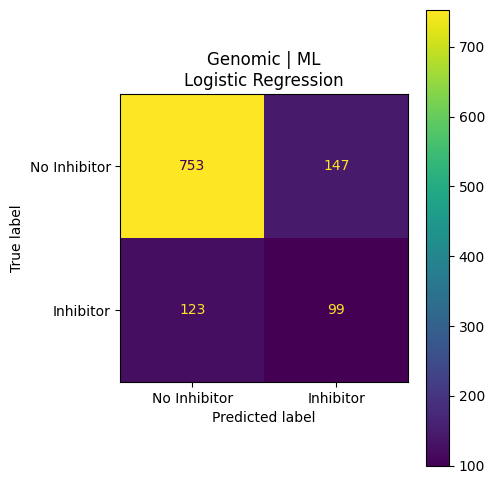


Genomic | ML | Random Forest
Threshold: 0.5000
TN: 709 | FP: 191 | FN: 104 | TP: 118


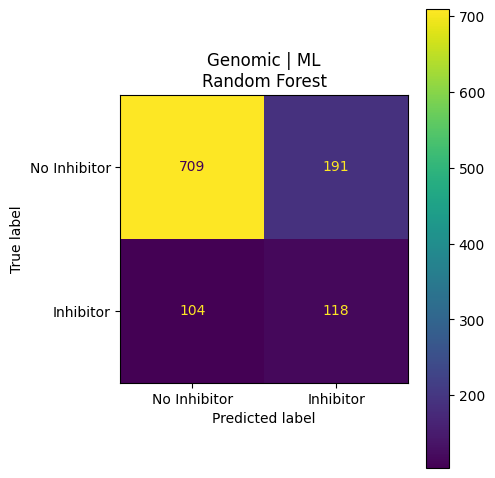


Genomic | ML | Extra Trees
Threshold: 0.5000
TN: 695 | FP: 205 | FN: 91 | TP: 131


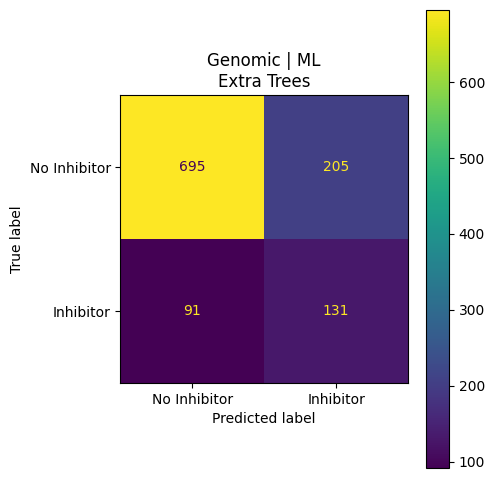


Genomic | ML | Gradient Boosting
Threshold: 0.5000
TN: 896 | FP: 4 | FN: 219 | TP: 3


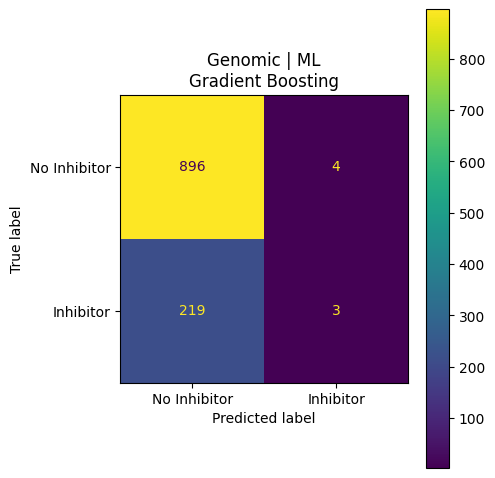


Genomic | ML | HistGradientBoosting
Threshold: 0.5000
TN: 882 | FP: 18 | FN: 178 | TP: 44


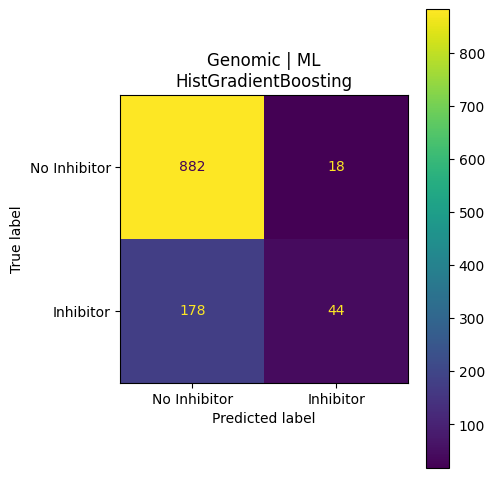


Genomic | ML | XGBoost
Threshold: 0.5000
TN: 717 | FP: 183 | FN: 103 | TP: 119


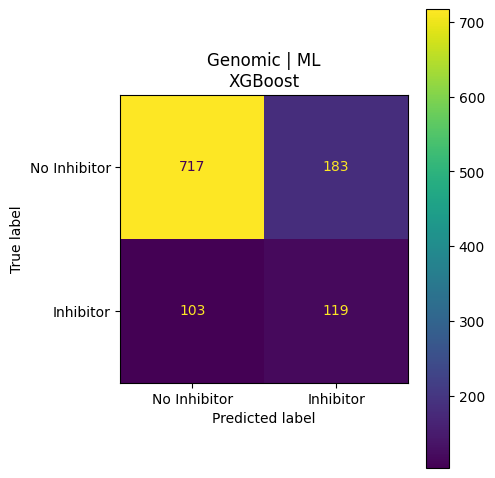


Genomic | ML | CatBoost
Threshold: 0.5000
TN: 727 | FP: 173 | FN: 86 | TP: 136


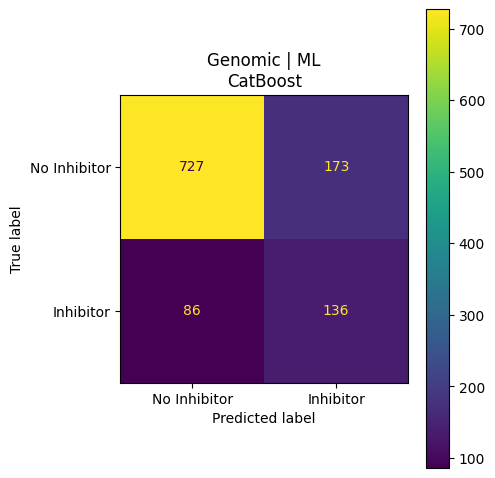


Genomic | ML | CatBoost Unweighted
Threshold: 0.5000
TN: 879 | FP: 21 | FN: 175 | TP: 47


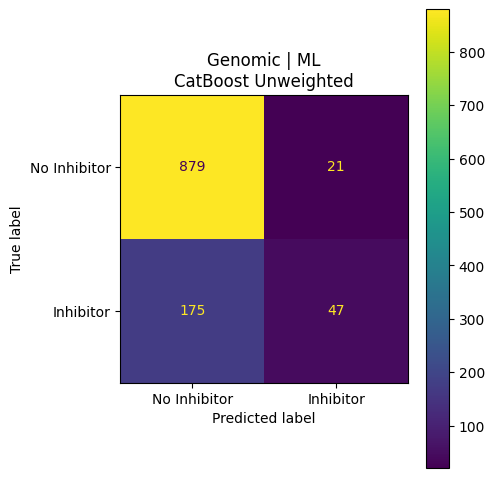


Genomic | ML | SMOTE Random Forest
Threshold: 0.5000
TN: 707 | FP: 193 | FN: 105 | TP: 117


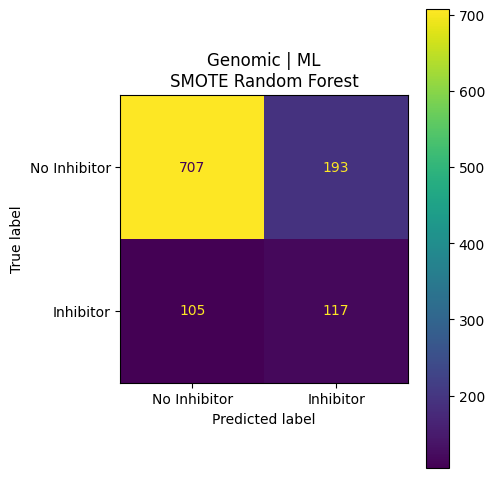


Clinical | ML | Logistic Regression
Threshold: 0.5000
TN: 552 | FP: 348 | FN: 56 | TP: 166


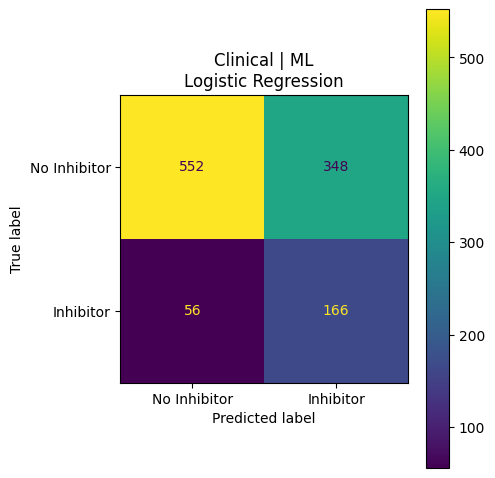


Clinical | ML | Random Forest
Threshold: 0.5000
TN: 518 | FP: 382 | FN: 49 | TP: 173


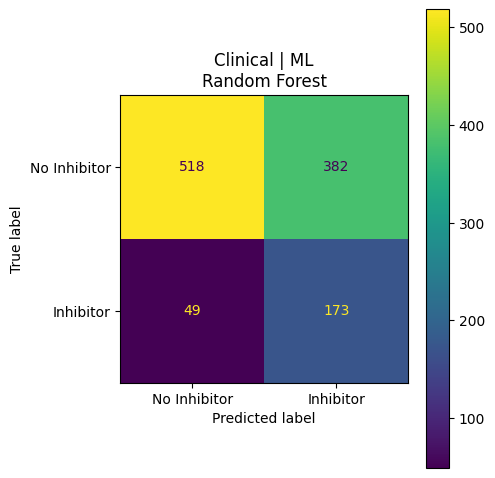


Clinical | ML | Extra Trees
Threshold: 0.5000
TN: 520 | FP: 380 | FN: 49 | TP: 173


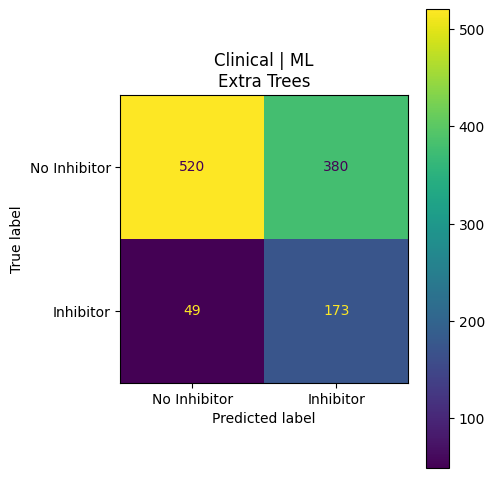


Clinical | ML | Gradient Boosting
Threshold: 0.5000
TN: 887 | FP: 13 | FN: 188 | TP: 34


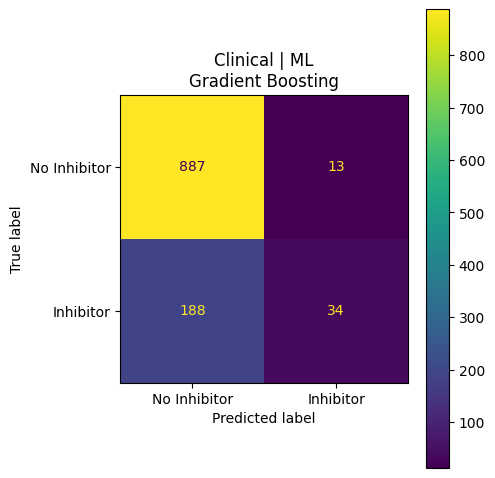


Clinical | ML | HistGradientBoosting
Threshold: 0.5000
TN: 887 | FP: 13 | FN: 188 | TP: 34


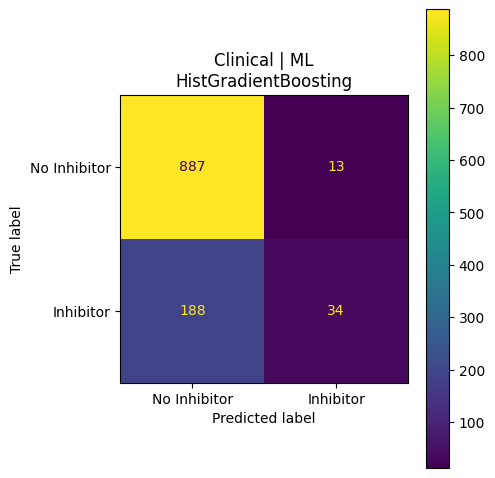


Clinical | ML | XGBoost
Threshold: 0.5000
TN: 545 | FP: 355 | FN: 57 | TP: 165


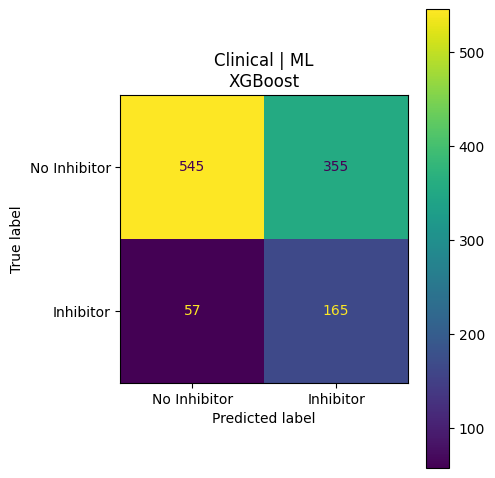


Clinical | ML | CatBoost
Threshold: 0.5000
TN: 627 | FP: 273 | FN: 80 | TP: 142


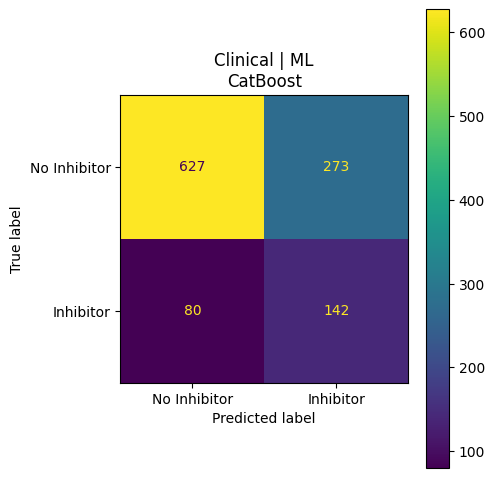


Clinical | ML | CatBoost Unweighted
Threshold: 0.5000
TN: 885 | FP: 15 | FN: 178 | TP: 44


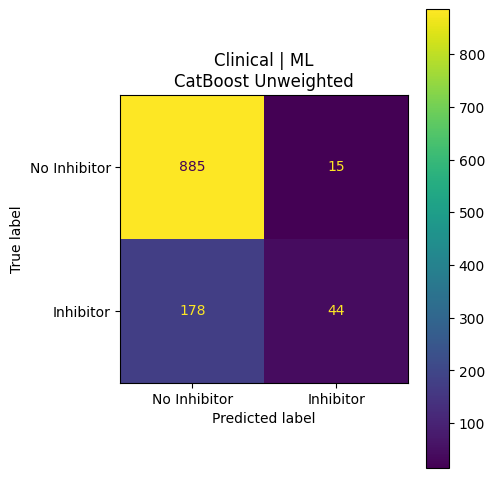


Clinical | ML | SMOTE Random Forest
Threshold: 0.5000
TN: 518 | FP: 382 | FN: 49 | TP: 173


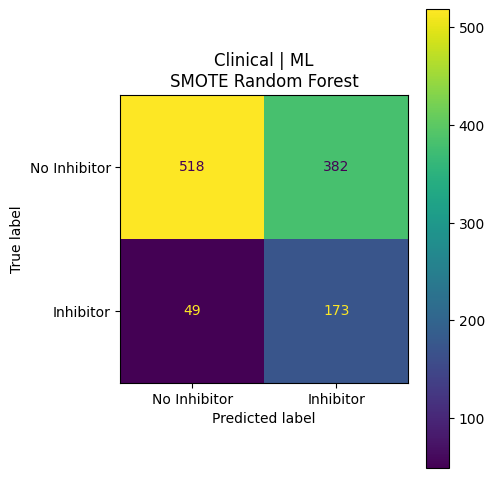


Merged | ML | Logistic Regression
Threshold: 0.5000
TN: 757 | FP: 143 | FN: 97 | TP: 125


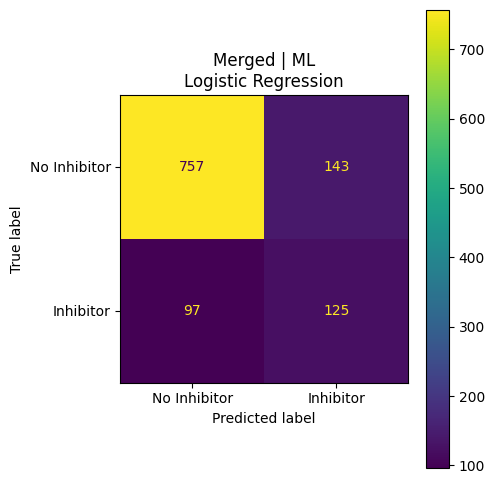


Merged | ML | Random Forest
Threshold: 0.5000
TN: 705 | FP: 195 | FN: 91 | TP: 131


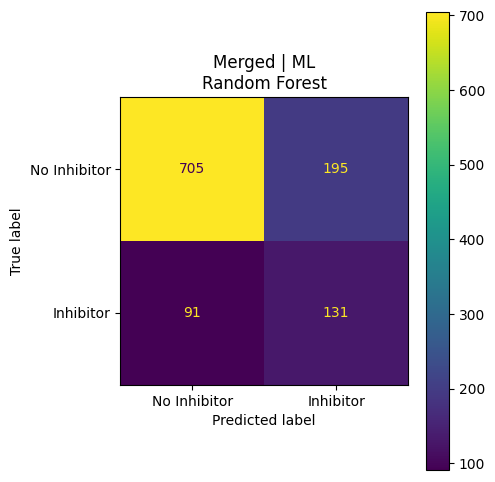


Merged | ML | Extra Trees
Threshold: 0.5000
TN: 688 | FP: 212 | FN: 72 | TP: 150


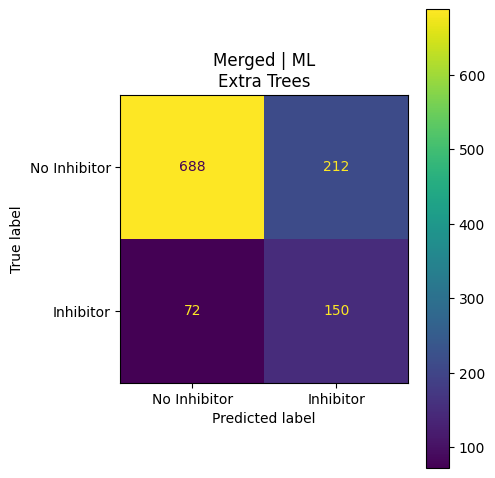


Merged | ML | Gradient Boosting
Threshold: 0.5000
TN: 891 | FP: 9 | FN: 199 | TP: 23


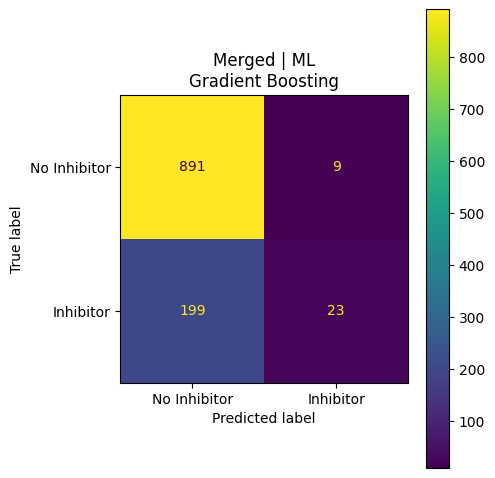


Merged | ML | HistGradientBoosting
Threshold: 0.5000
TN: 879 | FP: 21 | FN: 171 | TP: 51


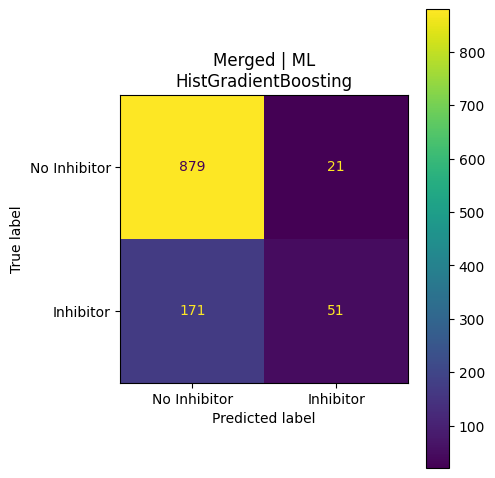


Merged | ML | XGBoost
Threshold: 0.5000
TN: 719 | FP: 181 | FN: 84 | TP: 138


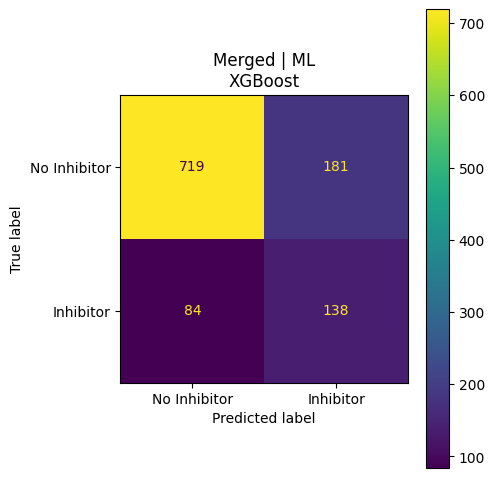


Merged | ML | CatBoost
Threshold: 0.5000
TN: 767 | FP: 133 | FN: 93 | TP: 129


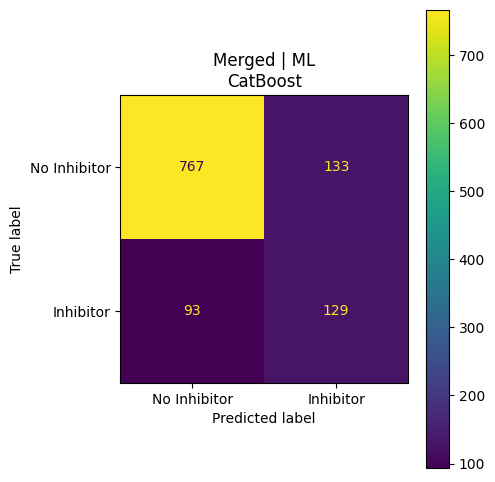


Merged | ML | CatBoost Unweighted
Threshold: 0.5000
TN: 880 | FP: 20 | FN: 164 | TP: 58


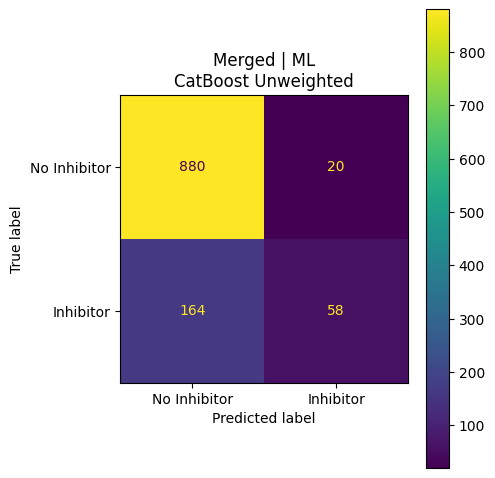


Merged | ML | SMOTE Random Forest
Threshold: 0.5000
TN: 708 | FP: 192 | FN: 90 | TP: 132


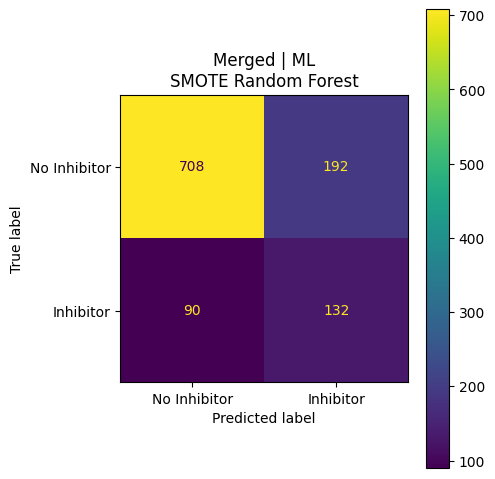


Genomic | DL | Deep MLP
Threshold: 0.5000
TN: 687 | FP: 213 | FN: 80 | TP: 142


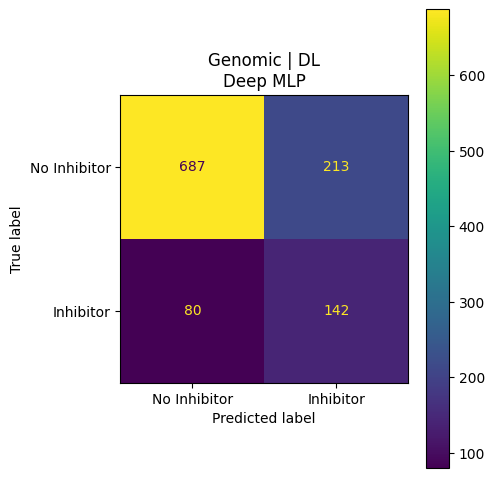


Genomic | DL | Residual MLP
Threshold: 0.5000
TN: 664 | FP: 236 | FN: 87 | TP: 135


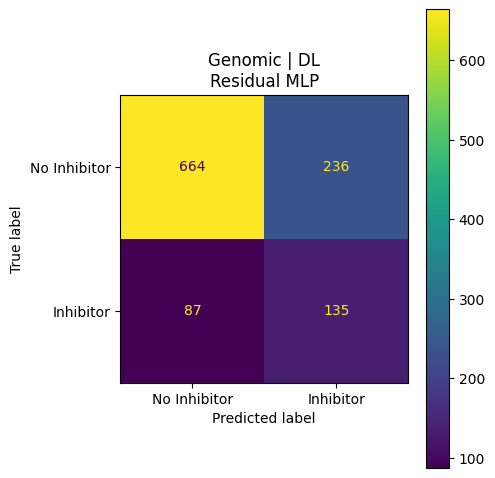


Genomic | DL | CNN1D
Threshold: 0.5000
TN: 628 | FP: 272 | FN: 72 | TP: 150


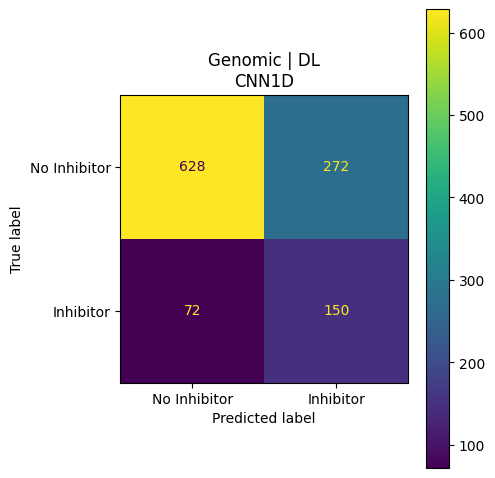


Genomic | DL | TabTransformer
Threshold: 0.5000
TN: 900 | FP: 0 | FN: 222 | TP: 0


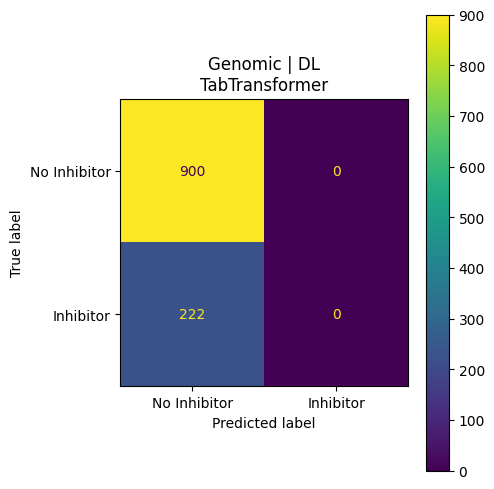


Clinical | DL | Deep MLP
Threshold: 0.5000
TN: 511 | FP: 389 | FN: 51 | TP: 171


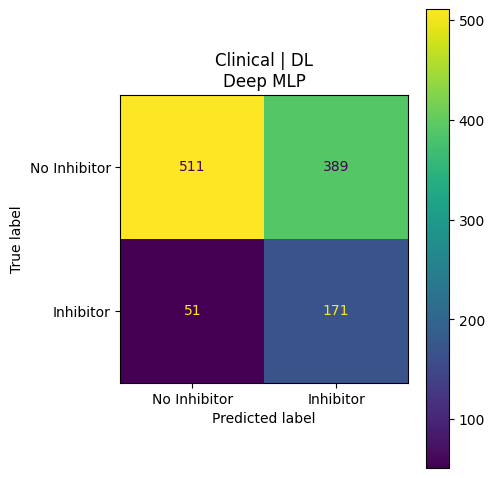


Clinical | DL | Residual MLP
Threshold: 0.5000
TN: 828 | FP: 72 | FN: 165 | TP: 57


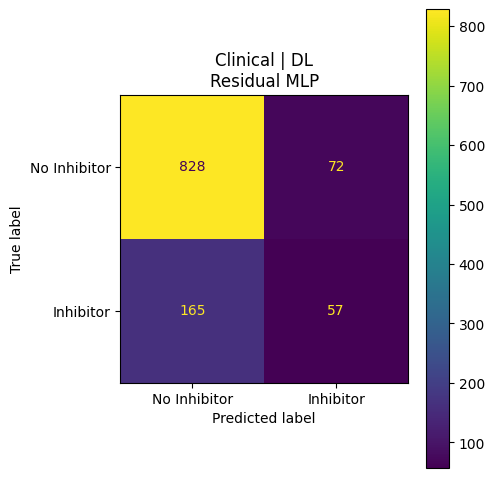


Clinical | DL | CNN1D
Threshold: 0.5000
TN: 488 | FP: 412 | FN: 42 | TP: 180


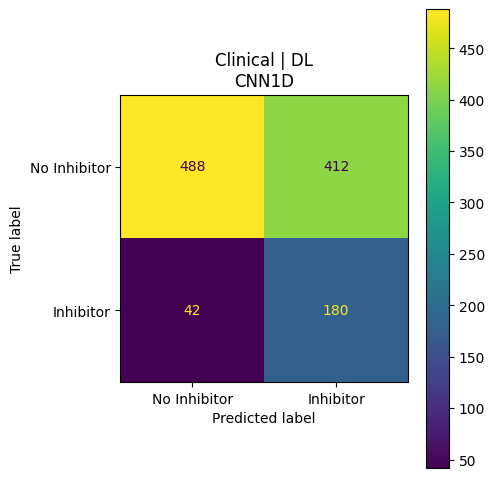


Clinical | DL | TabTransformer
Threshold: 0.5000
TN: 900 | FP: 0 | FN: 222 | TP: 0


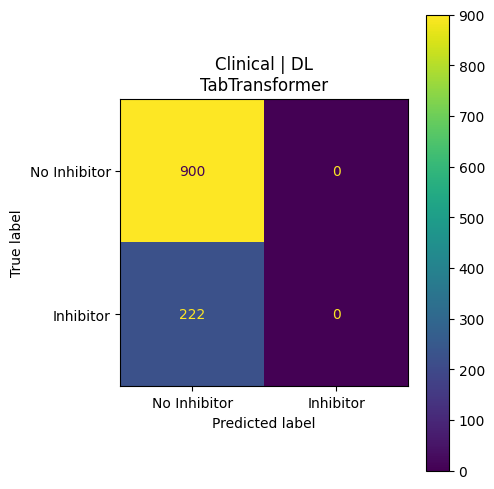


Merged | DL | Deep MLP
Threshold: 0.5000
TN: 658 | FP: 242 | FN: 72 | TP: 150


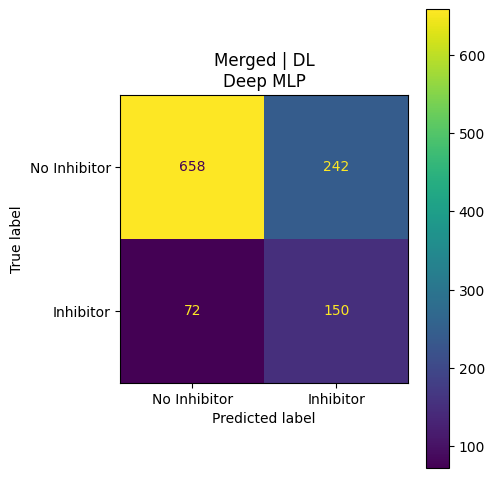


Merged | DL | Residual MLP
Threshold: 0.5000
TN: 670 | FP: 230 | FN: 82 | TP: 140


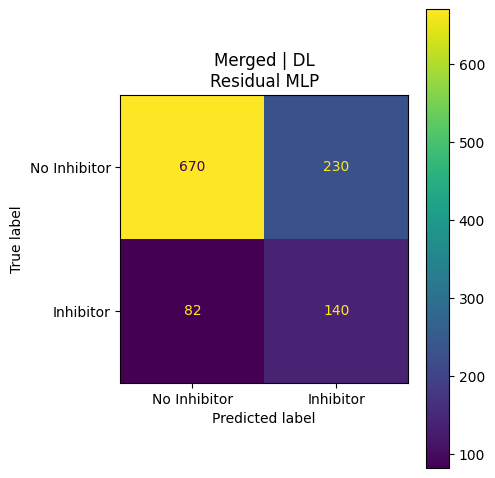


Merged | DL | CNN1D
Threshold: 0.5000
TN: 660 | FP: 240 | FN: 72 | TP: 150


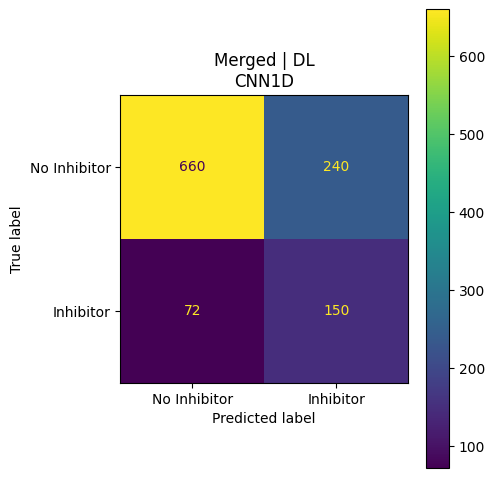


Merged | DL | TabTransformer
Threshold: 0.5000
TN: 900 | FP: 0 | FN: 222 | TP: 0


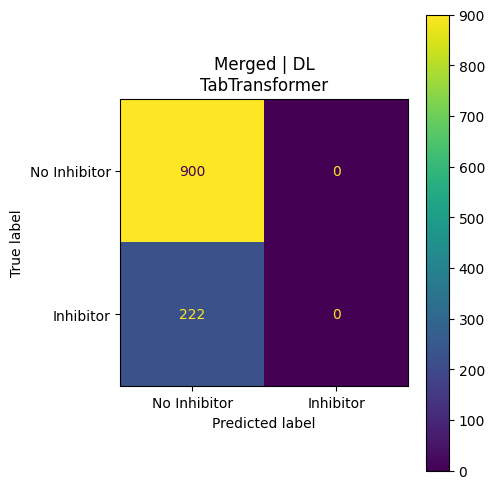


Genomic | Stacked Ensemble | All ML
Threshold: 0.8100
TN: 860 | FP: 40 | FN: 162 | TP: 60


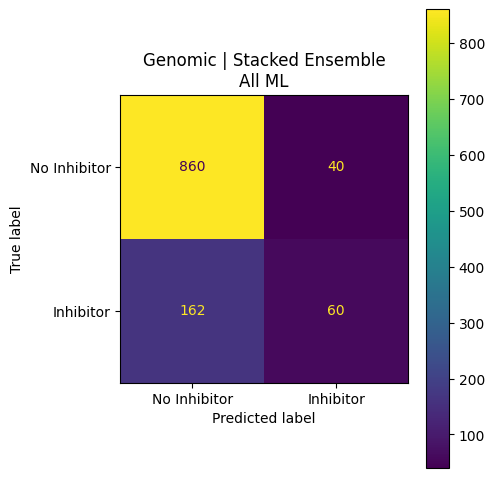


Genomic | Stacked Ensemble | All DL
Threshold: 0.8300
TN: 899 | FP: 1 | FN: 218 | TP: 4


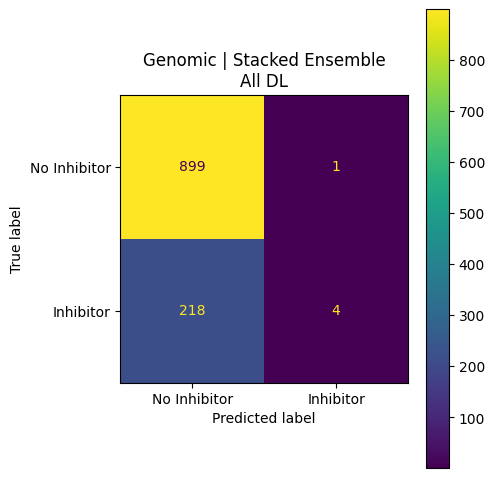


Genomic | Stacked Ensemble | All ML + All DL
Threshold: 0.8350
TN: 882 | FP: 18 | FN: 172 | TP: 50


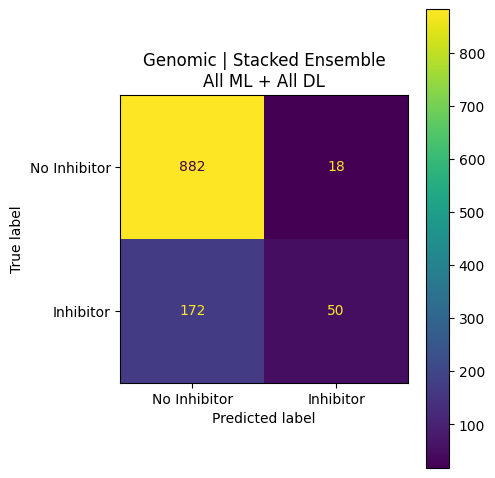


Clinical | Stacked Ensemble | All ML
Threshold: 0.8550
TN: 886 | FP: 14 | FN: 178 | TP: 44


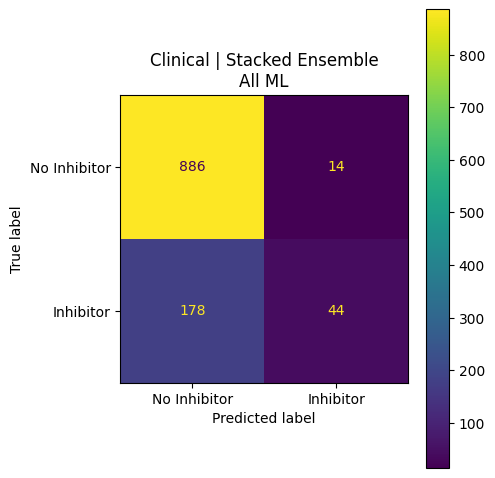


Clinical | Stacked Ensemble | All DL
Threshold: 0.7100
TN: 900 | FP: 0 | FN: 221 | TP: 1


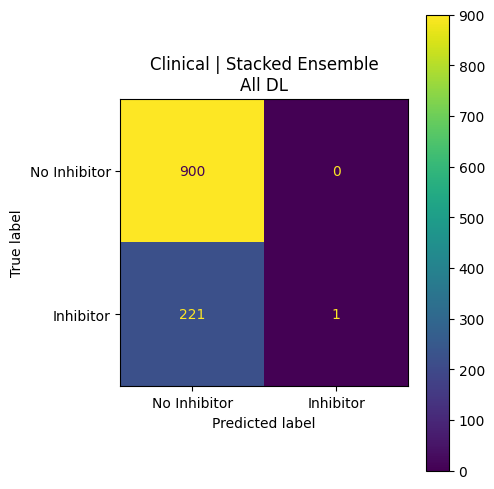


Clinical | Stacked Ensemble | All ML + All DL
Threshold: 0.8400
TN: 885 | FP: 15 | FN: 178 | TP: 44


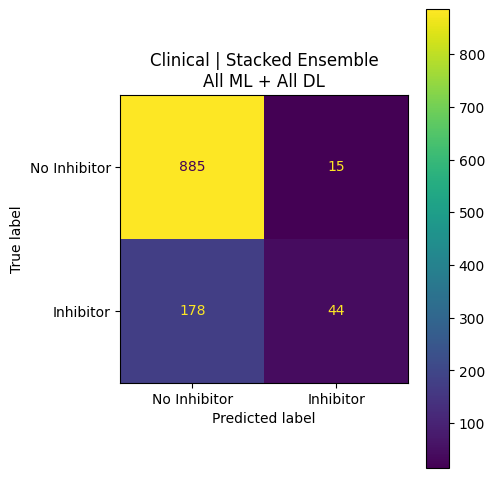


Merged | Stacked Ensemble | All ML
Threshold: 0.8600
TN: 876 | FP: 24 | FN: 149 | TP: 73


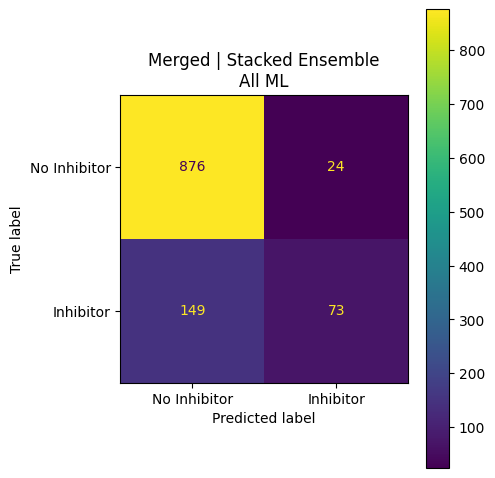


Merged | Stacked Ensemble | All DL
Threshold: 0.8100
TN: 898 | FP: 2 | FN: 211 | TP: 11


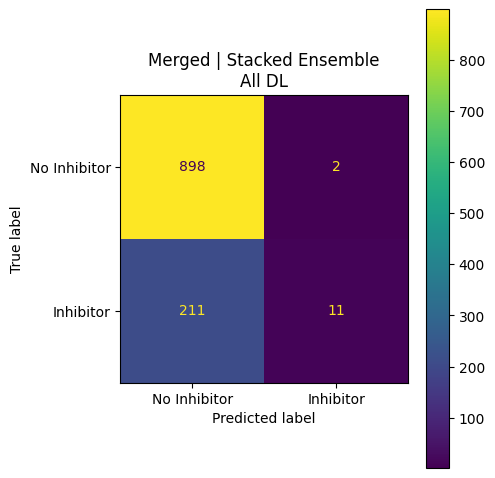


Merged | Stacked Ensemble | All ML + All DL
Threshold: 0.8550
TN: 875 | FP: 25 | FN: 147 | TP: 75


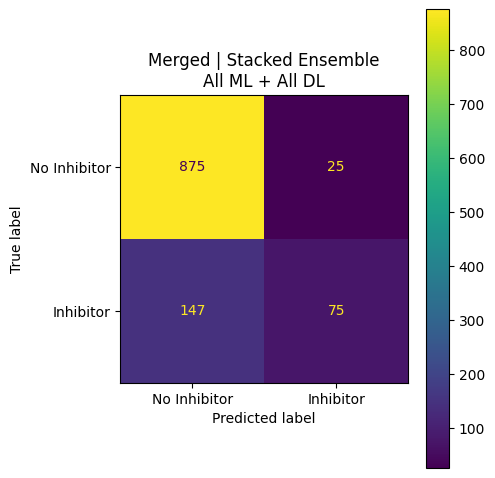


ROC CURVES — ALL MODELS


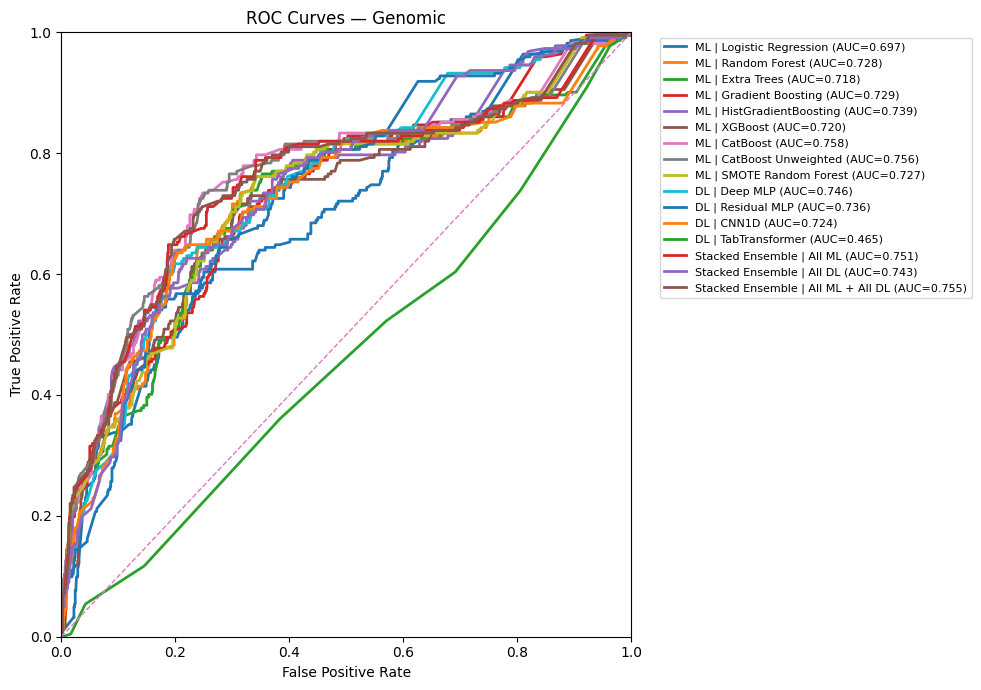

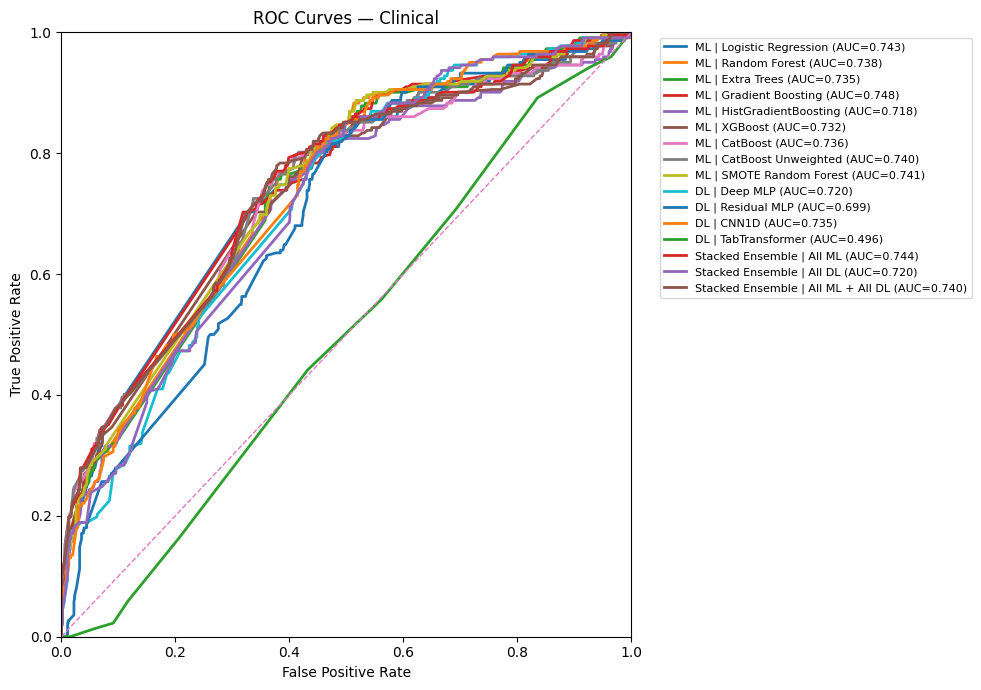

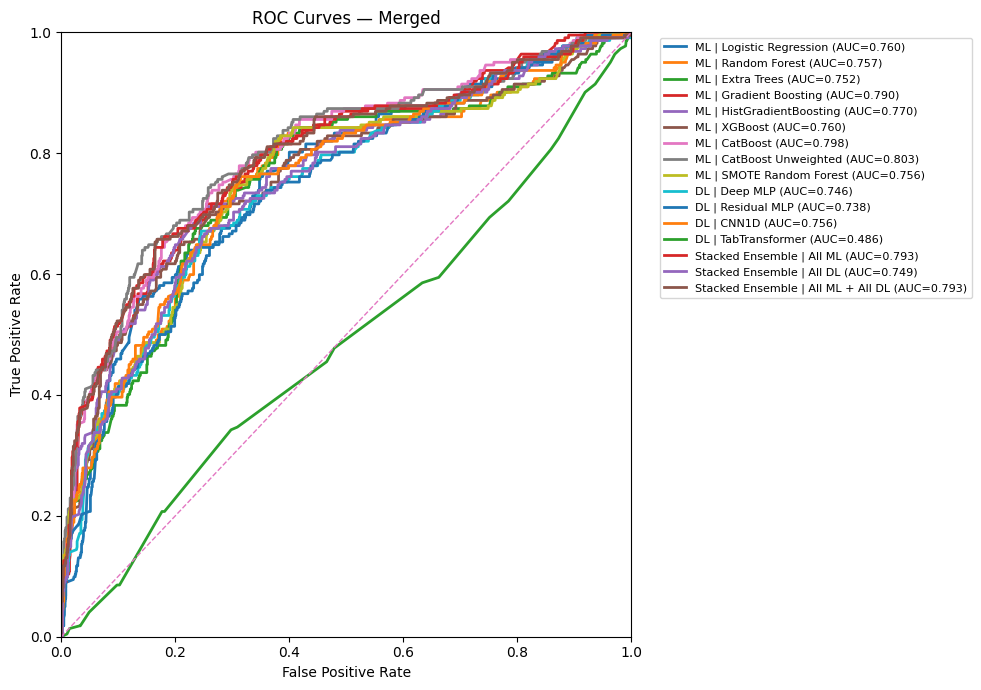


PRECISION-RECALL CURVES — ALL MODELS


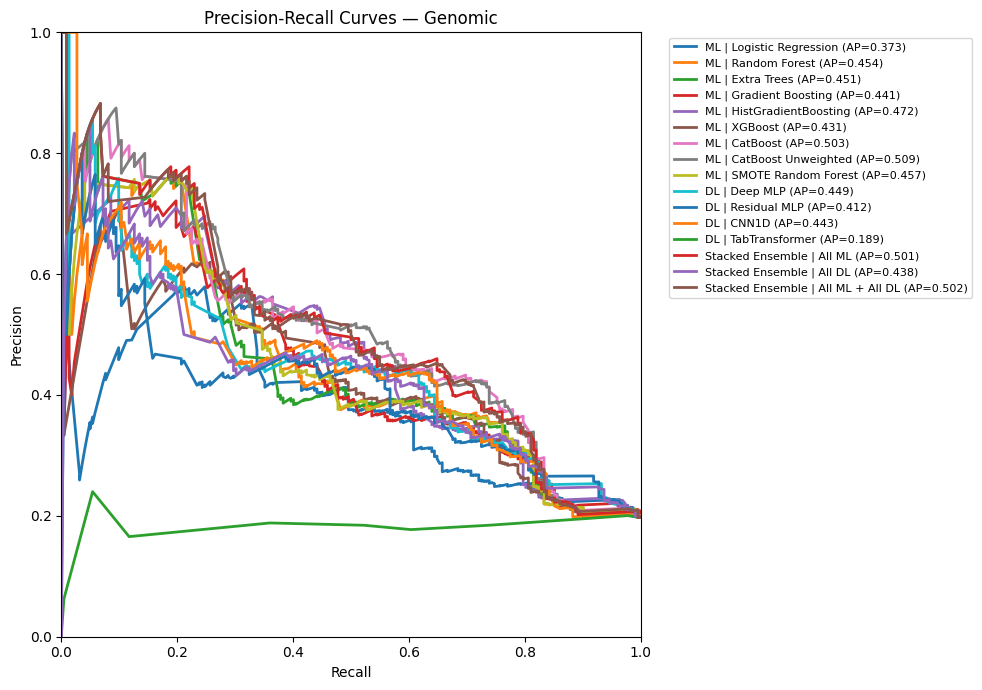

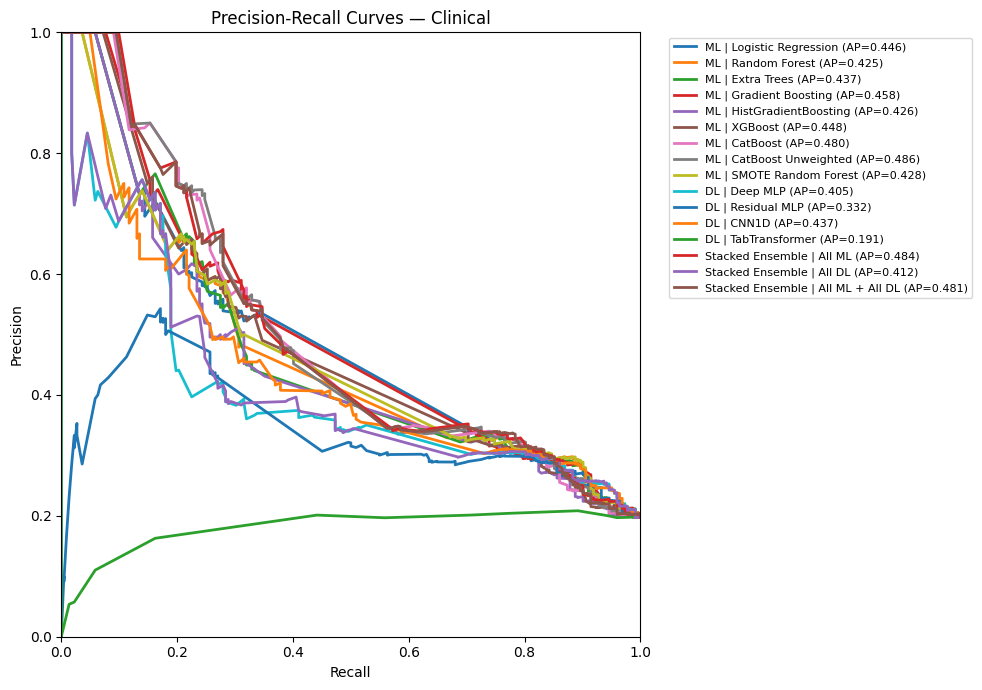

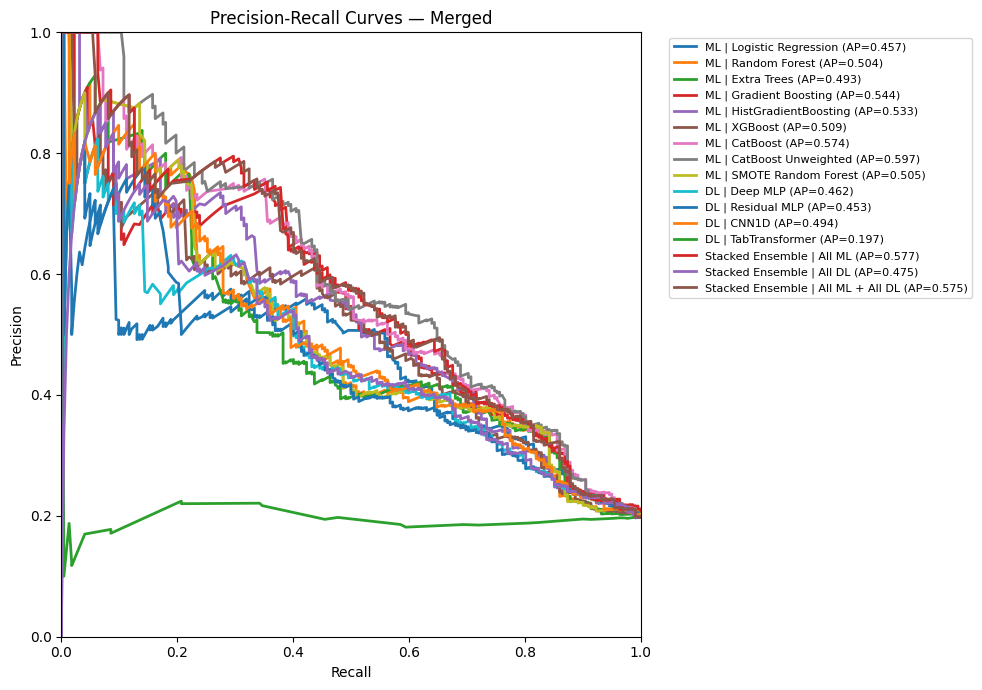


✓ Final metrics table completed.
✓ Confusion matrices completed.
✓ ROC curves completed.
✓ Precision-Recall curves completed.
✓ Saved: FINAL_HELDOUT_MODEL_EVALUATION.csv
✓ Total prediction sets evaluated: 48


In [15]:
# ============================================================
# FINAL MODEL EVALUATION
# CONFUSION MATRICES + ROC CURVES + PR CURVES + METRICS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    brier_score_loss
)

# ============================================================
# CHECK REQUIRED VARIABLES
# ============================================================

required_vars = [
    "blocks"
]

missing = [
    v for v in required_vars
    if v not in globals()
]

if missing:
    raise RuntimeError(
        "Missing required variable(s): "
        + ", ".join(missing)
        + "\nRun the final 9-stack cell first."
    )

# ============================================================
# DATASET LABELS
# ============================================================

DATASETS = [
    "Genomic",
    "Clinical",
    "Merged"
]

# ============================================================
# COLLECT TEST PREDICTIONS
# ============================================================

evaluation_rows = []

# ============================================================
# 1. INDIVIDUAL ML MODELS
# ============================================================

if "ml_test_store" in globals():

    for dataset_name in DATASETS:

        if dataset_name not in ml_test_store:
            continue

        (
            Xtr,
            ytr,
            gtr,
            Xva,
            yva,
            gva,
            Xte,
            yte,
            gte
        ) = blocks[dataset_name]

        y_true = np.asarray(
            yte
        ).astype(int)

        for model_name, prob in ml_test_store[
            dataset_name
        ].items():

            y_prob = np.asarray(
                prob,
                dtype=float
            ).reshape(-1)

            if len(y_true) != len(y_prob):
                raise ValueError(
                    f"Length mismatch: "
                    f"{dataset_name} | "
                    f"{model_name}"
                )

            evaluation_rows.append({

                "Family": "ML",

                "Dataset": dataset_name,

                "Model": model_name,

                "Threshold": 0.50,

                "y_true": y_true,

                "y_prob": y_prob
            })

# ============================================================
# 2. INDIVIDUAL DL MODELS
# ============================================================

if "dl_test_store" in globals():

    for dataset_name in DATASETS:

        if dataset_name not in dl_test_store:
            continue

        (
            Xtr,
            ytr,
            gtr,
            Xva,
            yva,
            gva,
            Xte,
            yte,
            gte
        ) = blocks[dataset_name]

        y_true = np.asarray(
            yte
        ).astype(int)

        for model_name, prob in dl_test_store[
            dataset_name
        ].items():

            y_prob = np.asarray(
                prob,
                dtype=float
            ).reshape(-1)

            if len(y_true) != len(y_prob):
                raise ValueError(
                    f"Length mismatch: "
                    f"{dataset_name} | "
                    f"{model_name}"
                )

            evaluation_rows.append({

                "Family": "DL",

                "Dataset": dataset_name,

                "Model": model_name,

                "Threshold": 0.50,

                "y_true": y_true,

                "y_prob": y_prob
            })

# ============================================================
# 3. NINE STACKS
# ============================================================

if "stack_objects" in globals():

    for stack_key, obj in stack_objects.items():

        # ----------------------------------------------------
        # Expected:
        # Genomic_All_ML
        # Clinical_All_DL
        # Merged_All_ML_DL
        # ----------------------------------------------------

        parts = stack_key.split(
            "_",
            1
        )

        if len(parts) != 2:
            print(
                f"⚠ Skipping unexpected stack key: "
                f"{stack_key}"
            )
            continue

        dataset_name = parts[0]
        stack_code = parts[1]

        if dataset_name not in DATASETS:

            print(
                f"⚠ Skipping stack with unknown dataset: "
                f"{stack_key}"
            )
            continue

        # ----------------------------------------------------
        # Convert stack code to readable name
        # ----------------------------------------------------

        if stack_code == "All_ML":

            stack_name = "All ML"

        elif stack_code == "All_DL":

            stack_name = "All DL"

        elif stack_code == "All_ML_DL":

            stack_name = "All ML + All DL"

        else:

            stack_name = stack_code.replace(
                "_",
                " "
            )

        (
            Xtr,
            ytr,
            gtr,
            Xva,
            yva,
            gva,
            Xte,
            yte,
            gte
        ) = blocks[dataset_name]

        y_true = np.asarray(
            yte
        ).astype(int)

        y_prob = np.asarray(
            obj["test_probability"],
            dtype=float
        ).reshape(-1)

        threshold = float(
            obj.get(
                "threshold",
                0.50
            )
        )

        if len(y_true) != len(y_prob):

            raise ValueError(
                f"Stack length mismatch: "
                f"{stack_key}"
            )

        evaluation_rows.append({

            "Family": "Stacked Ensemble",

            "Dataset": dataset_name,

            "Model": stack_name,

            "Threshold": threshold,

            "y_true": y_true,

            "y_prob": y_prob
        })

# ============================================================
# CHECK
# ============================================================

print(
    "\nAvailable prediction sets:",
    len(evaluation_rows)
)

if len(evaluation_rows) == 0:

    raise RuntimeError(
        "No prediction sets were found.\n"
        "Run the final 9-stack cell first."
    )

# ============================================================
# FINAL METRICS
# ============================================================

evaluation_metrics = []

roc_data = {}

pr_data = {}

for row in evaluation_rows:

    family = row["Family"]
    dataset = row["Dataset"]
    model = row["Model"]

    y_true = np.asarray(
        row["y_true"]
    ).astype(int)

    y_prob = np.asarray(
        row["y_prob"],
        dtype=float
    )

    threshold = float(
        row["Threshold"]
    )

    # --------------------------------------------------------
    # CHECK
    # --------------------------------------------------------

    if not np.isfinite(
        y_prob
    ).all():

        raise ValueError(
            f"{family} | "
            f"{dataset} | "
            f"{model}: "
            f"prediction contains NaN/Inf."
        )

    # --------------------------------------------------------
    # PREDICTION
    # --------------------------------------------------------

    y_pred = (
        y_prob >= threshold
    ).astype(int)

    # --------------------------------------------------------
    # CONFUSION MATRIX
    # --------------------------------------------------------

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    # --------------------------------------------------------
    # METRICS
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    balanced_accuracy = (
        balanced_accuracy_score(
            y_true,
            y_pred
        )
    )

    precision_value = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall_value = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0.0
    )

    sensitivity = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0.0
    )

    f1_value = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    mcc_value = matthews_corrcoef(
        y_true,
        y_pred
    )

    roc_auc_value = roc_auc_score(
        y_true,
        y_prob
    )

    pr_auc_value = average_precision_score(
        y_true,
        y_prob
    )

    brier_value = brier_score_loss(
        y_true,
        y_prob
    )

    # --------------------------------------------------------
    # ROC DATA
    # --------------------------------------------------------

    fpr, tpr, _ = roc_curve(
        y_true,
        y_prob
    )

    roc_auc_curve = auc(
        fpr,
        tpr
    )

    roc_data[
        (
            family,
            dataset,
            model
        )
    ] = {

        "fpr": fpr,

        "tpr": tpr,

        "auc": roc_auc_curve
    }

    # --------------------------------------------------------
    # PR DATA
    # --------------------------------------------------------

    precision_curve, recall_curve, _ = (
        precision_recall_curve(
            y_true,
            y_prob
        )
    )

    pr_auc_curve = (
        average_precision_score(
            y_true,
            y_prob
        )
    )

    pr_data[
        (
            family,
            dataset,
            model
        )
    ] = {

        "precision": precision_curve,

        "recall": recall_curve,

        "auc": pr_auc_curve
    }

    # --------------------------------------------------------
    # SAVE METRICS
    # --------------------------------------------------------

    evaluation_metrics.append({

        "Family":
            family,

        "Dataset":
            dataset,

        "Model":
            model,

        "Threshold":
            threshold,

        "Accuracy":
            accuracy,

        "Balanced Accuracy":
            balanced_accuracy,

        "Precision":
            precision_value,

        "Recall":
            recall_value,

        "Specificity":
            specificity,

        "Sensitivity":
            sensitivity,

        "F1":
            f1_value,

        "MCC":
            mcc_value,

        "ROC-AUC":
            roc_auc_value,

        "PR-AUC":
            pr_auc_value,

        "Brier":
            brier_value,

        "TN":
            tn,

        "FP":
            fp,

        "FN":
            fn,

        "TP":
            tp
    })

# ============================================================
# METRICS TABLE
# ============================================================

evaluation_metrics_df = pd.DataFrame(
    evaluation_metrics
)

evaluation_metrics_df = (
    evaluation_metrics_df
    .sort_values(
        [
            "Balanced Accuracy",
            "ROC-AUC",
            "PR-AUC"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    "\n" + "=" * 130
)

print(
    "FINAL HELD-OUT TEST METRICS"
)

print(
    "=" * 130
)

display(
    evaluation_metrics_df.round(4)
)

# ============================================================
# BEST MODEL
# ============================================================

best_idx = (
    evaluation_metrics_df[
        "Balanced Accuracy"
    ].idxmax()
)

best = (
    evaluation_metrics_df.loc[
        best_idx
    ]
)

print(
    "\n" + "=" * 130
)

print(
    "BEST MODEL / STACK"
)

print(
    "=" * 130
)

print(
    f"Family           : "
    f"{best['Family']}"
)

print(
    f"Dataset          : "
    f"{best['Dataset']}"
)

print(
    f"Model            : "
    f"{best['Model']}"
)

print(
    f"Threshold        : "
    f"{best['Threshold']:.4f}"
)

print(
    f"Accuracy         : "
    f"{best['Accuracy']:.4f}"
)

print(
    f"Balanced Accuracy: "
    f"{best['Balanced Accuracy']:.4f}"
)

print(
    f"Precision        : "
    f"{best['Precision']:.4f}"
)

print(
    f"Recall           : "
    f"{best['Recall']:.4f}"
)

print(
    f"Specificity      : "
    f"{best['Specificity']:.4f}"
)

print(
    f"Sensitivity      : "
    f"{best['Sensitivity']:.4f}"
)

print(
    f"F1               : "
    f"{best['F1']:.4f}"
)

print(
    f"MCC              : "
    f"{best['MCC']:.4f}"
)

print(
    f"ROC-AUC          : "
    f"{best['ROC-AUC']:.4f}"
)

print(
    f"PR-AUC           : "
    f"{best['PR-AUC']:.4f}"
)

print(
    f"Brier            : "
    f"{best['Brier']:.4f}"
)

print(
    f"TN               : "
    f"{int(best['TN'])}"
)

print(
    f"FP               : "
    f"{int(best['FP'])}"
)

print(
    f"FN               : "
    f"{int(best['FN'])}"
)

print(
    f"TP               : "
    f"{int(best['TP'])}"
)

# ============================================================
# CONFUSION MATRICES — ALL MODELS
# ============================================================

print(
    "\n" + "=" * 130
)

print(
    "CONFUSION MATRICES — ALL MODELS"
)

print(
    "=" * 130
)

for row in evaluation_rows:

    family = row["Family"]
    dataset = row["Dataset"]
    model = row["Model"]

    y_true = row["y_true"]
    y_prob = row["y_prob"]
    threshold = row["Threshold"]

    y_pred = (
        y_prob >= threshold
    ).astype(int)

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    )

    print(
        f"\n{dataset} | "
        f"{family} | "
        f"{model}"
    )

    print(
        f"Threshold: {threshold:.4f}"
    )

    print(
        f"TN: {cm[0,0]} | "
        f"FP: {cm[0,1]} | "
        f"FN: {cm[1,0]} | "
        f"TP: {cm[1,1]}"
    )

    fig, ax = plt.subplots(
        figsize=(5, 5)
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[
            "No Inhibitor",
            "Inhibitor"
        ]
    ).plot(
        ax=ax,
        values_format="d"
    )

    ax.set_title(
        f"{dataset} | {family}\n"
        f"{model}"
    )

    plt.tight_layout()
    plt.show()

# ============================================================
# ROC CURVES
# ============================================================

print(
    "\n" + "=" * 130
)

print(
    "ROC CURVES — ALL MODELS"
)

print(
    "=" * 130
)

for dataset_name in DATASETS:

    plt.figure(
        figsize=(10, 7)
    )

    plotted = False

    for key, data in roc_data.items():

        family, dataset, model = key

        if dataset != dataset_name:
            continue

        plt.plot(
            data["fpr"],
            data["tpr"],
            linewidth=2,
            label=(
                f"{family} | "
                f"{model} "
                f"(AUC={data['auc']:.3f})"
            )
        )

        plotted = True

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        linewidth=1
    )

    plt.xlabel(
        "False Positive Rate"
    )

    plt.ylabel(
        "True Positive Rate"
    )

    plt.title(
        f"ROC Curves — {dataset_name}"
    )

    plt.xlim(
        0,
        1
    )

    plt.ylim(
        0,
        1
    )

    if plotted:

        plt.legend(
            bbox_to_anchor=(1.04, 1),
            loc="upper left",
            fontsize=8
        )

    plt.tight_layout()
    plt.show()

# ============================================================
# PRECISION-RECALL CURVES
# ============================================================

print(
    "\n" + "=" * 130
)

print(
    "PRECISION-RECALL CURVES — ALL MODELS"
)

print(
    "=" * 130
)

for dataset_name in DATASETS:

    plt.figure(
        figsize=(10, 7)
    )

    plotted = False

    for key, data in pr_data.items():

        family, dataset, model = key

        if dataset != dataset_name:
            continue

        plt.plot(
            data["recall"],
            data["precision"],
            linewidth=2,
            label=(
                f"{family} | "
                f"{model} "
                f"(AP={data['auc']:.3f})"
            )
        )

        plotted = True

    plt.xlabel(
        "Recall"
    )

    plt.ylabel(
        "Precision"
    )

    plt.title(
        f"Precision-Recall Curves — "
        f"{dataset_name}"
    )

    plt.xlim(
        0,
        1
    )

    plt.ylim(
        0,
        1
    )

    if plotted:

        plt.legend(
            bbox_to_anchor=(1.04, 1),
            loc="upper left",
            fontsize=8
        )

    plt.tight_layout()
    plt.show()

# ============================================================
# SAVE FINAL EVALUATION
# ============================================================

evaluation_metrics_df.to_csv(
    "FINAL_HELDOUT_MODEL_EVALUATION.csv",
    index=False
)

print(
    "\n✓ Final metrics table completed."
)

print(
    "✓ Confusion matrices completed."
)

print(
    "✓ ROC curves completed."
)

print(
    "✓ Precision-Recall curves completed."
)

print(
    "✓ Saved: FINAL_HELDOUT_MODEL_EVALUATION.csv"
)

print(
    f"✓ Total prediction sets evaluated: "
    f"{len(evaluation_rows)}"
)

In [16]:
# ============================================================
# 15. SINGLE FINAL SUMMARY TABLE
# ============================================================
summary_rows = []

for label, df in [
    ("ML", best2_ml),
    ("DL", best2_dl),
    ("Genomic", best2_genomic),
    ("Clinical", best2_clinical),
    ("Merged", best2_merged)
]:
    for rank, (_, row) in enumerate(df.iterrows(), 1):
        summary_rows.append({
            "Selection": label,
            "Rank": rank,
            "Family": row["Family"],
            "Dataset": row["Dataset"],
            "Model": row["Model"],
            "Accuracy": row["Accuracy"],
            "Balanced Accuracy": row["Balanced Accuracy"],
            "Precision": row["Precision"],
            "Recall": row["Recall"],
            "Specificity": row["Specificity"],
            "F1": row["F1"],
            "ROC-AUC": row["ROC-AUC"],
            "PR-AUC": row["PR-AUC"],
            "MCC": row["MCC"],
            "Threshold": row["Threshold"]
        })

final_summary = pd.DataFrame(summary_rows)

display(final_summary.round(4))


,Selection,Rank,Family,Dataset,Model,Accuracy,Balanced Accuracy,Precision,Recall,Specificity,F1,ROC-AUC,PR-AUC,MCC,Threshold
0,Genomic,1,Stacked Ensemble,Genomic,All ML + All DL,0.8307,0.6026,0.7353,0.2252,0.9800,0.3448,0.7547,0.5017,0.3427,0.835
1,Genomic,2,Stacked Ensemble,Genomic,All ML,0.8200,0.6129,0.6000,0.2703,0.9556,0.3727,0.7511,0.5008,0.3158,0.810
2,Clinical,1,Stacked Ensemble,Clinical,All ML,0.8289,0.5913,0.7586,0.1982,0.9844,0.3143,0.7440,0.4837,0.3286,0.855
3,Clinical,2,Stacked Ensemble,Clinical,All ML + All DL,0.8280,0.5908,0.7458,0.1982,0.9833,0.3132,0.7401,0.4806,0.3240,0.840
4,Merged,1,Stacked Ensemble,Merged,All ML + All DL,0.8467,0.6550,0.7500,0.3378,0.9722,0.4658,0.7927,0.5749,0.4335,0.855
5,Merged,2,Stacked Ensemble,Merged,All ML,0.8458,0.6511,0.7526,0.3288,0.9733,0.4577,0.7926,0.5773,0.4283,0.860


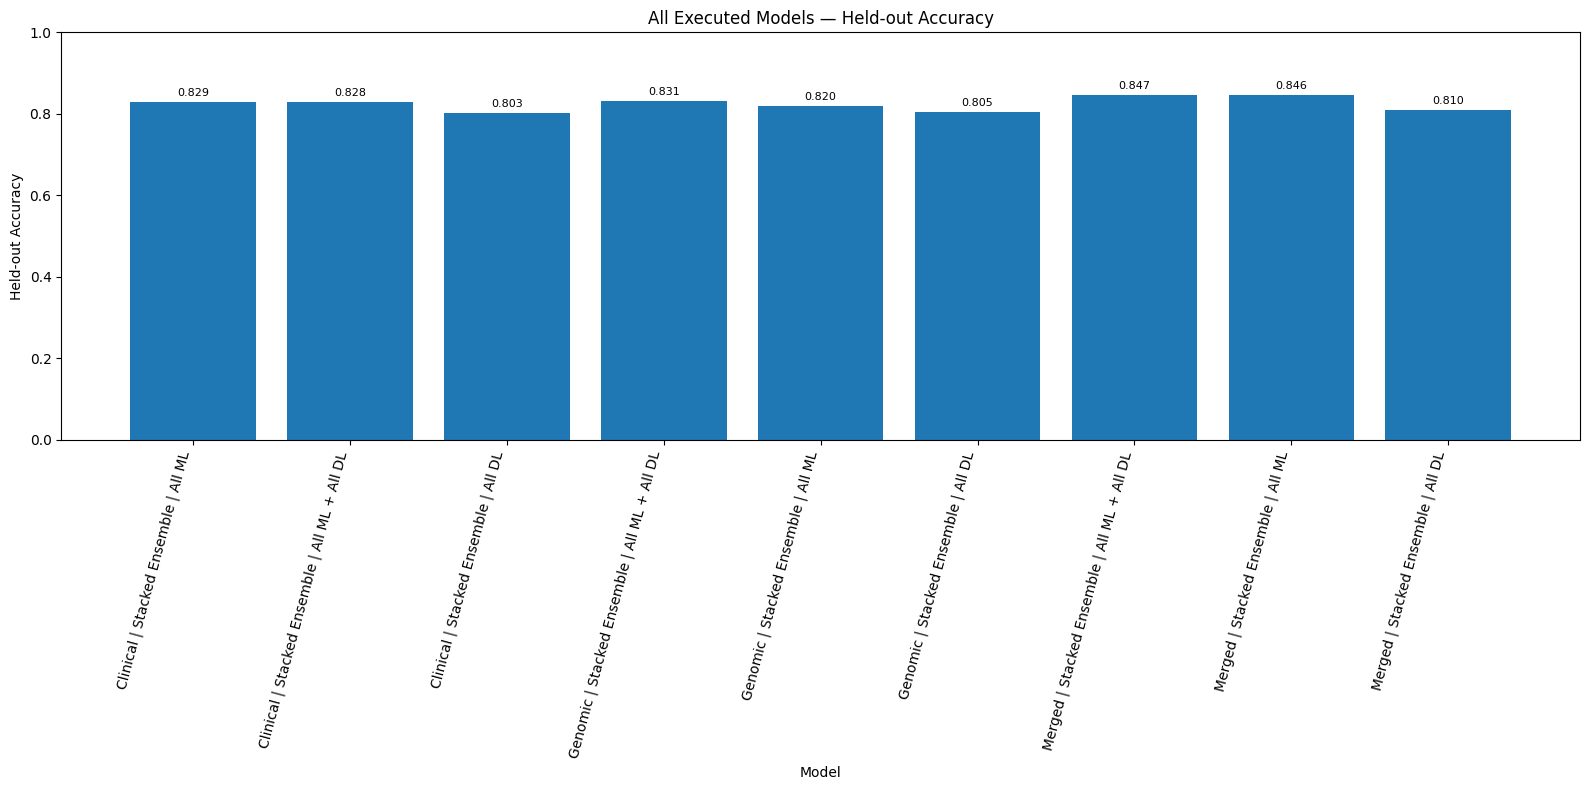

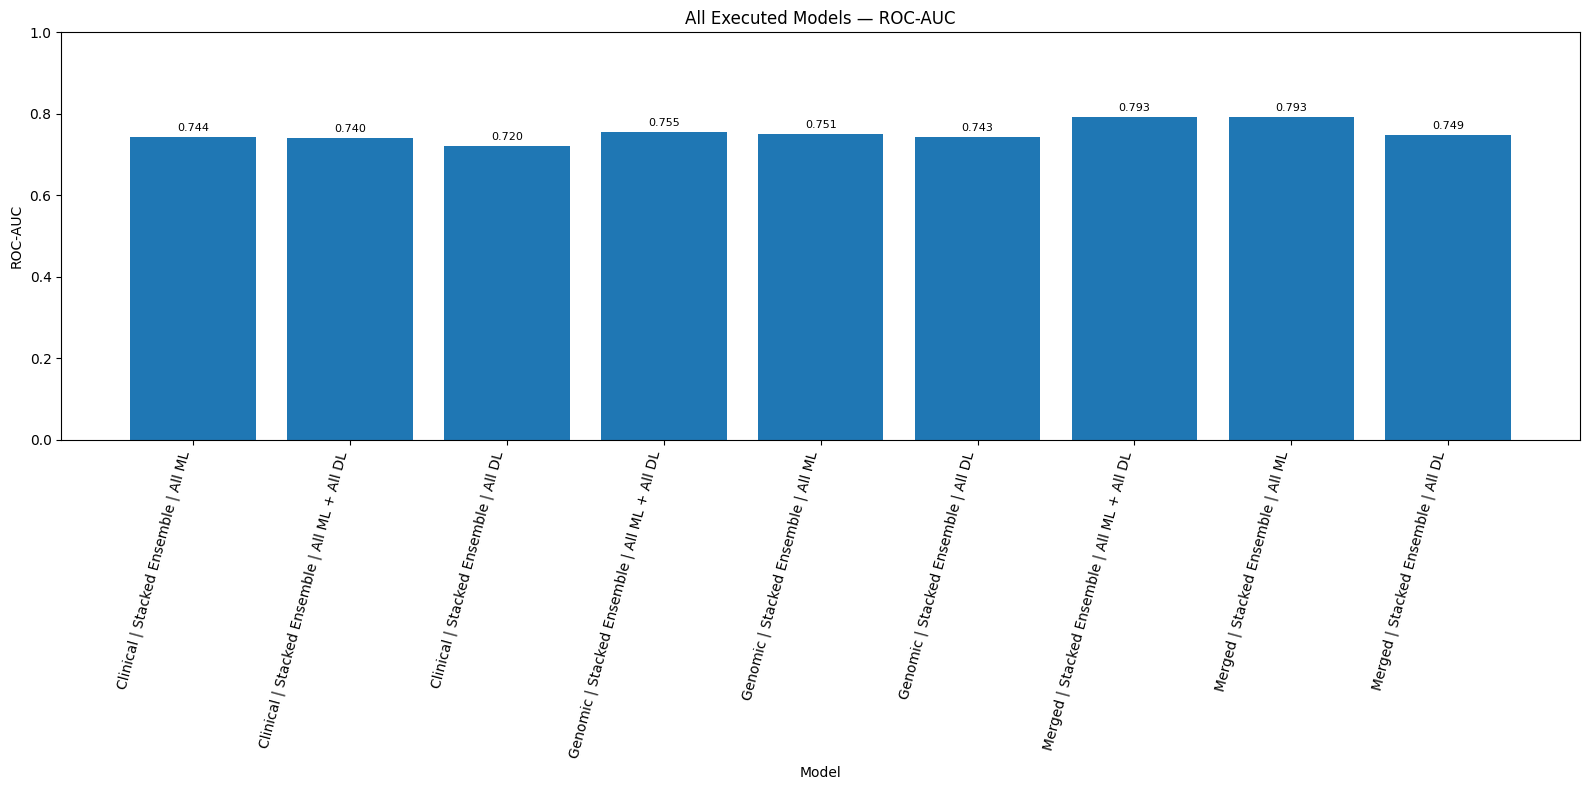

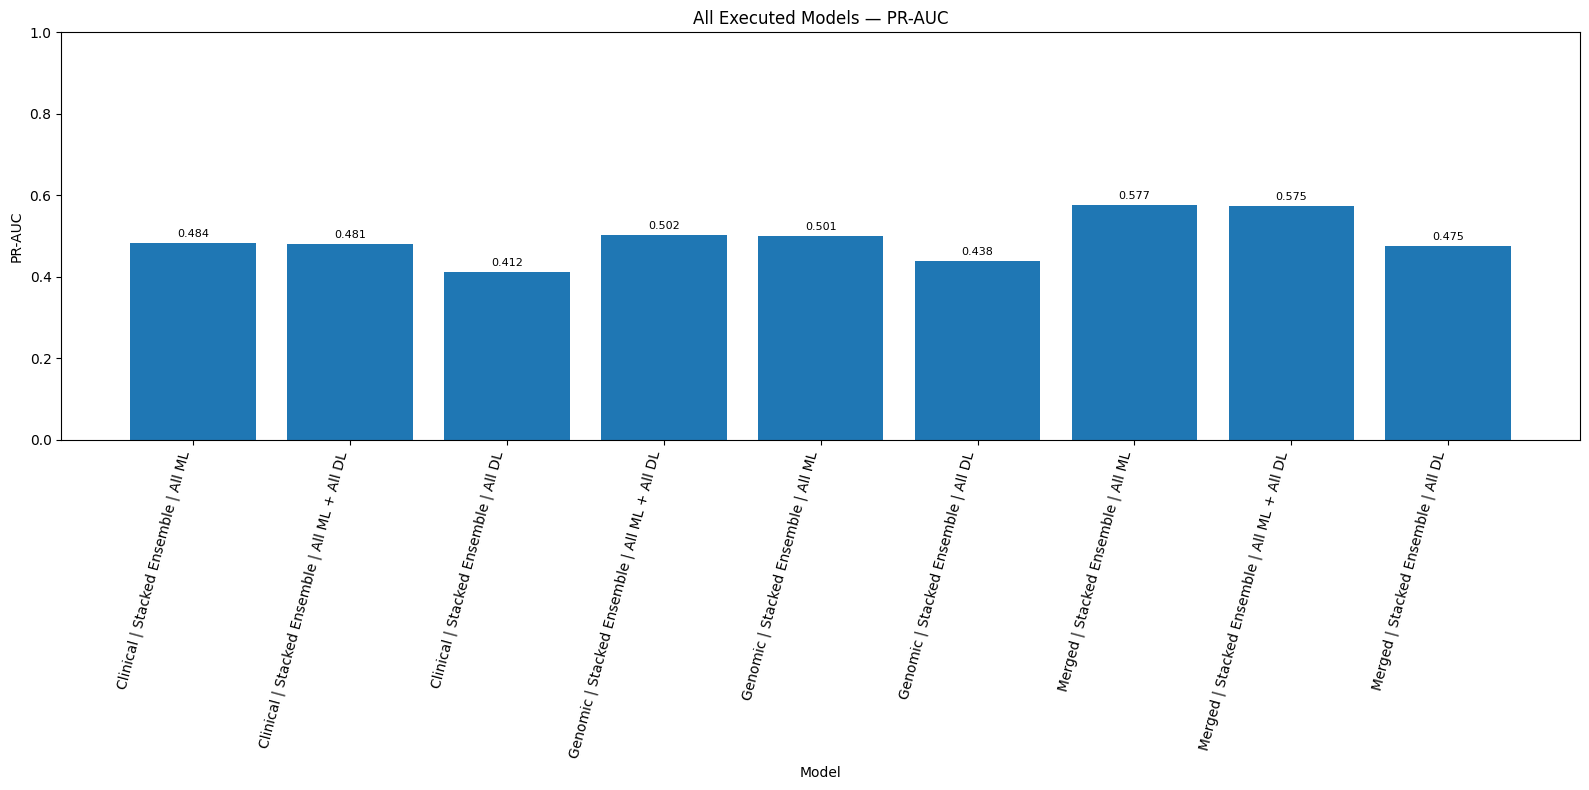

In [17]:
# ============================================================
# 16. VISUAL COMPARISON — ML + DL + STACKING
# ============================================================

plot_df = (
    all_results
    .sort_values(
        ["Dataset", "Accuracy"],
        ascending=[True, False]
    )
    .copy()
)

# Create readable labels
labels = (
    plot_df["Dataset"].astype(str)
    + " | "
    + plot_df["Family"].astype(str)
    + " | "
    + plot_df["Model"].astype(str)
)

plt.figure(figsize=(16, 8))

plt.bar(
    range(len(plot_df)),
    plot_df["Accuracy"]
)

plt.xticks(
    range(len(plot_df)),
    labels,
    rotation=75,
    ha="right"
)

plt.ylabel("Held-out Accuracy")
plt.xlabel("Model")
plt.title(
    "All Executed Models — Held-out Accuracy"
)

plt.ylim(0, 1)

# Print accuracy above each bar
for i, value in enumerate(
    plot_df["Accuracy"]
):
    plt.text(
        i,
        value + 0.01,
        f"{value:.3f}",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.tight_layout()
plt.show()


# ============================================================
# ROC-AUC COMPARISON
# ============================================================

plot_df_auc = (
    all_results
    .sort_values(
        ["Dataset", "ROC-AUC"],
        ascending=[True, False]
    )
    .copy()
)

labels_auc = (
    plot_df_auc["Dataset"].astype(str)
    + " | "
    + plot_df_auc["Family"].astype(str)
    + " | "
    + plot_df_auc["Model"].astype(str)
)

plt.figure(figsize=(16, 8))

plt.bar(
    range(len(plot_df_auc)),
    plot_df_auc["ROC-AUC"]
)

plt.xticks(
    range(len(plot_df_auc)),
    labels_auc,
    rotation=75,
    ha="right"
)

plt.ylabel("ROC-AUC")
plt.xlabel("Model")
plt.title(
    "All Executed Models — ROC-AUC"
)

plt.ylim(0, 1)

for i, value in enumerate(
    plot_df_auc["ROC-AUC"]
):
    plt.text(
        i,
        value + 0.01,
        f"{value:.3f}",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.tight_layout()
plt.show()


# ============================================================
# PR-AUC COMPARISON
# ============================================================

plot_df_pr = (
    all_results
    .sort_values(
        ["Dataset", "PR-AUC"],
        ascending=[True, False]
    )
    .copy()
)

labels_pr = (
    plot_df_pr["Dataset"].astype(str)
    + " | "
    + plot_df_pr["Family"].astype(str)
    + " | "
    + plot_df_pr["Model"].astype(str)
)

plt.figure(figsize=(16, 8))

plt.bar(
    range(len(plot_df_pr)),
    plot_df_pr["PR-AUC"]
)

plt.xticks(
    range(len(plot_df_pr)),
    labels_pr,
    rotation=75,
    ha="right"
)

plt.ylabel("PR-AUC")
plt.xlabel("Model")
plt.title(
    "All Executed Models — PR-AUC"
)

plt.ylim(0, 1)

for i, value in enumerate(
    plot_df_pr["PR-AUC"]
):
    plt.text(
        i,
        value + 0.01,
        f"{value:.3f}",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.tight_layout()
plt.show()

SHAP ANALYSIS

Selecting best merged ML model...
Best merged ML: CatBoost Unweighted


,Model,Accuracy,ROC-AUC,PR-AUC
0,CatBoost Unweighted,0.8360,0.8028,0.5973
1,HistGradientBoosting,0.8289,0.7696,0.5331
2,Gradient Boosting,0.8146,0.7898,0.5439
3,CatBoost,0.7986,0.7984,0.5742
4,Logistic Regression,0.7861,0.7602,0.4568
5,XGBoost,0.7638,0.7602,0.5088
6,SMOTE Random Forest,0.7487,0.7558,0.5050
7,Extra Trees,0.7469,0.7522,0.4934
8,Random Forest,0.7451,0.7565,0.5040



Selecting best merged DL model...
Best merged DL: TabTransformer


,Model,Accuracy,ROC-AUC,PR-AUC
0,TabTransformer,0.8021,0.4857,0.1970
1,CNN1D,0.7219,0.7559,0.4944
2,Residual MLP,0.7219,0.7383,0.4533
3,Deep MLP,0.7201,0.7458,0.4621



Selecting best merged stack...
Best merged stack: All ML + All DL


,Dataset,Stack,Base Models,Models,Accuracy,Balanced Accuracy,Precision,Recall,Specificity,Sensitivity,F1,MCC,ROC-AUC,PR-AUC,Brier,Threshold
0,Merged,All ML + All DL,13,Logistic Regression + Random Forest + Extra Tr...,0.8467,0.6550,0.7500,0.3378,0.9722,0.3378,0.4658,0.4335,0.7927,0.5749,0.1703,0.855
1,Merged,All ML,9,Logistic Regression + Random Forest + Extra Tr...,0.8458,0.6511,0.7526,0.3288,0.9733,0.3288,0.4577,0.4283,0.7926,0.5773,0.1704,0.860
2,Merged,All DL,4,Deep MLP + Residual MLP + CNN1D + TabTransformer,0.8102,0.5237,0.8462,0.0495,0.9978,0.0495,0.0936,0.1762,0.7487,0.4754,0.2104,0.810



SHAP — BEST MERGED ML
Model: CatBoost Unweighted

Calculating SHAP for: CatBoost Unweighted


PermutationExplainer explainer: 51it [00:19,  1.79it/s]


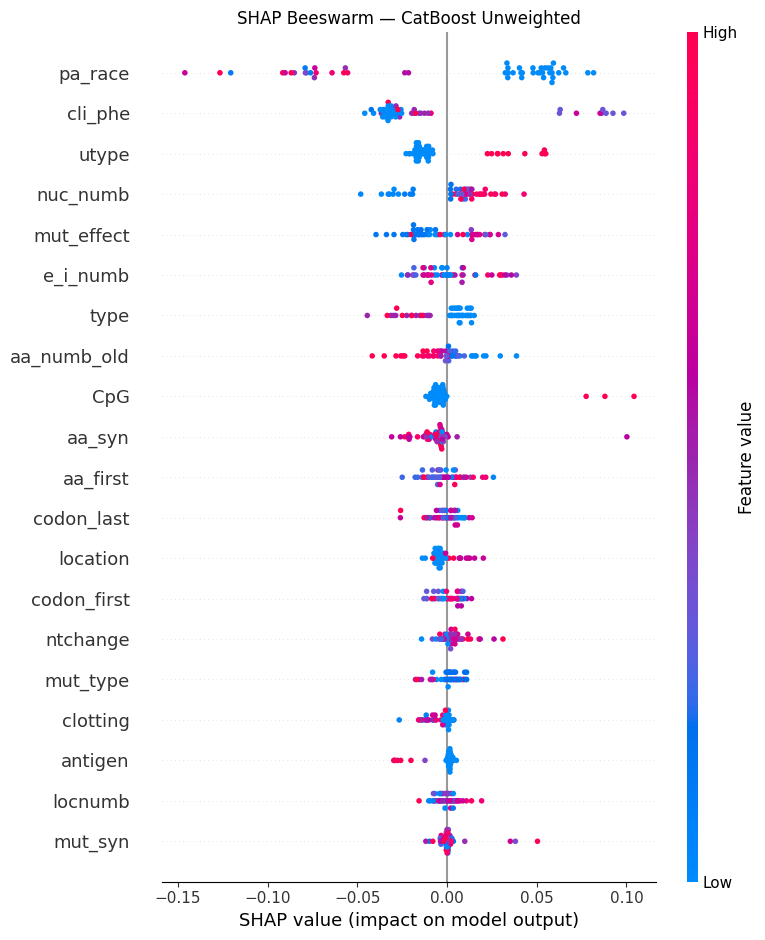


SHAP Beeswarm — CatBoost Unweighted


,Feature,Mean |SHAP|
0,pa_race,0.062042
1,cli_phe,0.038272
2,utype,0.019850
3,nuc_numb,0.016960
4,mut_effect,0.015927
5,e_i_numb,0.013041
6,type,0.012624
7,aa_numb_old,0.010892
8,CpG,0.010237
9,aa_syn,0.009940


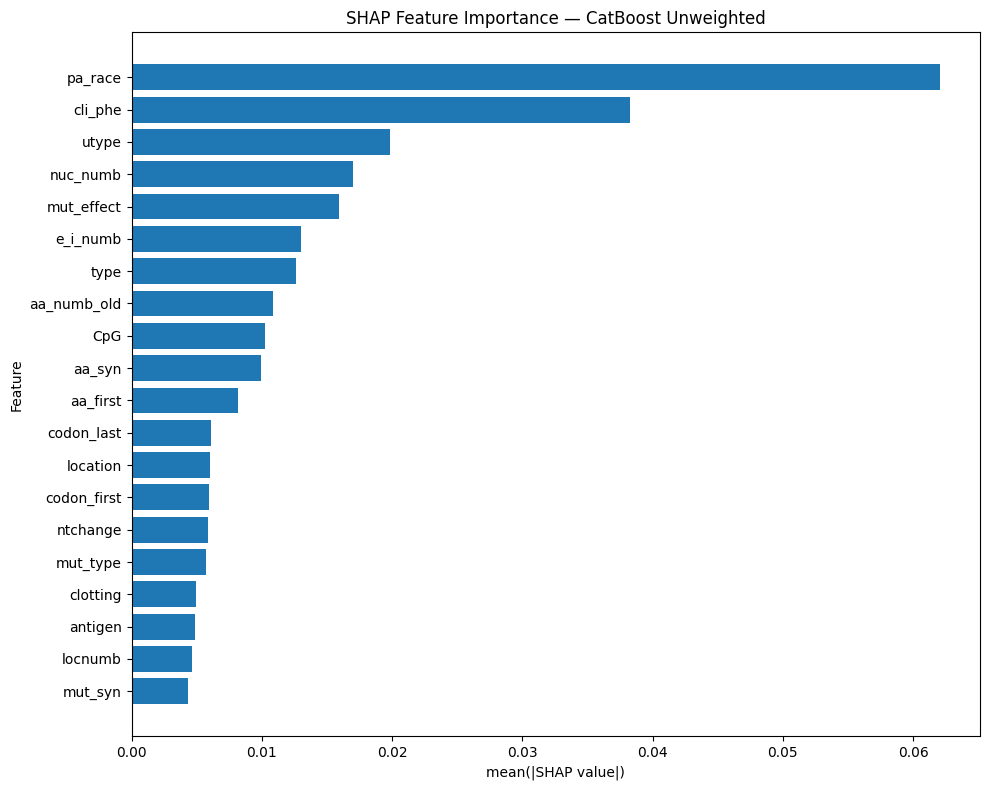


SHAP — BEST MERGED DL
Model: TabTransformer

Training selected DL model...

Calculating SHAP for: TabTransformer


PermutationExplainer explainer: 51it [00:45,  1.07s/it]


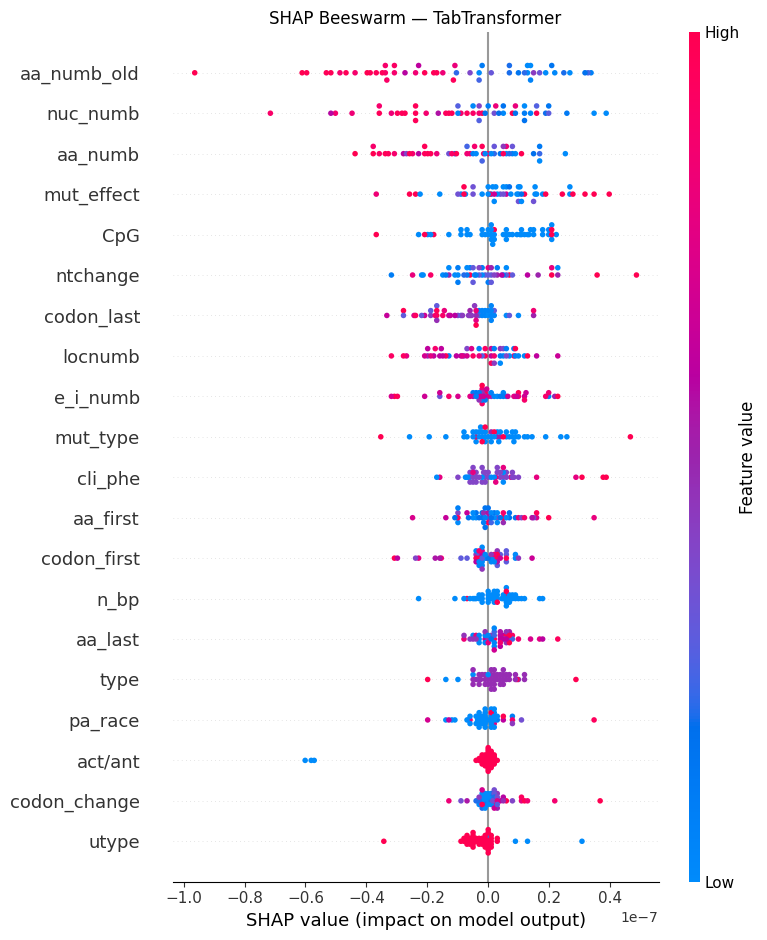


SHAP Beeswarm — TabTransformer


,Feature,Mean |SHAP|
0,aa_numb_old,0.0
1,nuc_numb,0.0
2,aa_numb,0.0
3,mut_effect,0.0
4,CpG,0.0
5,ntchange,0.0
6,codon_last,0.0
7,locnumb,0.0
8,e_i_numb,0.0
9,mut_type,0.0


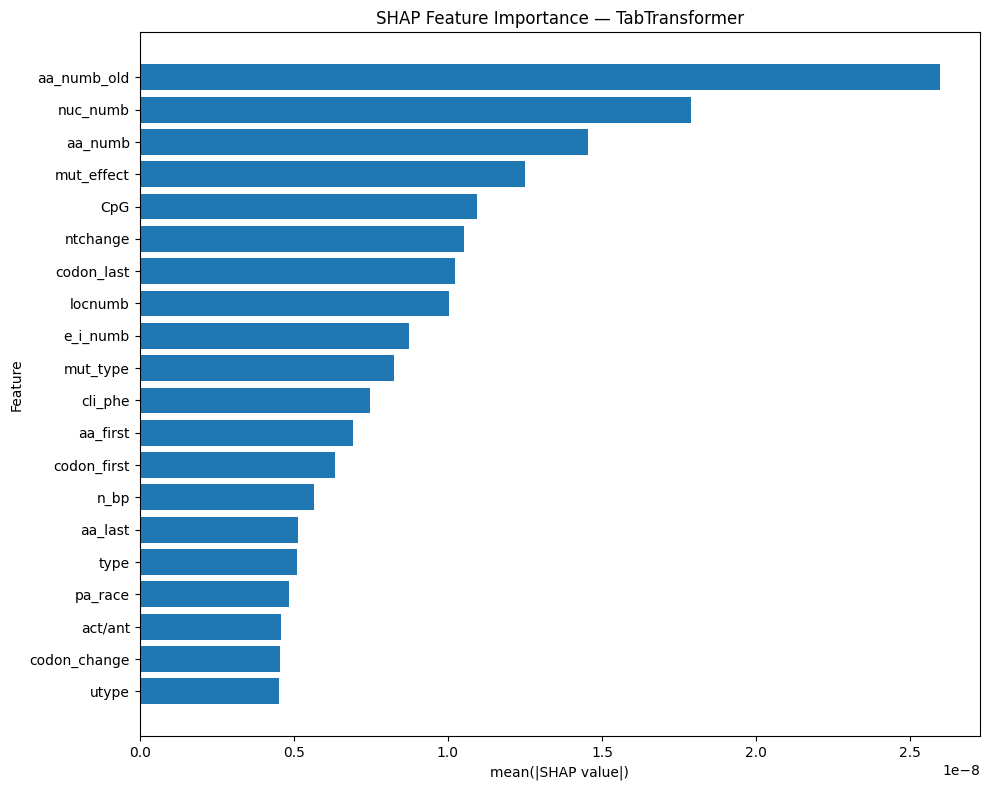


SHAP — BEST MERGED STACK
Stack: All ML + All DL

Calculating SHAP for: All ML + All DL


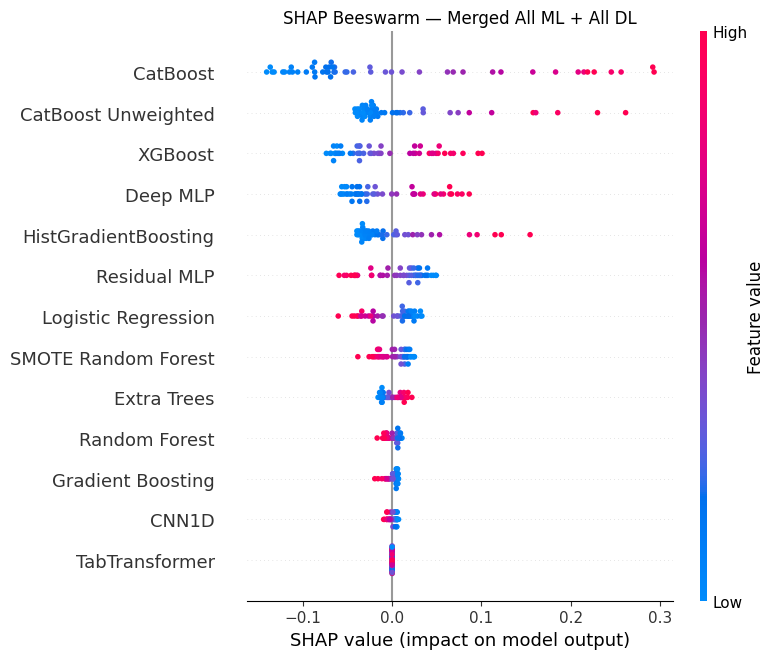


SHAP Beeswarm — Merged All ML + All DL


,Feature,Mean |SHAP|
0,CatBoost,0.108573
1,CatBoost Unweighted,0.047211
2,XGBoost,0.045447
3,Deep MLP,0.041127
4,HistGradientBoosting,0.034513
5,Residual MLP,0.028319
6,Logistic Regression,0.022200
7,SMOTE Random Forest,0.014718
8,Extra Trees,0.010181
9,Random Forest,0.006549


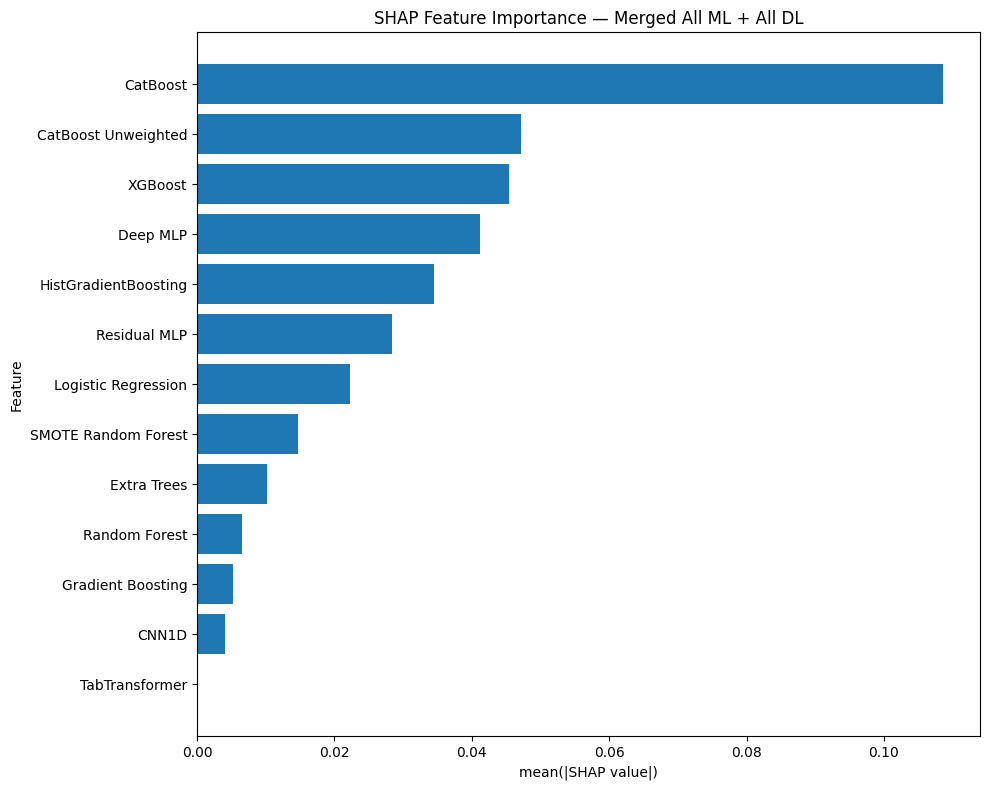

,Analysis,Dataset,Model
0,Best ML,Merged,CatBoost Unweighted
1,Best DL,Merged,TabTransformer
2,Best Stack,Merged,All ML + All DL



✓ SHAP ANALYSIS COMPLETED
✓ Best merged ML: CatBoost Unweighted
✓ Best merged DL: TabTransformer
✓ Best merged stack: All ML + All DL
✓ SHAP beeswarm plots generated.
✓ Mean |SHAP| feature-importance plots generated.
✓ Top-20 SHAP feature tables saved.
✓ Stack SHAP uses base-model probability features.


In [20]:
# ============================================================
# FINAL SHAP ANALYSIS
# BEST MERGED ML + BEST MERGED DL + BEST MERGED STACK
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gc
import warnings

warnings.filterwarnings("ignore")

# ============================================================
# SHAP
# ============================================================

try:
    import shap
except ImportError:
    import sys
    import subprocess

    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "shap"
    ])

    import shap

# ============================================================
# CHECK VARIABLES
# ============================================================

required = [
    "merged",
    "blocks",
    "ml_test_store",
    "dl_test_store",
    "stack_objects",
    "stack_results"
]

missing = [
    x for x in required
    if x not in globals()
]

if missing:
    raise RuntimeError(
        "Missing variables:\n"
        + "\n".join(missing)
        + "\n\nRun the final 9-stack cell first."
    )

# ============================================================
# FEATURES
# ============================================================

GENOMIC_FEATURES = [
    "mut_type",
    "mut_effect",
    "location",
    "e_i_numb",
    "locnumb",
    "aa_numb_old",
    "aa_numb",
    "codon_change",
    "codon_first",
    "codon_last",
    "n_bp",
    "nuc_numb",
    "ntchange",
    "mut_syn",
    "aa_change",
    "aa_first",
    "aa_last",
    "aa_syn",
    "CpG",
    "utype"
]

CLINICAL_FEATURES = [
    "clotting",
    "discrep",
    "ratio",
    "assay",
    "antigen",
    "act/ant",
    "type",
    "pa_race",
    "cli_phe"
]

MERGED_FEATURES = (
    GENOMIC_FEATURES +
    CLINICAL_FEATURES
)

# ============================================================
# MERGED BLOCK
# ============================================================

(
    Xtr_m,
    ytr_m,
    gtr_m,
    Xva_m,
    yva_m,
    gva_m,
    Xte_m,
    yte_m,
    gte_m
) = blocks["Merged"]

Xtr_m = Xtr_m[
    MERGED_FEATURES
].copy()

Xva_m = Xva_m[
    MERGED_FEATURES
].copy()

Xte_m = Xte_m[
    MERGED_FEATURES
].copy()

# ============================================================
# SETTINGS
# ============================================================

SHAP_BACKGROUND = 30
SHAP_SAMPLES = 50

rng = np.random.default_rng(
    42
)

print(
    "=" * 110
)

print(
    "SHAP ANALYSIS"
)

print(
    "=" * 110
)

# ============================================================
# FIND BEST MERGED ML
# ============================================================

print(
    "\nSelecting best merged ML model..."
)

ml_test = ml_test_store.get(
    "Merged",
    {}
)

if len(ml_test) == 0:
    raise RuntimeError(
        "No merged ML predictions found."
    )

y_test = np.asarray(
    yte_m
).astype(int)

ml_rows = []

for model_name, prob in ml_test.items():

    prob = np.asarray(
        prob,
        dtype=float
    ).reshape(-1)

    pred = (
        prob >= 0.50
    ).astype(int)

    ml_rows.append({

        "Model":
            model_name,

        "Accuracy":
            accuracy_score(
                y_test,
                pred
            ),

        "ROC-AUC":
            roc_auc_score(
                y_test,
                prob
            ),

        "PR-AUC":
            average_precision_score(
                y_test,
                prob
            )
    })

merged_ml_scores = pd.DataFrame(
    ml_rows
)

merged_ml_scores = (
    merged_ml_scores
    .sort_values(
        [
            "Accuracy",
            "ROC-AUC",
            "PR-AUC"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)

best_ml_name = (
    merged_ml_scores.iloc[0]["Model"]
)

print(
    "Best merged ML:",
    best_ml_name
)

display(
    merged_ml_scores.round(4)
)

# ============================================================
# FIND BEST MERGED DL
# ============================================================

print(
    "\nSelecting best merged DL model..."
)

dl_test = dl_test_store.get(
    "Merged",
    {}
)

if len(dl_test) == 0:
    raise RuntimeError(
        "No merged DL predictions found."
    )

dl_rows = []

for model_name, prob in dl_test.items():

    prob = np.asarray(
        prob,
        dtype=float
    ).reshape(-1)

    pred = (
        prob >= 0.50
    ).astype(int)

    dl_rows.append({

        "Model":
            model_name,

        "Accuracy":
            accuracy_score(
                y_test,
                pred
            ),

        "ROC-AUC":
            roc_auc_score(
                y_test,
                prob
            ),

        "PR-AUC":
            average_precision_score(
                y_test,
                prob
            )
    })

merged_dl_scores = pd.DataFrame(
    dl_rows
)

merged_dl_scores = (
    merged_dl_scores
    .sort_values(
        [
            "Accuracy",
            "ROC-AUC",
            "PR-AUC"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)

best_dl_name = (
    merged_dl_scores.iloc[0]["Model"]
)

print(
    "Best merged DL:",
    best_dl_name
)

display(
    merged_dl_scores.round(4)
)

# ============================================================
# FIND BEST MERGED STACK
# ============================================================

print(
    "\nSelecting best merged stack..."
)

sr = stack_results.copy()

sr_merged = sr[
    sr["Dataset"]
    .astype(str)
    .str.lower()
    == "merged"
].copy()

if len(sr_merged) == 0:
    raise RuntimeError(
        "No merged stack result found."
    )

sr_merged = (
    sr_merged
    .sort_values(
        [
            "Accuracy",
            "ROC-AUC",
            "PR-AUC"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)

best_stack_name = (
    sr_merged.iloc[0]["Stack"]
)

if best_stack_name == "All ML":
    best_stack_key = "Merged_All_ML"

elif best_stack_name == "All DL":
    best_stack_key = "Merged_All_DL"

elif best_stack_name == "All ML + All DL":
    best_stack_key = "Merged_All_ML_DL"

else:
    raise ValueError(
        f"Unknown stack: {best_stack_name}"
    )

print(
    "Best merged stack:",
    best_stack_name
)

display(
    sr_merged.round(4)
)

# ============================================================
# FUNCTION:
# NUMERIC REPRESENTATION FOR SHAP
# ============================================================

def make_shap_numeric_reference(
    X_train,
    X_explain
):

    X_train = X_train[
        MERGED_FEATURES
    ].copy()

    X_explain = X_explain[
        MERGED_FEATURES
    ].copy()

    train_num = pd.DataFrame(
        index=X_train.index
    )

    explain_num = pd.DataFrame(
        index=X_explain.index
    )

    for col in MERGED_FEATURES:

        # ----------------------------------------------------
        # Numeric
        # ----------------------------------------------------

        if pd.api.types.is_numeric_dtype(
            X_train[col]
        ):

            tr = pd.to_numeric(
                X_train[col],
                errors="coerce"
            )

            ex = pd.to_numeric(
                X_explain[col],
                errors="coerce"
            )

            median_value = (
                tr.median()
            )

            if pd.isna(
                median_value
            ):
                median_value = 0.0

            tr = tr.fillna(
                median_value
            )

            ex = ex.fillna(
                median_value
            )

            train_num[col] = (
                tr.astype(float)
            )

            explain_num[col] = (
                ex.astype(float)
            )

        # ----------------------------------------------------
        # Categorical
        # ----------------------------------------------------

        else:

            combined = pd.concat(
                [
                    X_train[col],
                    X_explain[col]
                ],
                ignore_index=True
            )

            combined = (
                combined
                .fillna("__MISSING__")
                .astype(str)
            )

            categories = pd.Index(
                combined.unique()
            )

            mapping = {
                value: idx
                for idx, value
                in enumerate(categories)
            }

            tr = (
                X_train[col]
                .fillna("__MISSING__")
                .astype(str)
                .map(mapping)
                .astype(float)
            )

            ex = (
                X_explain[col]
                .fillna("__MISSING__")
                .astype(str)
                .map(mapping)
                .astype(float)
            )

            train_num[col] = tr
            explain_num[col] = ex

    train_num = train_num.replace(
        [np.inf, -np.inf],
        np.nan
    ).fillna(0)

    explain_num = explain_num.replace(
        [np.inf, -np.inf],
        np.nan
    ).fillna(0)

    return (
        train_num.reset_index(drop=True),
        explain_num.reset_index(drop=True)
    )

# ============================================================
# SHAP PLOT FUNCTION
# ============================================================

def plot_shap_summary(
    shap_values,
    X_display,
    title,
    output_stem,
    max_features=20
):

    shap_values = np.asarray(
        shap_values,
        dtype=float
    )

    if shap_values.ndim == 3:

        if shap_values.shape[-1] == 2:
            shap_values = (
                shap_values[:, :, 1]
            )
        else:
            shap_values = (
                shap_values[:, :, 0]
            )

    shap_values = np.squeeze(
        shap_values
    )

    if shap_values.ndim != 2:
        raise ValueError(
            f"Invalid SHAP shape: "
            f"{shap_values.shape}"
        )

    X_display = (
        X_display
        .reset_index(drop=True)
        .copy()
    )

    feature_names = np.asarray(
        X_display.columns.astype(str)
    )

    if (
        shap_values.shape[1]
        != len(feature_names)
    ):
        raise ValueError(
            "SHAP feature count mismatch: "
            f"{shap_values.shape[1]} vs "
            f"{len(feature_names)}"
        )

    mean_abs = np.mean(
        np.abs(shap_values),
        axis=0
    )

    max_features = min(
        max_features,
        len(feature_names)
    )

    order = np.argsort(
        mean_abs
    )[::-1][
        :max_features
    ]

    top_values = (
        shap_values[:, order]
    )

    top_names = (
        feature_names[order]
    )

    X_top = X_display.iloc[
        :,
        order
    ]

    explanation = shap.Explanation(
        values=top_values,
        base_values=np.zeros(
            top_values.shape[0]
        ),
        data=X_top.to_numpy(),
        feature_names=top_names
    )

    # ========================================================
    # BEESWARM
    # ========================================================

    plt.figure(
        figsize=(10, 8)
    )

    shap.plots.beeswarm(
        explanation,
        max_display=max_features,
        show=False
    )

    plt.title(
        title
    )

    plt.tight_layout()

    plt.savefig(
        f"{output_stem}_beeswarm.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    # ========================================================
    # BAR
    # ========================================================

    top_df = pd.DataFrame({

        "Feature":
            top_names,

        "Mean |SHAP|":
            mean_abs[order]

    })

    print(
        "\n" + "=" * 90
    )

    print(
        title
    )

    print(
        "=" * 90
    )

    display(
        top_df.round(6)
    )

    plt.figure(
        figsize=(10, 8)
    )

    plt.barh(
        np.arange(
            len(top_names)
        ),
        mean_abs[order][::-1]
    )

    plt.yticks(
        np.arange(
            len(top_names)
        ),
        top_names[::-1]
    )

    plt.xlabel(
        "mean(|SHAP value|)"
    )

    plt.ylabel(
        "Feature"
    )

    plt.title(
        title.replace(
            "Beeswarm",
            "Feature Importance"
        )
    )

    plt.tight_layout()

    plt.savefig(
        f"{output_stem}_bar.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    top_df.to_csv(
        f"{output_stem}_top20.csv",
        index=False
    )

    return top_df

# ============================================================
# 1. BEST ML — SHAP
# ============================================================

print(
    "\n" + "=" * 110
)

print(
    "SHAP — BEST MERGED ML"
)

print(
    "=" * 110
)

print(
    "Model:",
    best_ml_name
)

# ------------------------------------------------------------
# Rebuild best ML model
# ------------------------------------------------------------

best_ml_model, best_ml_type = (
    build_ml_model(
        best_ml_name,
        Xtr_m,
        np.asarray(ytr_m).astype(int)
    )
)

# ------------------------------------------------------------
# Fit
# ------------------------------------------------------------

if best_ml_type == "catboost":

    X_train_cb, cats = (
        make_catboost_frame(
            Xtr_m
        )
    )

    best_ml_model.fit(
        X_train_cb,
        np.asarray(ytr_m).astype(int),
        cat_features=cats
    )

else:

    best_ml_model.fit(
        Xtr_m,
        np.asarray(ytr_m).astype(int)
    )

# ------------------------------------------------------------
# Numeric SHAP representation
# ------------------------------------------------------------

X_bg_original = take_subset(
    Xtr_m,
    SHAP_BACKGROUND
)

X_explain_original = take_subset(
    Xte_m,
    SHAP_SAMPLES
)

(
    X_bg_ml,
    X_explain_ml
) = make_shap_numeric_reference(
    X_bg_original,
    X_explain_original
)

# ------------------------------------------------------------
# Prediction wrapper
# ------------------------------------------------------------
# SHAP passes numeric values.
# Convert them back to the model's expected
# categorical/numeric representation.
# ------------------------------------------------------------

def ml_predict_from_numeric(
    X_numeric
):

    X_numeric = pd.DataFrame(
        X_numeric,
        columns=MERGED_FEATURES
    )

    X_model = pd.DataFrame()

    for col in MERGED_FEATURES:

        if (
            pd.api.types.is_numeric_dtype(
                Xtr_m[col]
            )
        ):

            X_model[col] = (
                X_numeric[col]
                .astype(float)
            )

        else:

            # Reconstruct using the training
            # categorical levels.
            original = (
                Xtr_m[col]
                .fillna("__MISSING__")
                .astype(str)
            )

            category_values = (
                pd.Index(
                    pd.concat(
                        [
                            Xtr_m[col],
                            Xte_m[col]
                        ],
                        ignore_index=True
                    )
                    .fillna("__MISSING__")
                    .astype(str)
                    .unique()
                )
            )

            numeric_values = (
                X_numeric[col]
                .round()
                .astype(int)
            )

            numeric_values = (
                numeric_values.clip(
                    0,
                    max(
                        len(category_values) - 1,
                        0
                    )
                )
            )

            X_model[col] = (
                numeric_values.map(
                    lambda i:
                    category_values[
                        int(i)
                    ]
                )
            )

    if best_ml_type == "catboost":

        X_cb, _ = (
            make_catboost_frame(
                X_model
            )
        )

        return (
            best_ml_model
            .predict_proba(X_cb)[:, 1]
        )

    return (
        best_ml_model
        .predict_proba(X_model)[:, 1]
    )

print(
    "\nCalculating SHAP for:",
    best_ml_name
)

ml_explainer = shap.Explainer(
    ml_predict_from_numeric,
    X_bg_ml,
    algorithm="permutation"
)

ml_sv = ml_explainer(
    X_explain_ml,
    max_evals=(
        2 * len(MERGED_FEATURES) + 1
    )
)

ml_top20 = plot_shap_summary(
    ml_sv.values,
    X_explain_ml,
    f"SHAP Beeswarm — {best_ml_name}",
    "SHAP_Best_ML_Merged",
    max_features=20
)

del best_ml_model
gc.collect()

# ============================================================
# 2. BEST DL — SHAP
# ============================================================

print(
    "\n" + "=" * 110
)

print(
    "SHAP — BEST MERGED DL"
)

print(
    "=" * 110
)

print(
    "Model:",
    best_dl_name
)

if not TF_AVAILABLE:

    raise RuntimeError(
        "TensorFlow is not available."
    )

# ------------------------------------------------------------
# Prepare DL arrays exactly as stacking pipeline
# ------------------------------------------------------------

(
    A_train_dl,
    A_val_dl,
    A_test_dl
) = prepare_dl_arrays(
    Xtr_m,
    Xva_m,
    Xte_m
)

# ------------------------------------------------------------
# Build model
# ------------------------------------------------------------

tf.keras.backend.clear_session()

dl_model = DL_BUILDERS[
    best_dl_name
](
    A_train_dl.shape[1]
)

dl_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

y_train_dl = (
    np.asarray(ytr_m)
    .astype("float32")
)

y_val_dl = (
    np.asarray(yva_m)
    .astype("float32")
)

pos = max(
    int(
        np.sum(
            y_train_dl == 1
        )
    ),
    1
)

neg = max(
    int(
        np.sum(
            y_train_dl == 0
        )
    ),
    1
)

class_weight_dl = {
    0: 1.0,
    1: neg / pos
}

early_stop = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

print(
    "\nTraining selected DL model..."
)

dl_model.fit(
    A_train_dl,
    y_train_dl,
    validation_data=(
        A_val_dl,
        y_val_dl
    ),
    epochs=25,
    batch_size=64,
    class_weight=class_weight_dl,
    callbacks=[early_stop],
    verbose=0
)

# ------------------------------------------------------------
# Numeric SHAP reference
# ------------------------------------------------------------

X_bg_original_dl = take_subset(
    Xtr_m,
    SHAP_BACKGROUND
)

X_explain_original_dl = take_subset(
    Xte_m,
    SHAP_SAMPLES
)

(
    X_bg_dl_display,
    X_explain_dl_display
) = make_shap_numeric_reference(
    X_bg_original_dl,
    X_explain_original_dl
)

# ------------------------------------------------------------
# For DL SHAP, numeric feature representation is used directly
# ------------------------------------------------------------

def dl_predict_numeric(
    X_numeric
):

    X_numeric = pd.DataFrame(
        X_numeric,
        columns=MERGED_FEATURES
    )

    # Convert using the SAME preparation logic.
    # Numeric inputs are already encoded.
    A = X_numeric.to_numpy(
        dtype=np.float32
    )

    # Scale using training data
    train_numeric, _ = (
        make_shap_numeric_reference(
            Xtr_m,
            Xtr_m
        )
    )

    train_arr = (
        train_numeric
        .to_numpy(
            dtype=np.float32
        )
    )

    mean = np.mean(
        train_arr,
        axis=0,
        keepdims=True
    )

    std = np.std(
        train_arr,
        axis=0,
        keepdims=True
    )

    std[
        std < 1e-8
    ] = 1.0

    A = (
        A - mean
    ) / std

    A = np.nan_to_num(
        A,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    return (
        dl_model
        .predict(
            A,
            verbose=0
        )
        .reshape(-1)
    )

print(
    "\nCalculating SHAP for:",
    best_dl_name
)

dl_explainer = shap.Explainer(
    dl_predict_numeric,
    X_bg_dl_display,
    algorithm="permutation"
)

dl_sv = dl_explainer(
    X_explain_dl_display,
    max_evals=(
        2 * len(MERGED_FEATURES) + 1
    )
)

dl_top20 = plot_shap_summary(
    dl_sv.values,
    X_explain_dl_display,
    f"SHAP Beeswarm — {best_dl_name}",
    "SHAP_Best_DL_Merged",
    max_features=20
)

del dl_model
gc.collect()

tf.keras.backend.clear_session()

# ============================================================
# 3. BEST STACK — SHAP
# ============================================================

print(
    "\n" + "=" * 110
)

print(
    "SHAP — BEST MERGED STACK"
)

print(
    "=" * 110
)

print(
    "Stack:",
    best_stack_name
)

stack_obj = stack_objects[
    best_stack_key
]

meta_model = stack_obj[
    "meta_model"
]

model_names = stack_obj[
    "models"
]

meta_test = np.asarray(
    stack_obj[
        "test_meta_features"
    ],
    dtype=float
)

if meta_test.ndim == 1:

    meta_test = (
        meta_test.reshape(-1, 1)
    )

if (
    len(model_names)
    == meta_test.shape[1]
):

    meta_names = [
        str(x)
        for x in model_names
    ]

else:

    meta_names = [
        f"Base_Model_{i+1}"
        for i in range(
            meta_test.shape[1]
        )
    ]

X_meta = pd.DataFrame(
    meta_test,
    columns=meta_names
)

X_bg_stack = take_subset(
    X_meta,
    SHAP_BACKGROUND
)

X_explain_stack = take_subset(
    X_meta,
    SHAP_SAMPLES
)

def stack_predict(
    X
):

    X = np.asarray(
        X,
        dtype=float
    )

    return (
        meta_model
        .predict_proba(X)[:, 1]
    )

print(
    "\nCalculating SHAP for:",
    best_stack_name
)

stack_explainer = shap.Explainer(
    stack_predict,
    X_bg_stack,
    algorithm="permutation"
)

stack_sv = stack_explainer(
    X_explain_stack,
    max_evals=(
        2 * X_meta.shape[1] + 1
    )
)

stack_top20 = plot_shap_summary(
    stack_sv.values,
    X_explain_stack,
    f"SHAP Beeswarm — Merged {best_stack_name}",
    "SHAP_Best_Stack_Merged",
    max_features=min(
        20,
        X_meta.shape[1]
    )
)

# ============================================================
# SAVE SHAP SUMMARY
# ============================================================

shap_summary = pd.DataFrame({

    "Analysis": [
        "Best ML",
        "Best DL",
        "Best Stack"
    ],

    "Dataset": [
        "Merged",
        "Merged",
        "Merged"
    ],

    "Model": [
        best_ml_name,
        best_dl_name,
        best_stack_name
    ]
})

shap_summary.to_csv(
    "SHAP_BEST_MODELS_SUMMARY.csv",
    index=False
)

display(
    shap_summary
)

# ============================================================
# FINAL
# ============================================================

print(
    "\n" + "=" * 110
)

print(
    "✓ SHAP ANALYSIS COMPLETED"
)

print(
    "=" * 110
)

print(
    "✓ Best merged ML:",
    best_ml_name
)

print(
    "✓ Best merged DL:",
    best_dl_name
)

print(
    "✓ Best merged stack:",
    best_stack_name
)

print(
    "✓ SHAP beeswarm plots generated."
)

print(
    "✓ Mean |SHAP| feature-importance plots generated."
)

print(
    "✓ Top-20 SHAP feature tables saved."
)

print(
    "✓ Stack SHAP uses base-model probability features."
)

LIME ANALYSIS

Selecting best merged ML model...
Best ML: CatBoost Unweighted


,Model,Accuracy,ROC-AUC,PR-AUC
0,CatBoost Unweighted,0.8360,0.8028,0.5973
1,HistGradientBoosting,0.8289,0.7696,0.5331
2,Gradient Boosting,0.8146,0.7898,0.5439
3,CatBoost,0.7986,0.7984,0.5742
4,Logistic Regression,0.7861,0.7602,0.4568
5,XGBoost,0.7638,0.7602,0.5088
6,SMOTE Random Forest,0.7487,0.7558,0.5050
7,Extra Trees,0.7469,0.7522,0.4934
8,Random Forest,0.7451,0.7565,0.5040



Selecting best merged DL model...
Best DL: TabTransformer


,Model,Accuracy,ROC-AUC,PR-AUC
0,TabTransformer,0.8021,0.4857,0.1970
1,CNN1D,0.7219,0.7559,0.4944
2,Residual MLP,0.7219,0.7383,0.4533
3,Deep MLP,0.7201,0.7458,0.4621



Selecting best merged stack...
Best Stack: All ML + All DL


,Dataset,Stack,Base Models,Models,Accuracy,Balanced Accuracy,Precision,Recall,Specificity,Sensitivity,F1,MCC,ROC-AUC,PR-AUC,Brier,Threshold
0,Merged,All ML + All DL,13,Logistic Regression + Random Forest + Extra Tr...,0.8467,0.6550,0.7500,0.3378,0.9722,0.3378,0.4658,0.4335,0.7927,0.5749,0.1703,0.855
1,Merged,All ML,9,Logistic Regression + Random Forest + Extra Tr...,0.8458,0.6511,0.7526,0.3288,0.9733,0.3288,0.4577,0.4283,0.7926,0.5773,0.1704,0.860
2,Merged,All DL,4,Deep MLP + Residual MLP + CNN1D + TabTransformer,0.8102,0.5237,0.8462,0.0495,0.9978,0.0495,0.0936,0.1762,0.7487,0.4754,0.2104,0.810



LIME — BEST MERGED ML
Model: CatBoost Unweighted
Explaining test sample: 1094

LIME — Merged CatBoost Unweighted — Test Sample 1094


,Feature,LIME Weight
0,1.00 < cli_phe <= 2.00,0.09344
1,assay <= 0.00,-0.07288
2,ratio <= 0.00,0.06517
3,CpG > 0.00,0.04255
4,1.00 < mut_effect <= 3.00,0.03749
5,aa_syn > 743.00,0.03465
6,discrep <= 10.00,0.02909
7,type <= 0.00,-0.02562
8,aa_last <= 2.00,-0.02373
9,11.00 < codon_last <= 42.00,-0.02075


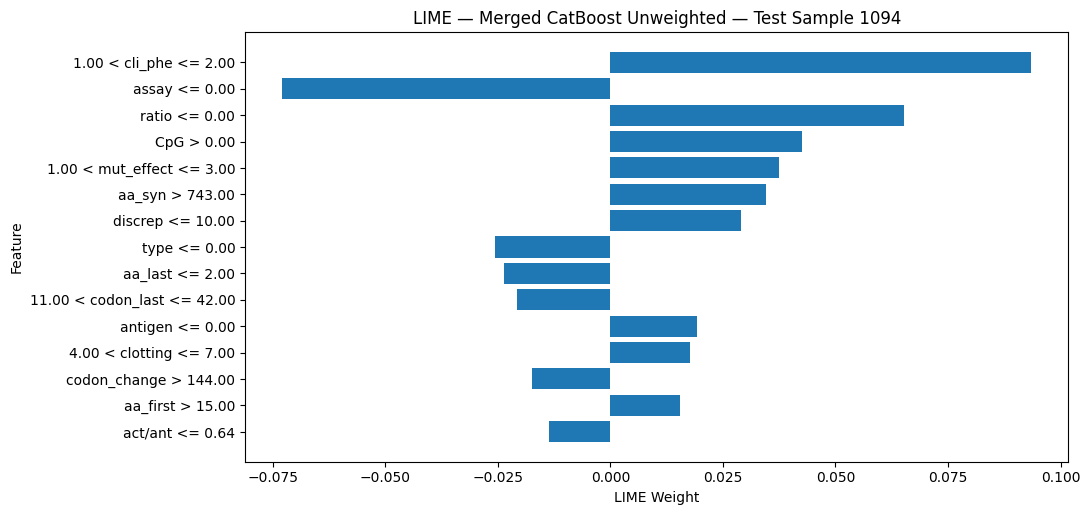


LIME — BEST MERGED DL
Model: TabTransformer
Explaining test sample: 770

LIME — Merged TabTransformer — Test Sample 770


,Feature,LIME Weight
0,act/ant <= 0.64,0.0
1,discrep <= 10.00,0.0
2,assay <= 0.00,-0.0
3,ratio <= 0.00,-0.0
4,CpG <= 0.00,0.0
5,mut_effect <= 1.00,0.0
6,aa_numb > 1880.00,0.0
7,codon_change > 144.00,-0.0
8,mut_type <= 0.00,0.0
9,aa_numb_old > 1844.00,0.0


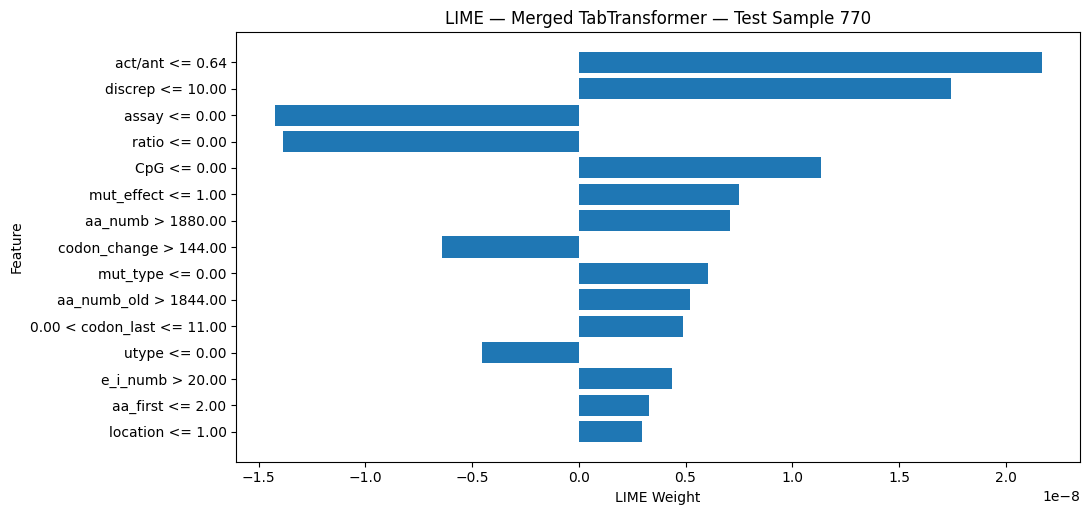


LIME — BEST MERGED STACK
Stack: All ML + All DL
Explaining test sample: 577

LIME — Merged All ML + All DL — Test Sample 577


,Feature,LIME Weight
0,HistGradientBoosting > 0.17,0.12021
1,XGBoost > 0.51,0.11863
2,CNN1D > 0.52,-0.04228
3,Gradient Boosting > 0.16,-0.03952
4,0.35 < Deep MLP <= 0.56,0.03507
5,0.28 < CatBoost <= 0.48,0.02868
6,Random Forest > 0.49,-0.02525
7,0.36 < Residual MLP <= 0.52,-0.02421
8,0.09 < CatBoost Unweighted <= 0.18,-0.01511
9,0.37 < SMOTE Random Forest <= 0.49,-0.01484


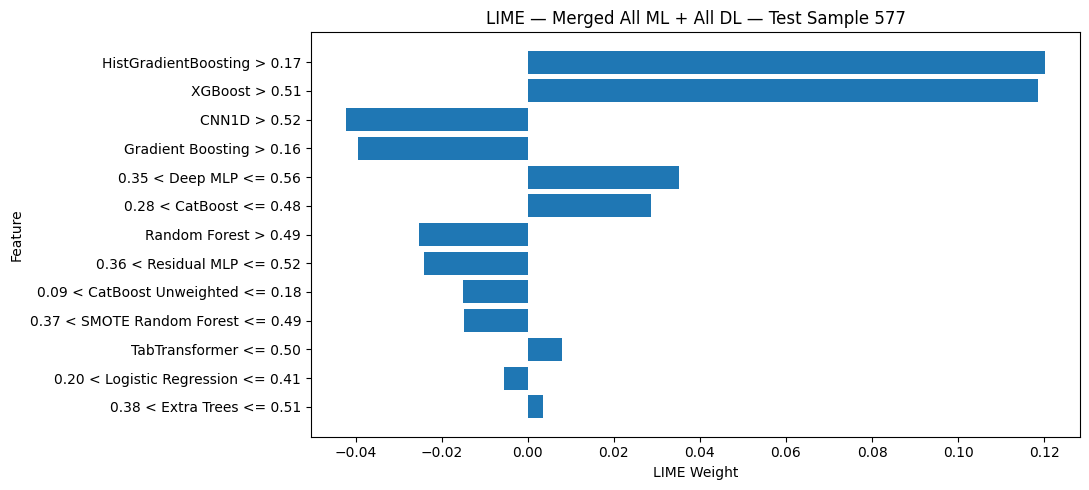


LIME SUMMARY


,Analysis,Dataset,Model
0,Best ML,Merged,CatBoost Unweighted
1,Best DL,Merged,TabTransformer
2,Best Stack,Merged,All ML + All DL



✓ LIME ANALYSIS COMPLETED
✓ Best merged ML: CatBoost Unweighted
✓ Best merged DL: TabTransformer
✓ Best merged stack: All ML + All DL
✓ LIME plots saved.
✓ LIME tables saved.
✓ LIME summary saved.


In [22]:
# ============================================================
# FINAL LIME ANALYSIS
# BEST MERGED ML + BEST MERGED DL + BEST MERGED STACK
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gc
import warnings

warnings.filterwarnings("ignore")

# ============================================================
# LIME IMPORT
# ============================================================

try:
    from lime.lime_tabular import LimeTabularExplainer

except ImportError:

    import sys
    import subprocess

    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "lime"
    ])

    from lime.lime_tabular import LimeTabularExplainer

# ============================================================
# CHECK REQUIRED VARIABLES
# ============================================================

required = [
    "blocks",
    "ml_test_store",
    "dl_test_store",
    "stack_objects",
    "stack_results"
]

missing = [
    x for x in required
    if x not in globals()
]

if missing:

    raise RuntimeError(
        "Missing variables:\n"
        + "\n".join(missing)
        + "\n\nRun the final 9-stack cell first."
    )

# ============================================================
# SETTINGS
# ============================================================

LIME_NUM_SAMPLES = 500
LIME_FEATURES = 15
RANDOM_STATE = 42

print(
    "=" * 110
)

print(
    "LIME ANALYSIS"
)

print(
    "=" * 110
)

# ============================================================
# FEATURE LIST
# ============================================================

GENOMIC_FEATURES = [
    "mut_type",
    "mut_effect",
    "location",
    "e_i_numb",
    "locnumb",
    "aa_numb_old",
    "aa_numb",
    "codon_change",
    "codon_first",
    "codon_last",
    "n_bp",
    "nuc_numb",
    "ntchange",
    "mut_syn",
    "aa_change",
    "aa_first",
    "aa_last",
    "aa_syn",
    "CpG",
    "utype"
]

CLINICAL_FEATURES = [
    "clotting",
    "discrep",
    "ratio",
    "assay",
    "antigen",
    "act/ant",
    "type",
    "pa_race",
    "cli_phe"
]

MERGED_FEATURES = (
    GENOMIC_FEATURES +
    CLINICAL_FEATURES
)

# ============================================================
# GET MERGED BLOCK
# ============================================================

(
    Xtr,
    ytr,
    gtr,
    Xva,
    yva,
    gva,
    Xte,
    yte,
    gte
) = blocks["Merged"]

Xtr = Xtr[
    MERGED_FEATURES
].copy()

Xva = Xva[
    MERGED_FEATURES
].copy()

Xte = Xte[
    MERGED_FEATURES
].copy()

y_test = np.asarray(
    yte
).astype(int)

# ============================================================
# LIME PLOT HELPER
# ============================================================

def compact_lime_plot(
    explanation,
    title,
    output_stem,
    top_n=LIME_FEATURES
):

    values = explanation.as_list(
        label=1
    )

    table = pd.DataFrame(
        values,
        columns=[
            "Feature",
            "LIME Weight"
        ]
    ).head(
        top_n
    )

    print(
        "\n" + "=" * 90
    )

    print(
        title
    )

    print(
        "=" * 90
    )

    display(
        table.round(5)
    )

    # --------------------------------------------------------
    # Plot
    # --------------------------------------------------------

    plt.figure(
        figsize=(
            11,
            max(
                5,
                0.35 * len(table)
            )
        )
    )

    vals = table[
        "LIME Weight"
    ].to_numpy()

    names = (
        table[
            "Feature"
        ]
        .astype(str)
        .to_numpy()
    )

    plt.barh(
        np.arange(
            len(names)
        ),
        vals
    )

    plt.yticks(
        np.arange(
            len(names)
        ),
        names
    )

    plt.xlabel(
        "LIME Weight"
    )

    plt.ylabel(
        "Feature"
    )

    plt.title(
        title
    )

    plt.gca().invert_yaxis()

    plt.tight_layout()

    plt.savefig(
        f"{output_stem}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    table.to_csv(
        f"{output_stem}.csv",
        index=False
    )

    return table

# ============================================================
# CREATE NUMERIC REPRESENTATION FOR LIME
# ============================================================

def make_lime_numeric(
    X_train,
    X_data
):

    X_train = X_train[
        MERGED_FEATURES
    ].copy()

    X_data = X_data[
        MERGED_FEATURES
    ].copy()

    train_num = pd.DataFrame(
        index=X_train.index
    )

    data_num = pd.DataFrame(
        index=X_data.index
    )

    for col in MERGED_FEATURES:

        # ----------------------------------------------------
        # Numeric
        # ----------------------------------------------------

        if pd.api.types.is_numeric_dtype(
            X_train[col]
        ):

            tr = pd.to_numeric(
                X_train[col],
                errors="coerce"
            )

            da = pd.to_numeric(
                X_data[col],
                errors="coerce"
            )

            med = tr.median()

            if pd.isna(med):
                med = 0.0

            train_num[col] = (
                tr.fillna(med)
                .astype(float)
            )

            data_num[col] = (
                da.fillna(med)
                .astype(float)
            )

        # ----------------------------------------------------
        # Categorical
        # ----------------------------------------------------

        else:

            combined = pd.concat(
                [
                    X_train[col],
                    X_data[col]
                ],
                ignore_index=True
            )

            combined = (
                combined
                .fillna("__MISSING__")
                .astype(str)
            )

            categories = (
                pd.Index(
                    combined.unique()
                )
            )

            mapping = {
                value: idx
                for idx, value
                in enumerate(
                    categories
                )
            }

            train_num[col] = (
                X_train[col]
                .fillna("__MISSING__")
                .astype(str)
                .map(mapping)
                .astype(float)
            )

            data_num[col] = (
                X_data[col]
                .fillna("__MISSING__")
                .astype(str)
                .map(mapping)
                .astype(float)
            )

    train_num = (
        train_num
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
        .fillna(0)
    )

    data_num = (
        data_num
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
        .fillna(0)
    )

    return (
        train_num.reset_index(
            drop=True
        ),
        data_num.reset_index(
            drop=True
        )
    )

# ============================================================
# 1. BEST MERGED ML
# ============================================================

print(
    "\nSelecting best merged ML model..."
)

merged_ml_test = ml_test_store.get(
    "Merged",
    {}
)

if len(merged_ml_test) == 0:

    raise RuntimeError(
        "No merged ML predictions found."
    )

ml_rows = []

for model_name, probability in (
    merged_ml_test.items()
):

    probability = np.asarray(
        probability,
        dtype=float
    ).reshape(-1)

    pred = (
        probability >= 0.50
    ).astype(int)

    ml_rows.append({

        "Model":
            model_name,

        "Accuracy":
            accuracy_score(
                y_test,
                pred
            ),

        "ROC-AUC":
            roc_auc_score(
                y_test,
                probability
            ),

        "PR-AUC":
            average_precision_score(
                y_test,
                probability
            )
    })

merged_ml_scores = (
    pd.DataFrame(
        ml_rows
    )
    .sort_values(
        [
            "Accuracy",
            "ROC-AUC",
            "PR-AUC"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)

best_ml_name = (
    merged_ml_scores
    .iloc[0]["Model"]
)

print(
    "Best ML:",
    best_ml_name
)

display(
    merged_ml_scores.round(4)
)

# ============================================================
# 2. BEST MERGED DL
# ============================================================

print(
    "\nSelecting best merged DL model..."
)

merged_dl_test = dl_test_store.get(
    "Merged",
    {}
)

if len(merged_dl_test) == 0:

    raise RuntimeError(
        "No merged DL predictions found."
    )

dl_rows = []

for model_name, probability in (
    merged_dl_test.items()
):

    probability = np.asarray(
        probability,
        dtype=float
    ).reshape(-1)

    pred = (
        probability >= 0.50
    ).astype(int)

    dl_rows.append({

        "Model":
            model_name,

        "Accuracy":
            accuracy_score(
                y_test,
                pred
            ),

        "ROC-AUC":
            roc_auc_score(
                y_test,
                probability
            ),

        "PR-AUC":
            average_precision_score(
                y_test,
                probability
            )
    })

merged_dl_scores = (
    pd.DataFrame(
        dl_rows
    )
    .sort_values(
        [
            "Accuracy",
            "ROC-AUC",
            "PR-AUC"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)

best_dl_name = (
    merged_dl_scores
    .iloc[0]["Model"]
)

print(
    "Best DL:",
    best_dl_name
)

display(
    merged_dl_scores.round(4)
)

# ============================================================
# 3. BEST MERGED STACK
# ============================================================

print(
    "\nSelecting best merged stack..."
)

sr = stack_results.copy()

sr_merged = sr[
    sr["Dataset"]
    .astype(str)
    .str.lower()
    == "merged"
].copy()

if len(sr_merged) == 0:

    raise RuntimeError(
        "No merged stack result found."
    )

sr_merged = (
    sr_merged
    .sort_values(
        [
            "Accuracy",
            "ROC-AUC",
            "PR-AUC"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)

best_stack_name = (
    sr_merged.iloc[0]["Stack"]
)

if best_stack_name == "All ML":

    best_stack_key = (
        "Merged_All_ML"
    )

elif best_stack_name == "All DL":

    best_stack_key = (
        "Merged_All_DL"
    )

elif best_stack_name == "All ML + All DL":

    best_stack_key = (
        "Merged_All_ML_DL"
    )

else:

    raise ValueError(
        f"Unknown stack: "
        f"{best_stack_name}"
    )

print(
    "Best Stack:",
    best_stack_name
)

display(
    sr_merged.round(4)
)

# ============================================================
# 4. BEST ML LIME
# ============================================================

print(
    "\n" + "=" * 110
)

print(
    "LIME — BEST MERGED ML"
)

print(
    "=" * 110
)

print(
    "Model:",
    best_ml_name
)

# ------------------------------------------------------------
# Rebuild the selected ML model
# ------------------------------------------------------------

best_ml_model, best_ml_type = (
    build_ml_model(
        best_ml_name,
        Xtr,
        np.asarray(ytr).astype(int)
    )
)

# ------------------------------------------------------------
# Fit model
# ------------------------------------------------------------

if best_ml_type == "catboost":

    X_train_cb, cats = (
        make_catboost_frame(
            Xtr
        )
    )

    best_ml_model.fit(
        X_train_cb,
        np.asarray(ytr).astype(int),
        cat_features=cats
    )

else:

    best_ml_model.fit(
        Xtr,
        np.asarray(ytr).astype(int)
    )

# ------------------------------------------------------------
# Numeric LIME representation
# ------------------------------------------------------------

X_train_ml_lime, X_test_ml_lime = (
    make_lime_numeric(
        Xtr,
        Xte
    )
)

X_train_ml_lime = (
    X_train_ml_lime
    .to_numpy(
        dtype=float
    )
)

X_test_ml_lime = (
    X_test_ml_lime
    .to_numpy(
        dtype=float
    )
)

ml_lime_names = [
    str(x)
    for x in MERGED_FEATURES
]

# ------------------------------------------------------------
# Explainer
# ------------------------------------------------------------

ml_explainer = LimeTabularExplainer(
    X_train_ml_lime,
    feature_names=ml_lime_names,
    class_names=[
        "No Inhibitor",
        "Inhibitor"
    ],
    mode="classification",
    random_state=RANDOM_STATE,
    discretize_continuous=True
)

# ------------------------------------------------------------
# Pick test sample near probability 0.50
# ------------------------------------------------------------

def ml_probability_from_numeric(
    X_numeric
):

    X_numeric = np.asarray(
        X_numeric,
        dtype=float
    )

    X_model = pd.DataFrame(
        columns=MERGED_FEATURES
    )

    # Reconstruct mapping separately
    # for categorical variables
    for j, col in enumerate(
        MERGED_FEATURES
    ):

        if pd.api.types.is_numeric_dtype(
            Xtr[col]
        ):

            X_model[col] = (
                X_numeric[:, j]
            )

        else:

            combined = pd.concat(
                [
                    Xtr[col],
                    Xte[col]
                ],
                ignore_index=True
            )

            combined = (
                combined
                .fillna("__MISSING__")
                .astype(str)
            )

            categories = (
                pd.Index(
                    combined.unique()
                )
            )

            values = (
                np.rint(
                    X_numeric[:, j]
                )
                .astype(int)
            )

            values = np.clip(
                values,
                0,
                max(
                    len(categories) - 1,
                    0
                )
            )

            X_model[col] = [
                categories[int(v)]
                for v in values
            ]

    if best_ml_type == "catboost":

        X_cb, _ = (
            make_catboost_frame(
                X_model
            )
        )

        return (
            best_ml_model
            .predict_proba(
                X_cb
            )[:, 1]
        )

    return (
        best_ml_model
        .predict_proba(
            X_model
        )[:, 1]
    )

ml_test_prob = (
    ml_probability_from_numeric(
        X_test_ml_lime
    )
)

ml_idx = int(
    np.argmin(
        np.abs(
            ml_test_prob - 0.5
        )
    )
)

print(
    "Explaining test sample:",
    ml_idx
)

ml_exp = (
    ml_explainer
    .explain_instance(
        X_test_ml_lime[ml_idx],
        lambda z: np.column_stack([
            1.0 -
            ml_probability_from_numeric(z),
            ml_probability_from_numeric(z)
        ]),
        num_features=LIME_FEATURES,
        num_samples=LIME_NUM_SAMPLES
    )
)

ml_lime_table = compact_lime_plot(
    ml_exp,
    (
        f"LIME — Merged "
        f"{best_ml_name} — "
        f"Test Sample {ml_idx}"
    ),
    "LIME_Best_ML_Merged"
)

del best_ml_model
gc.collect()

# ============================================================
# 5. BEST DL LIME
# ============================================================

print(
    "\n" + "=" * 110
)

print(
    "LIME — BEST MERGED DL"
)

print(
    "=" * 110
)

print(
    "Model:",
    best_dl_name
)

if not TF_AVAILABLE:

    raise RuntimeError(
        "TensorFlow is not available."
    )

# ------------------------------------------------------------
# Prepare DL arrays
# ------------------------------------------------------------

(
    A_train_dl,
    A_val_dl,
    A_test_dl
) = prepare_dl_arrays(
    Xtr,
    Xva,
    Xte
)

# ------------------------------------------------------------
# Build selected DL model
# ------------------------------------------------------------

tf.keras.backend.clear_session()

dl_model = DL_BUILDERS[
    best_dl_name
](
    A_train_dl.shape[1]
)

dl_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

y_train_dl = np.asarray(
    ytr
).astype("float32")

y_val_dl = np.asarray(
    yva
).astype("float32")

pos = max(
    int(
        np.sum(
            y_train_dl == 1
        )
    ),
    1
)

neg = max(
    int(
        np.sum(
            y_train_dl == 0
        )
    ),
    1
)

class_weight_dl = {
    0: 1.0,
    1: neg / pos
}

early_stop = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

dl_model.fit(
    A_train_dl,
    y_train_dl,
    validation_data=(
        A_val_dl,
        y_val_dl
    ),
    epochs=25,
    batch_size=64,
    class_weight=class_weight_dl,
    callbacks=[
        early_stop
    ],
    verbose=0
)

# ------------------------------------------------------------
# Numeric LIME representation
# ------------------------------------------------------------

(
    X_train_dl_lime_df,
    X_test_dl_lime_df
) = make_lime_numeric(
    Xtr,
    Xte
)

X_train_dl_lime = (
    X_train_dl_lime_df
    .to_numpy(
        dtype=float
    )
)

X_test_dl_lime = (
    X_test_dl_lime_df
    .to_numpy(
        dtype=float
    )
)

dl_lime_names = [
    str(x)
    for x in MERGED_FEATURES
]

dl_explainer = LimeTabularExplainer(
    X_train_dl_lime,
    feature_names=dl_lime_names,
    class_names=[
        "No Inhibitor",
        "Inhibitor"
    ],
    mode="classification",
    random_state=RANDOM_STATE,
    discretize_continuous=True
)

# ------------------------------------------------------------
# Scale LIME numeric representation
# using training reference
# ------------------------------------------------------------

train_mean = (
    X_train_dl_lime
    .mean(
        axis=0,
        keepdims=True
    )
)

train_std = (
    X_train_dl_lime
    .std(
        axis=0,
        keepdims=True
    )
)

train_std[
    train_std < 1e-8
] = 1.0

A_train_lime = (
    X_train_dl_lime
    - train_mean
) / train_std

A_test_lime = (
    X_test_dl_lime
    - train_mean
) / train_std

A_train_lime = np.nan_to_num(
    A_train_lime
)

A_test_lime = np.nan_to_num(
    A_test_lime
)

# ------------------------------------------------------------
# Prediction
# ------------------------------------------------------------

def dl_probability(
    X_numeric
):

    X_numeric = np.asarray(
        X_numeric,
        dtype=np.float32
    )

    X_numeric = (
        X_numeric
        - train_mean
    ) / train_std

    X_numeric = np.nan_to_num(
        X_numeric
    )

    return (
        dl_model
        .predict(
            X_numeric,
            verbose=0
        )
        .reshape(-1)
    )

dl_test_prob = (
    dl_probability(
        X_test_dl_lime
    )
)

dl_idx = int(
    np.argmin(
        np.abs(
            dl_test_prob - 0.5
        )
    )
)

print(
    "Explaining test sample:",
    dl_idx
)

dl_exp = (
    dl_explainer
    .explain_instance(
        X_test_dl_lime[dl_idx],
        lambda z: np.column_stack([
            1.0 -
            dl_probability(z),
            dl_probability(z)
        ]),
        num_features=LIME_FEATURES,
        num_samples=LIME_NUM_SAMPLES
    )
)

dl_lime_table = compact_lime_plot(
    dl_exp,
    (
        f"LIME — Merged "
        f"{best_dl_name} — "
        f"Test Sample {dl_idx}"
    ),
    "LIME_Best_DL_Merged"
)

del dl_model
gc.collect()

tf.keras.backend.clear_session()

# ============================================================
# 6. BEST STACK LIME
# ============================================================

print(
    "\n" + "=" * 110
)

print(
    "LIME — BEST MERGED STACK"
)

print(
    "=" * 110
)

print(
    "Stack:",
    best_stack_name
)

stack_obj = stack_objects[
    best_stack_key
]

meta_model = stack_obj[
    "meta_model"
]

meta_test = np.asarray(
    stack_obj[
        "test_meta_features"
    ],
    dtype=float
)

meta_train = np.asarray(
    stack_obj[
        "oof_meta_features"
    ],
    dtype=float
)

if meta_test.ndim == 1:

    meta_test = (
        meta_test.reshape(-1, 1)
    )

if meta_train.ndim == 1:

    meta_train = (
        meta_train.reshape(-1, 1)
    )

model_names = [
    str(x)
    for x in stack_obj[
        "models"
    ]
]

if len(model_names) != meta_test.shape[1]:

    model_names = [
        f"Base_Model_{i+1}"
        for i in range(
            meta_test.shape[1]
        )
    ]

# ------------------------------------------------------------
# LIME explainer
# ------------------------------------------------------------

stack_explainer = LimeTabularExplainer(
    meta_train,
    feature_names=model_names,
    class_names=[
        "No Inhibitor",
        "Inhibitor"
    ],
    mode="classification",
    random_state=RANDOM_STATE,
    discretize_continuous=True
)

# ------------------------------------------------------------
# Choose sample closest to 0.5
# ------------------------------------------------------------

stack_test_prob = (
    meta_model
    .predict_proba(
        meta_test
    )[:, 1]
)

stack_idx = int(
    np.argmin(
        np.abs(
            stack_test_prob - 0.5
        )
    )
)

print(
    "Explaining test sample:",
    stack_idx
)

# ------------------------------------------------------------
# Prediction wrapper
# ------------------------------------------------------------

def stack_probability(
    X_numeric
):

    X_numeric = np.asarray(
        X_numeric,
        dtype=float
    )

    return (
        meta_model
        .predict_proba(
            X_numeric
        )[:, 1]
    )

stack_exp = (
    stack_explainer
    .explain_instance(
        meta_test[stack_idx],
        lambda z: np.column_stack([
            1.0 -
            stack_probability(z),
            stack_probability(z)
        ]),
        num_features=min(
            LIME_FEATURES,
            meta_test.shape[1]
        ),
        num_samples=LIME_NUM_SAMPLES
    )
)

stack_lime_table = compact_lime_plot(
    stack_exp,
    (
        f"LIME — Merged "
        f"{best_stack_name} — "
        f"Test Sample {stack_idx}"
    ),
    "LIME_Best_Stack_Merged",
    top_n=min(
        LIME_FEATURES,
        meta_test.shape[1]
    )
)

# ============================================================
# SAVE SUMMARY
# ============================================================

lime_summary = pd.DataFrame({

    "Analysis": [
        "Best ML",
        "Best DL",
        "Best Stack"
    ],

    "Dataset": [
        "Merged",
        "Merged",
        "Merged"
    ],

    "Model": [
        best_ml_name,
        best_dl_name,
        best_stack_name
    ]
})

lime_summary.to_csv(
    "LIME_BEST_MODELS_SUMMARY.csv",
    index=False
)

print(
    "\n" + "=" * 110
)

print(
    "LIME SUMMARY"
)

print(
    "=" * 110
)

display(
    lime_summary
)

# ============================================================
# FINAL
# ============================================================

print(
    "\n" + "=" * 110
)

print(
    "✓ LIME ANALYSIS COMPLETED"
)

print(
    "=" * 110
)

print(
    "✓ Best merged ML:",
    best_ml_name
)

print(
    "✓ Best merged DL:",
    best_dl_name
)

print(
    "✓ Best merged stack:",
    best_stack_name
)

print(
    "✓ LIME plots saved."
)

print(
    "✓ LIME tables saved."
)

print(
    "✓ LIME summary saved."
)

## Final checklist

After running all cells, the notebook produces:

**Data:** the same 29 selected predictors with `mut_id` used only for grouping.

**Models:** all classical ML models, all four DL models, and exactly 9 stacking ensembles:
Genomic × {All ML, All DL, All ML+DL}, Clinical × the same three, and Merged × the same three.

**Evaluation:** held-out Accuracy, Balanced Accuracy, Precision, Recall, Specificity, F1, MCC,
ROC-AUC, PR-AUC, Brier score, confusion matrices, ROC curves, and PR curves.

**Explainability:** SHAP beeswarm + mean(|SHAP|) bar plots for the best merged ML and DL models,
plus SHAP for the best stacking meta-model; LIME explanations for the same best ML, DL, and stack.

The SHAP plots for individual ML/DL models are expressed using the **original 29 feature names**
rather than showing thousands of one-hot columns.


## Final interpretation

The notebook's printed tables are the actual outputs of the executed code.

**Do not edit the result cells to enter accuracies manually.** If a model is the best, it will be selected automatically from the computed test results.

The notebook also reports ROC-AUC and PR-AUC. This matters because the inhibitor-positive class is substantially smaller than the negative class, so accuracy by itself can be misleading.


# v4 — Improved Stacked Ensemble (same data, same 29 columns, same grouped split)

This section is **self-contained**: it only needs `HemophiliaA_Preprocessed_Merged.csv`.
It keeps everything that made the earlier notebook sound, and changes only how the data is read and combined:

| Kept exactly | Changed |
|---|---|
| Same 4,962 rows, same 29 predictors (20 genomic + 9 clinical) | Text-coded numbers (`clotting`, `antigen`, `n_bp`, `locnumb`) parsed into numbers instead of one-hot categories |
| Same grouped split by `mut_id` (StratifiedGroupKFold, seed 42, fold 1 = test, 1,122 rows) | Biology features derived from the same columns: FVIII domain, null-variant flag, CpG transition, amino-acid hydropathy/volume/charge change, HGVS patterns |
| 5-fold grouped out-of-fold stacking, Logistic Regression meta-learner | Stronger, more diverse base models (LightGBM, CatBoost, XGBoost, HistGB, RF, ET, LR) |
| Threshold chosen on development data only; test used once | Meta-learner on log-odds (calibrated), threshold chosen on *out-of-fold* meta scores; accuracy- and F1-optimal operating points both reported |

Every engineered column is a deterministic function of **one row's own values** — no target, no group statistics — so it cannot leak.

In [1]:
# ============================================================
# v4.1  IMPORTS + LOAD
# ============================================================
import sys, subprocess, re, os, time, warnings
warnings.filterwarnings("ignore")
for pkg, mod in [("xgboost", "xgboost"), ("catboost", "catboost"), ("lightgbm", "lightgbm")]:
    try:
        __import__(mod)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             matthews_corrcoef, roc_auc_score, average_precision_score, confusion_matrix,
                             brier_score_loss, roc_curve, precision_recall_curve, ConfusionMatrixDisplay)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

RS = 42
N_JOBS = os.cpu_count() or 2

CSV = "HemophiliaA_Preprocessed_Merged.csv"
if not os.path.exists(CSV):
    try:
        from google.colab import files
        CSV = next(iter(files.upload()))
    except ImportError:
        CSV = input("Path to HemophiliaA_Preprocessed_Merged.csv: ").strip()

data = pd.read_csv(CSV)
for c in data.columns:
    if not pd.api.types.is_numeric_dtype(data[c]):
        data[c] = data[c].astype(object).where(data[c].notna(), np.nan)
        data[c] = data[c].map(lambda v: v.strip() if isinstance(v, str) else v)

GENOMIC = ["mut_type", "mut_effect", "location", "e_i_numb", "locnumb", "aa_numb_old", "aa_numb", "codon_change",
           "codon_first", "codon_last", "n_bp", "nuc_numb", "ntchange", "mut_syn", "aa_change", "aa_first",
           "aa_last", "aa_syn", "CpG", "utype"]
CLINICAL = ["clotting", "discrep", "ratio", "assay", "antigen", "act/ant", "type", "pa_race", "cli_phe"]
RAW = GENOMIC + CLINICAL
assert len(RAW) == 29 and set(RAW + ["mut_id", "target"]) <= set(data.columns)
y_all = data["target"].astype(int).values
g_all = data["mut_id"].astype(str).values
print("Rows:", len(data), "| predictors:", len(RAW), "| positives:", y_all.sum(), f"({y_all.mean():.2%})",
      "| variants:", data["mut_id"].nunique())

Rows: 4962 | predictors: 29 | positives: 836 (16.85%) | variants: 2639


In [2]:
# ============================================================
# v4.2  LEAKAGE-FREE FEATURE ENGINEERING (row-wise only)
# ============================================================
MISSING_TOKENS = {"", "null", "na", "n/a", "nan", "?", "-", "none", "not reported", "unclassified"}
HYD = dict(Ala=1.8, Arg=-4.5, Asn=-3.5, Asp=-3.5, Cys=2.5, Gln=-3.5, Glu=-3.5, Gly=-0.4, His=-3.2, Ile=4.5,
           Leu=3.8, Lys=-3.9, Met=1.9, Phe=2.8, Pro=-1.6, Ser=-0.8, Thr=-0.7, Trp=-0.9, Tyr=-1.3, Val=4.2)
VOL = dict(Ala=88.6, Arg=173.4, Asn=114.1, Asp=111.1, Cys=108.5, Gln=143.8, Glu=138.4, Gly=60.1, His=153.2,
           Ile=166.7, Leu=166.7, Lys=168.6, Met=162.9, Phe=189.9, Pro=112.7, Ser=89.0, Thr=116.1, Trp=227.8,
           Tyr=193.6, Val=140.0)
CHG = dict(Arg=1, Lys=1, His=0.1, Asp=-1, Glu=-1)
DOMAINS = [(1, 336, "A1"), (337, 372, "a1"), (373, 710, "A2"), (711, 740, "a2"), (741, 1648, "B"),
           (1649, 1689, "a3"), (1690, 2019, "A3"), (2020, 2172, "C1"), (2173, 2332, "C2")]


def _clean(v):
    if pd.isna(v):
        return np.nan
    s = str(v).strip()
    return np.nan if s.lower() in MISSING_TOKENS else s


def parse_level(v):
    """'<1' -> (0.5, censored), '23 to 40' -> (31.5, censored), '31' -> (31, not censored)."""
    if pd.isna(v):
        return np.nan, np.nan
    s = str(v).strip()
    nums = [float(x) for x in re.findall(r"\d+(?:\.\d+)?", s)]
    if not nums:
        return np.nan, np.nan
    cens = 1.0 if ("<" in s or ">" in s or "to" in s or "-" in s[1:]) else 0.0
    if s.startswith("<"):
        return nums[0] / 2, cens
    if "to" in s or (len(nums) == 2 and "-" in s):
        return float(np.mean(nums[:2])), cens
    return nums[0], cens


def parse_nbp(v):
    if pd.isna(v):
        return np.nan
    s = str(v).lower()
    n = re.findall(r"\d+(?:\.\d+)?", s)
    if "kb" in s:
        return float(n[0]) * 1000 if n else 2000.0
    return float(n[0]) if n else np.nan


def domain_of(a):
    if pd.isna(a) or a <= 0:
        return "none"
    return next((name for lo, hi, name in DOMAINS if lo <= a <= hi), "other")


def severity(v):
    s = str(v).lower()
    return 3.0 if "severe" in s else 1.5 if "mild/moderate" in s else 2.0 if "moderate" in s else 1.0 if "mild" in s else np.nan


def engineer(df):
    out = pd.DataFrame(index=df.index)
    cat = {c: df[c].map(_clean) for c in RAW if not pd.api.types.is_numeric_dtype(df[c])}
    for c in ["mut_type", "mut_effect", "location"]:
        out[c] = cat[c].str.title()
    for c in ["ntchange", "aa_first", "type", "utype", "assay", "codon_first", "codon_last"]:
        out[c] = cat[c]
    out["cli_phe"] = cat["cli_phe"].str.title()
    out["pa_race"] = cat["pa_race"].str.title()
    out["aa_last"] = cat["aa_last"].map(lambda s: s if pd.isna(s) or len(s) <= 3 else "multi")

    lv = df["clotting"].map(parse_level)
    out["clotting_num"] = lv.map(lambda t: t[0]); out["clotting_censored"] = lv.map(lambda t: t[1])
    out["clotting_log"] = np.log1p(out["clotting_num"])
    out["antigen_num"] = df["antigen"].map(lambda v: parse_level(v)[0])
    out["discrep"], out["ratio"], out["act_ant"] = df["discrep"], df["ratio"], df["act/ant"]
    out["severity_ord"] = df["cli_phe"].map(severity)
    out["n_bp_num"] = df["n_bp"].map(parse_nbp)
    out["exon_num"] = pd.to_numeric(df["locnumb"].astype(str).str.extract(r"(\d+)")[0], errors="coerce")
    out["aa_numb"], out["aa_numb_old"], out["nuc_numb"] = df["aa_numb"], df["aa_numb_old"], df["nuc_numb"]
    out["domain"] = df["aa_numb_old"].map(domain_of)
    out["in_B_domain"] = (out["domain"] == "B").astype(float)
    out["light_chain"] = df["aa_numb_old"].map(lambda a: float(a >= 1649) if pd.notna(a) and a > 0 else np.nan)

    eff = cat["mut_effect"].str.lower()
    out["null_variant"] = eff.isin({"nonsense", "frameshift", "large deletion"}).astype(float)
    out["is_large_del"] = eff.eq("large deletion").astype(float)
    out["is_missense"] = eff.eq("missense").astype(float)
    nt, cf = cat["ntchange"].fillna(""), cat["codon_first"].fillna("")
    out["cpg_transition"] = (nt.isin(["C>T", "G>A"]) & cf.str.contains("CG")).astype(float)
    a1, a2 = cat["aa_first"], cat["aa_last"]
    out["to_stop"] = a2.eq("*").astype(float)
    out["hyd_delta"] = a2.map(HYD) - a1.map(HYD)
    out["vol_delta"] = a2.map(VOL) - a1.map(VOL)
    out["chg_delta"] = (a2.map(lambda s: CHG.get(s, 0) if s in HYD else np.nan)
                        - a1.map(lambda s: CHG.get(s, 0) if s in HYD else np.nan))
    out["cys_involved"] = (a1.eq("Cys") | a2.eq("Cys")).astype(float)
    out["pro_gly_involved"] = (a1.isin(["Pro", "Gly"]) | a2.isin(["Pro", "Gly"])).astype(float)

    syn = cat["mut_syn"].fillna("")
    out["hgvs_del"] = syn.str.contains("del").astype(float)
    out["hgvs_dup"] = syn.str.contains("dup").astype(float)
    out["hgvs_ins"] = syn.str.contains("ins").astype(float)
    out["hgvs_intronic"] = syn.str.contains(r"[+-]\d", regex=True).astype(float)
    out["hgvs_multi_exon"] = syn.str.contains(r"\(\?|_\d+\+\?|\?\)", regex=True).astype(float)
    out["fs_stop_dist"] = pd.to_numeric(cat["aa_syn"].fillna("").str.extract(r"fs\*(\d+)")[0], errors="coerce")
    out["protein_frac"] = df["aa_numb"] / 2351.0
    for c in ["clotting", "antigen", "type", "pa_race", "ratio", "CpG", "codon_first", "ntchange"]:
        out[f"has_{c}"] = df[c].notna().astype(float)
    out["e_i_numb"] = df["e_i_numb"]      # raw exon/intron text (kept as category)
    out["aa_change"] = df["aa_change"]    # raw amino-acid change (kept as category)
    return out


ENG = engineer(data)
RAWX = data[RAW].copy()
print("Engineered feature matrix:", ENG.shape, "(derived from the same 29 columns)")
print("\nInhibitor rate by derived FVIII domain:")
print(data.groupby(ENG["domain"])["target"].agg(["size", "mean"]).round(3).T)
print("\nNull variant vs other:", data.groupby(ENG["null_variant"])["target"].mean().round(3).to_dict())

Engineered feature matrix: (4962, 56) (derived from the same 29 columns)

Inhibitor rate by derived FVIII domain:
domain       A1       A2       A3       B       C1      C2      a1    a2  \
size    708.000  915.000  752.000  711.00  485.000  454.00  63.000  20.0   
mean      0.062    0.101    0.202    0.15    0.163    0.17   0.032   0.2   

domain      a3     none  other  
size    95.000  757.000    2.0  
mean     0.053    0.362    0.0  

Null variant vs other: {0.0: 0.096, 1.0: 0.285}


In [3]:
# ============================================================
# v4.3  THE NOTEBOOK'S EXACT GROUPED SPLIT
# ============================================================
outer = list(StratifiedGroupKFold(5, shuffle=True, random_state=RS).split(np.arange(len(data)), y_all, g_all))
dev_idx, test_idx = outer[0]      # identical to create_grouped_split() in the 9-stack cell
yd, yt, gd = y_all[dev_idx], y_all[test_idx], g_all[dev_idx]
assert set(gd).isdisjoint(set(g_all[test_idx]))
print(f"Development: {len(dev_idx)} rows, {yd.sum()} positive | Test: {len(test_idx)} rows, {yt.sum()} positive "
      f"({yt.mean():.1%}) | no-skill accuracy = {1 - yt.mean():.4f}")
inner = list(StratifiedGroupKFold(5, shuffle=True, random_state=RS).split(dev_idx, yd, gd))

Development: 3840 rows, 614 positive | Test: 1122 rows, 222 positive (19.8%) | no-skill accuracy = 0.8021


In [4]:
# ============================================================
# v4.4  BASE MODELS + GROUPED OUT-OF-FOLD PREDICTIONS
# ============================================================
def split_cols(X):
    num = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
    return num, [c for c in X.columns if c not in num]


def ohe_pipe(X, est, scale):
    num, cat = split_cols(X)
    steps = [("imp", SimpleImputer(strategy="median"))] + ([("sc", StandardScaler())] if scale else [])
    pre = ColumnTransformer([
        ("num", Pipeline(steps), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="__NA__")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", min_frequency=2, sparse_output=False))]), cat)])
    return Pipeline([("pre", pre), ("m", est)])


def as_cat_frame(X, fill="__NA__"):
    X = X.copy()
    for c in X.columns:
        if not pd.api.types.is_numeric_dtype(X[c]):
            X[c] = X[c].astype(object).where(X[c].notna(), fill).astype(str)
    return X


def native_frames(Xtr, Xs):
    """Categoricals as pandas 'category' (rare levels pooled) for LightGBM / HistGB."""
    _, cat = split_cols(Xtr)
    keep = {}
    for c in cat:
        vc = Xtr[c].astype(object).where(Xtr[c].notna(), "__NA__").value_counts()
        keep[c] = sorted(vc[vc >= 2].index[:250].tolist())

    def prep(X):
        X = X.copy()
        for c in cat:
            s = X[c].astype(object).where(X[c].notna(), "__NA__")
            X[c] = pd.Categorical(s.where(s.isin(keep[c]), "__RARE__"), categories=keep[c] + ["__RARE__"])
        return X
    return prep(Xtr), [prep(X) for X in Xs]


def fit_predict(name, feats, Xtr, ytr, Xs):
    w = (ytr == 0).sum() / max((ytr == 1).sum(), 1)
    if name in ("CatBoost", "CatBoost Unweighted", "CatBoost raw", "CatBoost raw Unweighted"):
        raw = name.startswith("CatBoost raw")
        est = CatBoostClassifier(
            iterations=400 if raw else 1000, depth=6 if raw else 5, learning_rate=0.04 if raw else 0.03,
            l2_leaf_reg=3 if raw else 6, random_seed=RS + (11 if "Unweighted" in name else 0), verbose=False,
            allow_writing_files=False, thread_count=N_JOBS,
            **({} if "Unweighted" in name else ({"scale_pos_weight": w} if raw else {"auto_class_weights": "Balanced"})))
        fill = "__MISSING__" if raw else "__NA__"
        A = as_cat_frame(Xtr, fill)
        est.fit(A, ytr, cat_features=[c for c in A.columns if not pd.api.types.is_numeric_dtype(A[c])])
        return [est.predict_proba(as_cat_frame(X, fill))[:, 1] for X in Xs]
    if name in ("LightGBM", "LightGBM Unweighted", "HistGB"):
        A, Bs = native_frames(Xtr, Xs)
        if name == "HistGB":
            est = HistGradientBoostingClassifier(max_iter=400, learning_rate=0.03, max_leaf_nodes=15, min_samples_leaf=20,
                                                 l2_regularization=2.0, class_weight="balanced",
                                                 categorical_features="from_dtype", random_state=RS)
        else:
            est = LGBMClassifier(n_estimators=700, learning_rate=0.02, num_leaves=15, min_child_samples=25, subsample=0.8,
                                 subsample_freq=1, colsample_bytree=0.6, reg_lambda=3.0, cat_smooth=20,
                                 min_data_per_group=30, n_jobs=N_JOBS, verbose=-1,
                                 random_state=RS + (5 if "Unweighted" in name else 0),
                                 **({} if "Unweighted" in name else {"scale_pos_weight": w}))
        est.fit(A, ytr)
        return [est.predict_proba(B)[:, 1] for B in Bs]
    est, scale = {
        "Logistic Regression": (LogisticRegression(C=0.1, max_iter=5000, class_weight="balanced"), True),
        "Random Forest": (RandomForestClassifier(800, min_samples_leaf=3, max_features=0.3, class_weight="balanced_subsample",
                                                 n_jobs=N_JOBS, random_state=RS), False),
        "Extra Trees": (ExtraTreesClassifier(800, min_samples_leaf=3, max_features=0.4, class_weight="balanced",
                                             n_jobs=N_JOBS, random_state=RS), False),
        "XGBoost": (XGBClassifier(n_estimators=600, max_depth=4, learning_rate=0.02, subsample=0.8, colsample_bytree=0.6,
                                  min_child_weight=5, reg_lambda=3.0, scale_pos_weight=w, tree_method="hist",
                                  n_jobs=N_JOBS, random_state=RS, eval_metric="logloss"), False),
    }[name]
    p = ohe_pipe(Xtr, est, scale).fit(Xtr, ytr)
    return [p.predict_proba(X)[:, 1] for X in Xs]


BASE_MODELS = [
    ("Logistic Regression", "eng"),
    ("HistGB", "eng"),
    ("XGBoost", "eng"),
    ("LightGBM", "eng"),
    ("CatBoost", "eng"),
    ("Random Forest", "eng"),
    ("Extra Trees", "eng"),
    ("CatBoost Unweighted", "eng"),
    ("LightGBM Unweighted", "eng"),
    ("CatBoost raw", "raw"),
    ("CatBoost raw Unweighted", "raw"),
]   # (name, feature set)
OOF, TEST = {}, {}
for name, feats in BASE_MODELS:
    X = (ENG if feats == "eng" else RAWX)
    Xd, Xt = X.iloc[dev_idx].reset_index(drop=True), X.iloc[test_idx].reset_index(drop=True)
    t0 = time.time(); o = np.zeros(len(Xd)); tp = np.zeros(len(Xt))
    for tr, va in inner:
        pv, pt = fit_predict(name, feats, Xd.iloc[tr], yd[tr], [Xd.iloc[va], Xt])
        o[va] = pv; tp += pt / len(inner)
    key = f"{name} [{feats}]"
    OOF[key], TEST[key] = o, tp
    print(f"{key:34s} dev-OOF AUC={roc_auc_score(yd, o):.4f} | test AUC={roc_auc_score(yt, tp):.4f} ({time.time()-t0:.0f}s)")

Logistic Regression [eng]          dev-OOF AUC=0.7689 | test AUC=0.7659 (2s)


HistGB [eng]                       dev-OOF AUC=0.7665 | test AUC=0.7951 (7s)


XGBoost [eng]                      dev-OOF AUC=0.7914 | test AUC=0.7840 (8s)


LightGBM [eng]                     dev-OOF AUC=0.7845 | test AUC=0.8025 (6s)


CatBoost [eng]                     dev-OOF AUC=0.7926 | test AUC=0.7937 (165s)


Random Forest [eng]                dev-OOF AUC=0.7817 | test AUC=0.7958 (27s)


Extra Trees [eng]                  dev-OOF AUC=0.7756 | test AUC=0.7850 (46s)


CatBoost Unweighted [eng]          dev-OOF AUC=0.7870 | test AUC=0.7996 (161s)


LightGBM Unweighted [eng]          dev-OOF AUC=0.7841 | test AUC=0.7960 (4s)


CatBoost raw [raw]                 dev-OOF AUC=0.7855 | test AUC=0.7920 (91s)


CatBoost raw Unweighted [raw]      dev-OOF AUC=0.7864 | test AUC=0.8045 (90s)


In [5]:
# ============================================================
# v4.5  META-LEARNER + THRESHOLDS + HELD-OUT TEST METRICS
# ============================================================
def logit(p):
    p = np.clip(p, 1e-4, 1 - 1e-4)
    return np.log(p / (1 - p))


names = list(OOF)
A_dev = logit(np.column_stack([OOF[n] for n in names]))
A_test = logit(np.column_stack([TEST[n] for n in names]))

# out-of-fold meta scores (grouped) -> honest threshold selection
meta_oof = np.zeros(len(yd))
for tr, va in StratifiedGroupKFold(5, shuffle=True, random_state=7).split(A_dev, yd, gd):
    meta_oof[va] = LogisticRegression(C=0.3, max_iter=3000).fit(A_dev[tr], yd[tr]).predict_proba(A_dev[va])[:, 1]
meta = LogisticRegression(C=0.3, max_iter=3000).fit(A_dev, yd)
p_test = meta.predict_proba(A_test)[:, 1]

GRID = np.linspace(0.01, 0.99, 197)
thr_acc = max(GRID, key=lambda t: (accuracy_score(yd, meta_oof >= t), balanced_accuracy_score(yd, meta_oof >= t)))
thr_f1 = max(GRID, key=lambda t: f1_score(yd, meta_oof >= t, zero_division=0))


def report(y, p, t):
    pr = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pr, labels=[0, 1]).ravel()
    return {"Accuracy": accuracy_score(y, pr), "Balanced Accuracy": balanced_accuracy_score(y, pr),
            "Precision": precision_score(y, pr, zero_division=0), "Recall": recall_score(y, pr),
            "Specificity": tn / (tn + fp), "F1": f1_score(y, pr), "MCC": matthews_corrcoef(y, pr),
            "ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            "Brier": brier_score_loss(y, p), "Threshold": t}


NOTEBOOK_BEST = {"Accuracy": 0.8467, "Balanced Accuracy": 0.6550, "Precision": 0.7500, "Recall": 0.3378,
                 "Specificity": 0.9722, "F1": 0.4658, "MCC": 0.4335, "ROC-AUC": 0.7927, "PR-AUC": 0.5749,
                 "Brier": 0.1703, "Threshold": 0.855}
v4_results = pd.DataFrame({
    "Earlier best (Merged, All ML+DL)": NOTEBOOK_BEST,
    "v4 stack — accuracy-optimal threshold": report(yt, p_test, thr_acc),
    "v4 stack — F1-optimal threshold": report(yt, p_test, thr_f1),
}).T
print("Meta-learner weights (log-odds inputs):")
print(pd.Series(meta.coef_[0], index=names).round(3).sort_values(ascending=False).to_string())
print(f"\nDevelopment out-of-fold meta ROC-AUC = {roc_auc_score(yd, meta_oof):.4f}")
display(v4_results.round(4))
v4_results.to_csv("HemophiliaA_v4_stack_results.csv")

Meta-learner weights (log-odds inputs):
CatBoost raw Unweighted [raw]    0.428
XGBoost [eng]                    0.320
Extra Trees [eng]                0.256
CatBoost [eng]                   0.253
CatBoost Unweighted [eng]        0.079
LightGBM Unweighted [eng]        0.024
LightGBM [eng]                   0.013
CatBoost raw [raw]              -0.062
HistGB [eng]                    -0.083
Random Forest [eng]             -0.086
Logistic Regression [eng]       -0.195

Development out-of-fold meta ROC-AUC = 0.7923


,Accuracy,Balanced Accuracy,Precision,Recall,Specificity,F1,MCC,ROC-AUC,PR-AUC,Brier,Threshold
"Earlier best (Merged, All ML+DL)",0.8467,0.6550,0.7500,0.3378,0.9722,0.4658,0.4335,0.7927,0.5749,0.1703,0.855
v4 stack — accuracy-optimal threshold,0.8485,0.6544,0.7708,0.3333,0.9756,0.4654,0.4399,0.8042,0.5989,0.1175,0.475
v4 stack — F1-optimal threshold,0.8209,0.7356,0.5432,0.5946,0.8767,0.5677,0.4558,0.8042,0.5989,0.1175,0.230


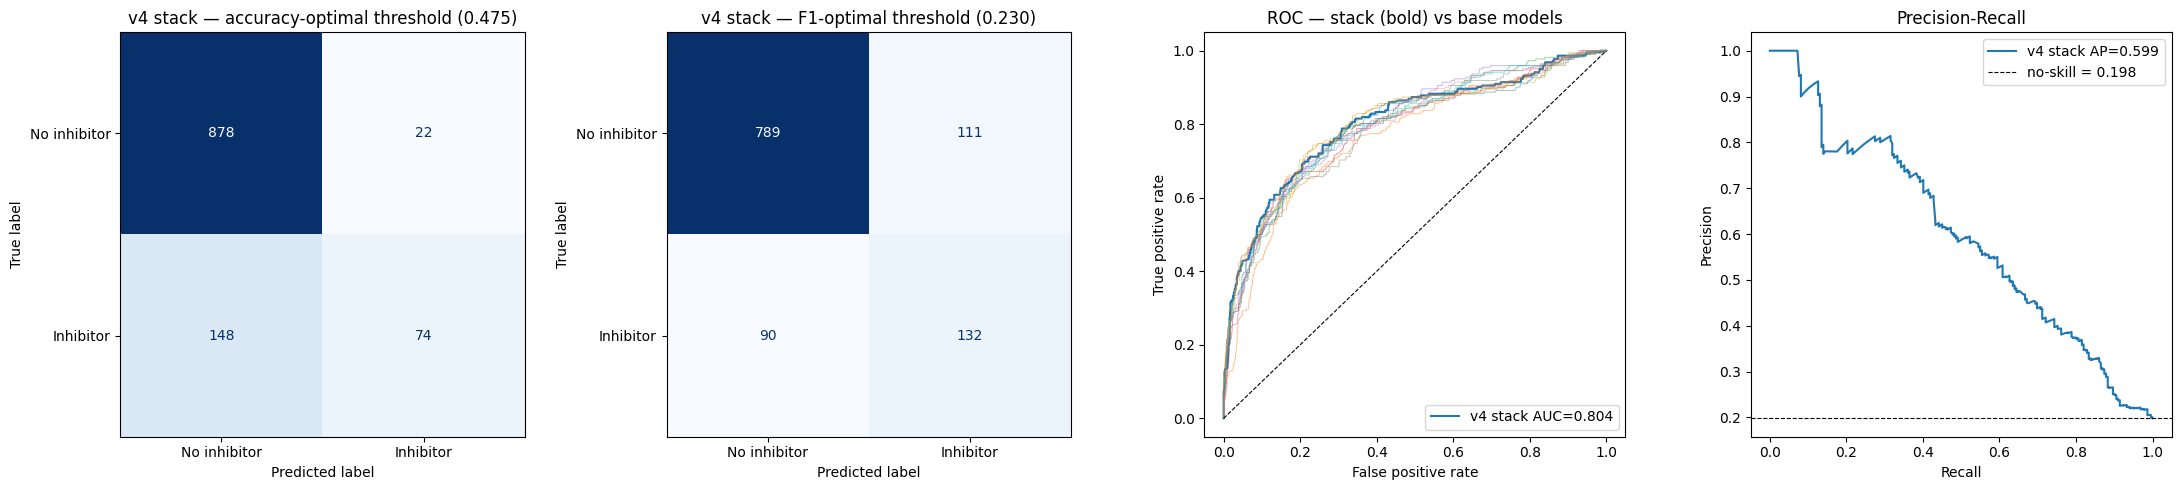

In [6]:
# ============================================================
# v4.6  CONFUSION MATRICES + ROC / PR CURVES
# ============================================================
fig, ax = plt.subplots(1, 4, figsize=(22, 5))
for i, (lab, t) in enumerate([("accuracy-optimal", thr_acc), ("F1-optimal", thr_f1)]):
    ConfusionMatrixDisplay(confusion_matrix(yt, (p_test >= t).astype(int)),
                           display_labels=["No inhibitor", "Inhibitor"]).plot(ax=ax[i], colorbar=False, cmap="Blues")
    ax[i].set_title(f"v4 stack — {lab} threshold ({t:.3f})")
fpr, tpr, _ = roc_curve(yt, p_test)
ax[2].plot(fpr, tpr, label=f"v4 stack AUC={roc_auc_score(yt, p_test):.3f}")
for n in names:
    f_, t_, _ = roc_curve(yt, TEST[n]); ax[2].plot(f_, t_, lw=0.7, alpha=0.45)
ax[2].plot([0, 1], [0, 1], "k--", lw=0.8); ax[2].set_xlabel("False positive rate"); ax[2].set_ylabel("True positive rate")
ax[2].set_title("ROC — stack (bold) vs base models"); ax[2].legend(loc="lower right")
pr_, rc_, _ = precision_recall_curve(yt, p_test)
ax[3].plot(rc_, pr_, label=f"v4 stack AP={average_precision_score(yt, p_test):.3f}")
ax[3].axhline(yt.mean(), color="k", ls="--", lw=0.8, label=f"no-skill = {yt.mean():.3f}")
ax[3].set_xlabel("Recall"); ax[3].set_ylabel("Precision"); ax[3].set_title("Precision-Recall"); ax[3].legend()
plt.tight_layout(); plt.show()

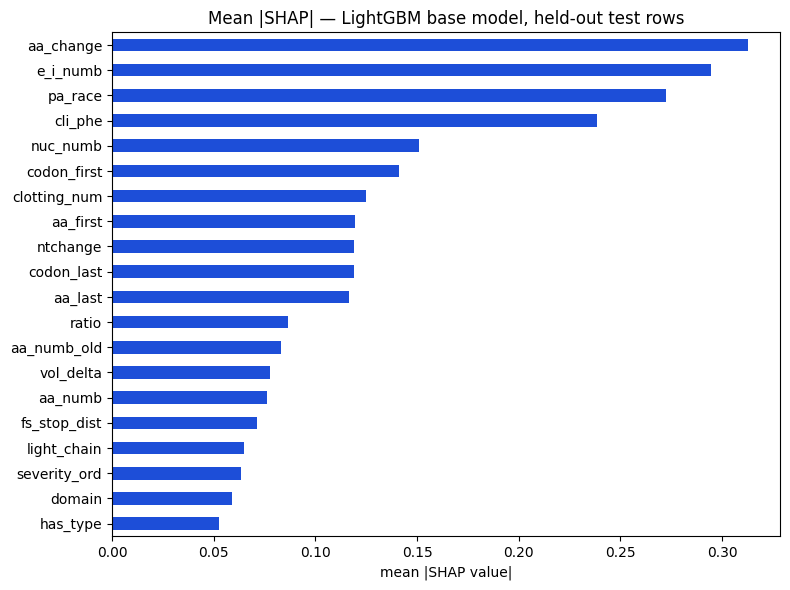

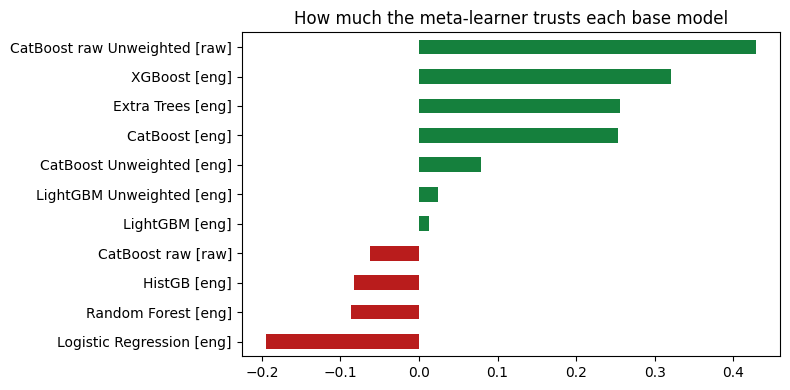

In [7]:
# ============================================================
# v4.7  EXPLAINABILITY — SHAP ON THE LIGHTGBM BASE MODEL
# ============================================================
try:
    import shap
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap"]); import shap

Xd_e, Xt_e = ENG.iloc[dev_idx].reset_index(drop=True), ENG.iloc[test_idx].reset_index(drop=True)
A_e, (B_e,) = native_frames(Xd_e, [Xt_e])
lgb = LGBMClassifier(n_estimators=700, learning_rate=0.02, num_leaves=15, min_child_samples=25, subsample=0.8,
                     subsample_freq=1, colsample_bytree=0.6, reg_lambda=3.0, cat_smooth=20, min_data_per_group=30,
                     n_jobs=N_JOBS, verbose=-1, random_state=RS).fit(A_e, yd)
sv = shap.TreeExplainer(lgb).shap_values(B_e)
sv = sv[1] if isinstance(sv, list) else sv
imp = pd.Series(np.abs(sv).mean(0), index=B_e.columns).sort_values(ascending=False)
plt.figure(figsize=(8, 6)); imp.head(20)[::-1].plot.barh(color="#1d4ed8")
plt.title("Mean |SHAP| — LightGBM base model, held-out test rows"); plt.xlabel("mean |SHAP value|")
plt.tight_layout(); plt.show()
w = pd.Series(meta.coef_[0], index=names).sort_values()
plt.figure(figsize=(8, 4)); w.plot.barh(color=["#b91c1c" if v < 0 else "#15803d" for v in w])
plt.title("How much the meta-learner trusts each base model"); plt.tight_layout(); plt.show()